<div dir="rtl">

# חיזוי פרקינסון מ־EEG במנוחה — ניתוח נתונים מחקרי (EDA)

**מטרת המחברת:** להכיר את הנתונים לעומק לפני כל מודל. נבדוק מה המשמעות של כל עמודה, איך הערכים מתפלגים, איפה חסרים נתונים, מה עלול להטעות מסווג של חולים (PD) מול בריאים (HC), ואיך פיצ'רי ה־EEG מתנהגים לאורך ההקלטה ובאזורי המוח השונים.

**מקורות הנתונים**

| קובץ | רמת פירוט | תוכן |
|---|---|---|
| `participants.csv` | שורה לכל נבדק | דאטהסט מקור, מזהה נבדק, קבוצה (PD / HC), גיל, מין, MoCA, UPDRS-III |
| `resting_state_eeg_segment_wise_features_*.csv` | שורה לכל נבדק × מקטע של 10 שניות × אלקטרודה | 27 פיצ'רי EEG שחושבו לכל מקטע ואלקטרודה |
| `Electrode_to_Brain_Region_Map.xlsx` | שורה לכל אלקטרודה | צד המוח (Hemisphere) והאונה (Lobe) של כל אלקטרודה, שיחד מגדירים את אזור המוח |
| `head_map_regions.png` | תמונה | תבנית של ראש במבט מלמעלה, מחולקת ל־13 אזורי המוח. משמשת למפות הראש בסעיף 7.8 |

**תוכן העניינים**

1. הגדרות ראשוניות
2. טעינת הנתונים הגולמיים
3. הכנת הנתונים — בניית טבלה מאוחדת
4. קבוצות העמודות בטבלה המאוחדת ואזורי המוח
5. הפיצ'רים הקליניים (ברמת נבדק)
6. עמודת הזמן (`onset_s`)
7. פיצ'רי ה־EEG
8. התנהגות פיצ'רי ה־EEG לאורך הזמן לפי תתי־קבוצות (מין × קבוצה × עשור גילאים)
9. סיכום הממצאים

> הגרפים, הפלטים המודפסים וההערות בקוד נשארו באנגלית, כי matplotlib לא מציג טקסט בעברית כראוי.

</div>

<div dir="rtl">

---
## 1. הגדרות ראשוניות

</div>

In [1]:
import numpy as np
import pandas as pd

In [2]:
import warnings

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
import seaborn as sns
from scipy import stats

# nanmean / polyfit on all-NaN slices raise RuntimeWarnings that are expected here
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

# ---------- Plot style ----------
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'legend.frameon': False, 'lines.linewidth': 2,
})

# Fixed colours: an entity always keeps the same colour throughout the notebook
GROUP_COLORS = {'HC': '#2a78d6', 'PD': '#eb6834'}        # healthy controls = blue, Parkinson's = orange
LABS_TO_NAMES = {'ds007526': 'LEMON', 'ds004584': 'Iowa'}   # dataset code -> lab name
SITE_COLORS = {LABS_TO_NAMES['ds004584']: '#1baf7a', LABS_TO_NAMES['ds007526']: '#eda100'}   # keyed by lab name
SEX_LINESTYLES = {'F': '-', 'M': '--'}                     # sex is encoded by line style, not colour
DIVERGING_CMAP = LinearSegmentedColormap.from_list('hc_pd', ['#1c5cab', '#86b6ef', '#efeeea', '#f3a27f', '#c2461a'])
SEQUENTIAL_CMAP = 'Blues'

<div dir="rtl">

---
## 2. טעינת הנתונים הגולמיים

הקבצים נטענים לפי מבנה התיקיות הבא, ביחס לתיקייה שבה נמצאת המחברת:

</div>

<div dir="ltr">

```
EEG-EDA.ipynb
data/
    participants.csv
    resting_state_eeg_segment_wise_features_171126.csv
    Electrode_to_Brain_Region_Map.xlsx
images/
    head_map_regions.png
src/
    eeg_data_prep.py
```

</div>

<div dir="rtl">


שמות התיקיות מוגדרים בקבועים `DATA_DIR` ו־`IMAGES_DIR` בתא הטעינה, כך שאם מבנה התיקיות ישתנה, מספיק לעדכן אותם שם. קובץ ה־Excel ממפה כל אלקטרודה לצד המוח ולאונה. שתי העמודות האלה יחד הן שם האזור (למשל `Left Frontal`). התמונה `head_map_regions.png` היא תבנית הראש שעליה מוצגות מפות האזורים בסעיף 7.8.

</div>

In [3]:
from pathlib import Path

DATA_DIR = Path('data')       # participants.csv, the EEG features CSV, the electrode-to-region Excel map
IMAGES_DIR = Path('images')   # head_map_regions.png

participants_df = pd.read_csv(DATA_DIR / 'participants.csv')
eeg_df = pd.read_csv(DATA_DIR / 'resting_state_eeg_segment_wise_features_171126.csv')
region_map_df = pd.read_excel(DATA_DIR / 'Electrode_to_Brain_Region_Map.xlsx')
head_map_image = plt.imread(IMAGES_DIR / 'head_map_regions.png')   # head template for the brain-region maps (7.8)

In [4]:
print(f'participants_df: {participants_df.shape[0]:>7,} rows x {participants_df.shape[1]} columns')
print(f'eeg_df:          {eeg_df.shape[0]:>7,} rows x {eeg_df.shape[1]} columns')
display(participants_df.head())
print(f'region_map_df:   {region_map_df.shape[0]:>7,} rows x {region_map_df.shape[1]} columns')
display(eeg_df.head())
display(region_map_df)

participants_df:     293 rows x 8 columns
eeg_df:          104,310 rows x 34 columns


,dataset,participant_id,source_subject_id,group,age,sex,moca,updrs_part_iii
0,ds007526,sub-001,HC0001,HC,42,M,30.0,0.0
1,ds007526,sub-002,HC0003,HC,60,M,27.0,2.0
2,ds007526,sub-003,HC0004,HC,60,F,27.0,0.0
3,ds007526,sub-004,HC0005,HC,72,M,25.0,1.0
4,ds007526,sub-005,HC0006,HC,47,M,NaN,NaN


region_map_df:        19 rows x 3 columns


,dataset,subject,group,segment_index,onset_s,duration_s,electrode,HFD,LZC,PermEn,alpha_relative_bandpower,beta_relative_bandpower,delta_relative_bandpower,fooof_alpha_bw,fooof_alpha_cf,fooof_alpha_pw,fooof_beta_bw,fooof_beta_cf,fooof_beta_pw,fooof_delta_bw,fooof_delta_cf,fooof_delta_pw,fooof_exponent,fooof_gamma_bw,fooof_gamma_cf,fooof_gamma_pw,fooof_offset,fooof_theta_bw,fooof_theta_cf,fooof_theta_pw,gamma_relative_bandpower,theta_relative_bandpower,total_bandpower,qc_segment_ptp_max_uv
0,ds004584,sub-001,PD,0,0,10,Fp1,1.738864,0.641142,1.106134,0.071891,0.364888,0.250089,NaN,NaN,NaN,4.727951,26.525120,0.543648,7.260314,2.952035,0.435371,0.392689,1.000000,31.350599,0.542413,0.063344,NaN,NaN,NaN,0.197154,0.115979,37.367744,85.98204
1,ds004584,sub-001,PD,0,0,10,Fp2,1.772189,0.668233,1.085065,0.055239,0.446066,0.159356,NaN,NaN,NaN,1.000000,24.370758,0.547705,NaN,NaN,NaN,0.332867,1.000000,30.160997,0.584518,0.570090,NaN,NaN,NaN,0.259392,0.079947,95.246565,85.98204
2,ds004584,sub-001,PD,0,0,10,F7,1.696402,0.627597,1.091264,0.092578,0.436553,0.211992,NaN,NaN,NaN,1.000000,29.869566,0.572073,NaN,NaN,NaN,0.524674,NaN,NaN,NaN,0.651218,1.000000,7.794166,0.245394,0.144509,0.114369,62.577739,85.98204
3,ds004584,sub-001,PD,0,0,10,F3,1.694921,0.659202,1.089884,0.137906,0.357513,0.129165,1.0,9.576626,0.563726,1.258279,23.558619,0.539385,NaN,NaN,NaN,0.127662,1.384582,30.397547,0.401932,-0.134824,5.782855,5.175370,0.378212,0.203983,0.171433,32.168634,85.98204
4,ds004584,sub-001,PD,0,0,10,Fz,1.621079,0.591476,1.099327,0.170057,0.303835,0.214121,1.0,9.785271,0.489629,2.072816,23.021864,0.492531,NaN,NaN,NaN,0.726761,NaN,NaN,NaN,0.507320,1.000000,6.793515,0.464853,0.118776,0.193211,30.697709,85.98204


,Electrode Name,Hemisphere \n(Brain side),Lobe \n(Brain Region)
0,Fp1,Left,Frontal
1,Fp2,Right,Frontal
2,F7,Left,Frontal
3,F3,Left,Frontal
4,Fz,Midline,Frontal
5,F4,Right,Frontal
6,F8,Right,Frontal
7,T7,Left,Temporal
8,C3,Left,Central
9,Cz,Midline,Central


<div dir="rtl">

קובץ ה־EEG הוא בפורמט **ארוך** (long format): כל שורה היא צירוף אחד של *(נבדק, מקטע של 10 שניות, אלקטרודה)*. כדי לקבל שורה אחת לכל *(נבדק, מקטע)*, צריך להפוך את האלקטרודות לעמודות.

</div>

<div dir="rtl">

---
## 3. הכנת הנתונים — בניית טבלה מאוחדת

שני דאטהסטי המקור, **Iowa** (`ds004584`) ו־**LEMON** (`ds007526`) מ־OpenNeuro, ממספרים את הנבדקים שלהם החל מ־`sub-001`. לכן מזהה הנבדק לבדו **אינו ייחודי**. נבנה מזהה מספרי אחד שמשלב את שניהם:

`ds007526` + `sub-001` → `7526` + `001` → **`7526001`**

(את דאטהסט המקור של כל נבדק אפשר תמיד לשחזר כ־`external_participant_id // 1000`.)

> **הקוד של חלק זה נמצא בקובץ [`src/eeg_data_prep.py`](src/eeg_data_prep.py)**, בתיקייה `src` שבתיקיית המחברת. הקובץ מכיל את פונקציות העזר ואת המחלקה `EEGDataPreparer`, שבה מתודה לכל אחד מתת־הסעיפים 3.2–3.5. כאן במחברת מריצים את השלבים אחד־אחד, כדי שאפשר יהיה לראות ולהסביר כל שלב. המחלקה לא משנה את הטבלאות הגולמיות, כי היא עובדת על עותקים שלהן.
>
> **בשלב המודלים** מריצים את כל הכנת הנתונים בשורה אחת. המתודה `run()` מריצה ברצף את כל השלבים של חלק 3 (3.2–3.5) ומחזירה את `full_df`:

</div>

<div dir="ltr">

```python
from src.eeg_data_prep import EEGDataPreparer
full_df = EEGDataPreparer(participants_df, eeg_df).run()
```

</div>

<div dir="rtl">

### 3.1 פונקציות עזר

</div>

In [5]:
from src.eeg_data_prep import (EEGDataPreparer, EXTERNAL_PARTICIPANT_ID_COLUMN_NAME,
                               create_external_participant_id, split_numerical_by_category)

prep = EEGDataPreparer(participants_df, eeg_df)

<div dir="rtl">

### 3.2 טבלת הנבדקים

מחליפים את `dataset` ואת `participant_id` במזהה המאוחד, ומסירים את `source_subject_id`. זה הקוד המקורי של המעבדה (למשל `HC0001`), ואין בו צורך לניתוח.

</div>

In [6]:
participants_df_with_ext_id = prep.prepare_participants()

<div dir="rtl">

### 3.3 טבלת ה־EEG: מפורמט ארוך לרחב

* לכל המקטעים חייב להיות אותו משך. כך אפשר לשמור את המשך פעם אחת כקבוע ולא כעמודה.
* `group` מוסרת כי היא כבר קיימת בטבלת הנבדקים. `segment_index` מיותרת, כי היא נגזרת מ־`onset_s` (`onset_s = segment_index × duration`).
* כל צירוף של *(אלקטרודה, פיצ'ר)* הופך לעמודה נפרדת בשם `<electrode>_<feature>`, למשל `Fp1_HFD`. בתוצאה יש שורה לכל *(נבדק, תחילת מקטע)*.

</div>

In [7]:
eeg_df_wide_version = prep.prepare_eeg()
EEG_RECORDING_DURATION = prep.eeg_recording_duration
eeg_df_with_ext_id = prep.eeg_df_with_ext_id

<div dir="rtl">

### 3.4 בדיקת שפיות — מספר העמודות הרחבות

מספר עמודות ה־EEG הרחבות צריך להיות שווה ל־*(מספר האלקטרודות המרבי לנבדק) × (מספר סוגי הפיצ'רים)*.

</div>

In [8]:
prep.validate_wide_columns()
eeg_features_types = prep.eeg_features_types

<div dir="rtl">

### 3.5 מיזוג לטבלה אחת

Inner join לפי מזהה הנבדק: כל שורה ב־`full_df` היא מקטע אחד של 10 שניות של נבדק אחד. בשורה יש את הנתונים הקליניים של הנבדק ואת כל פיצ'רי ה־EEG של אותו מקטע.

אחרי המיזוג, `merge_summary()` בודקת את התוצאה: משך המקטע, גודל הטבלה, מספר הנבדקים, וכמה נבדקים אבדו ב־inner join (בלי EEG או בלי נתונים קליניים). המתודה גם מחזירה את המספרים ואת המזהים של הנבדקים שאבדו, כך שאפשר להשתמש בה גם בהמשך.

</div>

In [9]:
full_df = prep.merge()

In [10]:
prep.merge_summary()
full_df.head()

Segment duration: 10 s
full_df: 5,490 rows (subject x segment) x 519 columns
Subjects in full_df: 293
Subjects lost in the inner join — no EEG: 0, no clinical data: 0


,group,age,sex,moca,updrs_part_iii,onset_s,Fp1_HFD,Fp2_HFD,F7_HFD,F3_HFD,Fz_HFD,F4_HFD,F8_HFD,T7_HFD,C3_HFD,Cz_HFD,C4_HFD,T8_HFD,P7_HFD,P3_HFD,Pz_HFD,P4_HFD,P8_HFD,O1_HFD,O2_HFD,Fp1_LZC,Fp2_LZC,F7_LZC,F3_LZC,Fz_LZC,...,C3_total_bandpower,Cz_total_bandpower,C4_total_bandpower,T8_total_bandpower,P7_total_bandpower,P3_total_bandpower,Pz_total_bandpower,P4_total_bandpower,P8_total_bandpower,O1_total_bandpower,O2_total_bandpower,Fp1_qc_segment_ptp_max_uv,Fp2_qc_segment_ptp_max_uv,F7_qc_segment_ptp_max_uv,F3_qc_segment_ptp_max_uv,Fz_qc_segment_ptp_max_uv,F4_qc_segment_ptp_max_uv,F8_qc_segment_ptp_max_uv,T7_qc_segment_ptp_max_uv,C3_qc_segment_ptp_max_uv,Cz_qc_segment_ptp_max_uv,C4_qc_segment_ptp_max_uv,T8_qc_segment_ptp_max_uv,P7_qc_segment_ptp_max_uv,P3_qc_segment_ptp_max_uv,Pz_qc_segment_ptp_max_uv,P4_qc_segment_ptp_max_uv,P8_qc_segment_ptp_max_uv,O1_qc_segment_ptp_max_uv,O2_qc_segment_ptp_max_uv
external_participant_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
7526001,HC,42,M,30.0,0.0,0,1.408003,1.394415,1.429929,1.395737,1.382837,1.389804,1.377199,1.449185,1.425086,1.370373,1.357879,1.387650,1.376636,1.384079,1.327855,1.335315,1.376797,1.471741,1.398312,0.469569,0.446993,0.532780,0.519235,0.501174,...,3.240260,8.757506,8.505585,10.106809,7.615705,8.579509,11.996506,8.799328,8.623972,7.439509,8.677579,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224,46.013224
7526001,HC,42,M,30.0,0.0,10,1.448971,1.447964,1.430864,1.409868,1.388312,1.436278,1.424971,1.489827,1.491927,1.401524,1.383004,1.432340,1.425606,1.446514,1.370570,1.351618,1.398128,1.455253,1.400730,0.465054,0.474084,0.465054,0.397327,0.514720,...,2.812990,7.265784,6.547902,9.902145,5.473442,5.737857,10.687468,8.013049,7.444204,7.492379,7.506661,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258,30.723258
7526001,HC,42,M,30.0,0.0,20,1.401053,1.394617,1.426379,1.401356,1.367821,1.374970,1.356933,1.445118,1.432451,1.358543,1.358553,1.352140,1.348913,1.351703,1.287848,1.320380,1.371490,1.418008,1.377368,0.437963,0.469569,0.492144,0.483114,0.519235,...,4.062646,10.367093,9.258331,14.893392,8.753872,8.885158,18.456916,10.143090,9.207321,8.275856,9.140502,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715,38.155715
7526001,HC,42,M,30.0,0.0,30,1.428100,1.438823,1.394387,1.402881,1.385983,1.433217,1.408499,1.454371,1.464750,1.377824,1.364547,1.392749,1.414402,1.413349,1.358196,1.376297,1.406219,1.459273,1.401465,0.492144,0.550840,0.478599,0.492144,0.514720,...,5.627367,7.499944,6.772493,9.465419,7.272136,8.222417,17.048784,9.655962,8.205399,6.459204,8.102657,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843,76.632843
7526001,HC,42,M,30.0,0.0,40,1.419329,1.424145,1.425023,1.395687,1.363956,1.406309,1.422484,1.434843,1.432930,1.384347,1.368844,1.418201,1.375047,1.374603,1.342943,1.345704,1.397869,1.412513,1.393122,0.505690,0.478599,0.514720,0.510205,0.496659,...,2.955093,8.906504,7.057263,9.211795,6.992528,7.754183,11.696456,7.052338,6.396057,7.129532,6.857232,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543,31.903543


<div dir="rtl">

---
## 4. קבוצות העמודות בטבלה המאוחדת

ב־`full_df` יש שלושה סוגי עמודות, ונבחן כל סוג בנפרד:

| קבוצה | עמודות | משמעות |
|---|---|---|
| **קליניות** | חמש הראשונות: `group`, `age`, `sex`, `moca`, `updrs_part_iii` | קבועות לכל נבדק (חוזרות בכל שורת מקטע) |
| **זמן** | השישית: `onset_s` | זמן תחילת המקטע בתוך ההקלטה, בשניות |
| **EEG** | כל השאר: `<electrode>_<feature>` | 19 אלקטרודות × 27 סוגי פיצ'רים |

האינדקס הוא הנבדק (`external_participant_id`), ולכן כל נבדק מופיע במספר שורות כמספר המקטעים שלו.

**מה מייצגת שורה אחת.** כל שורה מכילה את פיצ'רי ה־EEG של נבדק אחד, שחושבו על חלון אחד באורך `EEG_RECORDING_DURATION` שניות (משך המקטע, מודפס בתא הבא). החלון מתחיל ב־`onset_s` ומסתיים ב־`onset_s + EEG_RECORDING_DURATION`. למשל, השורה עם `onset_s = 30` מכסה את השניות 30 עד 30 + `EEG_RECORDING_DURATION` בהקלטה של אותו נבדק. השורות של כל נבדק הן חלונות רצופים שאינם חופפים, ויחד הן מרכיבות את כל הקלטת המנוחה.

**`full_df` היא הטבלה שמנותחת במחברת הזו.** כל טבלה וכל גרף בהמשך מחושבים ממנה. טבלאות העזר (`subjects_df`, `subject_means`, `subject_region`, `region_segments` ועוד) הן רק תצוגות אחרות של `full_df`, למשל שורה לכל נבדק או ממוצע על הזמן לכל אלקטרודה. אין בהן מידע שאינו ב־`full_df`.

</div>

In [11]:
print(f'Each row of full_df = the EEG features of one subject over one window of EEG_RECORDING_DURATION = {EEG_RECORDING_DURATION} seconds')
print(f'Window of a row: [onset_s, onset_s + {EEG_RECORDING_DURATION}) seconds from the start of the recording')

Each row of full_df = the EEG features of one subject over one window of EEG_RECORDING_DURATION = 10 seconds
Window of a row: [onset_s, onset_s + 10) seconds from the start of the recording


In [12]:
CLINICAL_COLS = full_df.columns[:5].tolist()
TIME_COL = full_df.columns[5]
EEG_COLS = full_df.columns[6:].tolist()
assert TIME_COL == 'onset_s', TIME_COL

ELECTRODES = list(dict.fromkeys(eeg_df_with_ext_id['electrode']))   # keeps the original montage order (frontal -> occipital)
EEG_FEATURE_TYPES = list(eeg_features_types)
assert len(EEG_COLS) == len(ELECTRODES) * len(EEG_FEATURE_TYPES)

def eeg_col(electrode: str, feature: str) -> str:
    """Name of the wide column for a given electrode and feature type."""
    return f'{electrode}_{feature}'

def feature_of(col: str) -> str:
    """Feature type of a wide EEG column ('Fp1_HFD' -> 'HFD'). Electrode names contain no underscore."""
    return col.split('_', 1)[1]

print('Clinical columns :', CLINICAL_COLS)
print('Time column      :', TIME_COL)
print(f'EEG columns      : {len(EEG_COLS)} = {len(ELECTRODES)} electrodes x {len(EEG_FEATURE_TYPES)} feature types')
print('Electrodes       :', ELECTRODES)

Clinical columns : ['group', 'age', 'sex', 'moca', 'updrs_part_iii']
Time column      : onset_s
EEG columns      : 513 = 19 electrodes x 27 feature types
Electrodes       : ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']


<div dir="rtl">

### 4.1 משפחות הפיצ'רים של ה־EEG

27 סוגי הפיצ'רים מתחלקים לכמה משפחות. המשפחה חשובה לפירוש ההתפלגויות והקורלציות:

| משפחה | פיצ'רים | מה הם מודדים |
|---|---|---|
| מורכבות האות | `HFD` (Higuchi fractal dimension), `LZC` (Lempel-Ziv complexity), `PermEn` (permutation entropy) | עד כמה האות לא סדיר ולא צפוי |
| עוצמה יחסית בתדרים | `<band>_relative_bandpower` עבור δ, θ, α, β, γ | חלק העוצמה הכוללת שבכל תחום תדרים. חמשתם מסתכמים ל־1, ולכן **אינם בלתי תלויים** |
| עוצמה מוחלטת | `total_bandpower` | העוצמה הכוללת (µV²). ההתפלגות בעלת זנב כבד מאוד, ולכן מנותחת בסקאלה לוגריתמית |
| FOOOF — רכיב א־מחזורי | `fooof_offset`, `fooof_exponent` | "הרקע" מסוג 1/f של הספקטרום (גובה ושיפוע) |
| FOOOF — שיאים מחזוריים | `fooof_<band>_cf / pw / bw` | תדר המרכז, העוצמה והרוחב של השיא המחזורי שנמצא בכל תחום תדרים. **חסר כשלא זוהה שיא** |
| בקרת איכות | `qc_segment_ptp_max_uv` | המשרעת המרבית (peak-to-peak) במקטע. מדד לארטיפקטים, לא פיצ'ר פיזיולוגי |

</div>

In [13]:
BANDS = ['delta', 'theta', 'alpha', 'beta', 'gamma']
FEATURE_FAMILIES = {
    'Signal complexity':    ['HFD', 'LZC', 'PermEn'],
    'Relative band power':  [f'{b}_relative_bandpower' for b in BANDS],
    'Absolute power':       ['total_bandpower'],
    'FOOOF aperiodic':      ['fooof_offset', 'fooof_exponent'],
    'FOOOF periodic peaks': [f'fooof_{b}_{p}' for b in BANDS for p in ('cf', 'pw', 'bw')],
    'Quality control':      ['qc_segment_ptp_max_uv'],
}
FEATURES_ORDERED = [f for fam in FEATURE_FAMILIES.values() for f in fam]
assert sorted(FEATURES_ORDERED) == sorted(EEG_FEATURE_TYPES)

PHYSIO_FEATURES = [f for f in FEATURES_ORDERED if f != 'qc_segment_ptp_max_uv']   # everything except QC
LOG_FEATURES = ['total_bandpower', 'qc_segment_ptp_max_uv']                          # heavy-tailed -> log10 scale

<div dir="rtl">

### 4.2 אזורי המוח — מתוך קובץ המיפוי

19 האלקטרודות ממוקמות לפי שיטת 10-20 הסטנדרטית. אלקטרודות שכנות קולטות פעילות דומה, והרבה תופעות EEG הן אזוריות (למשל, אלפא חזקה במיוחד מעל הקורטקס העורפי).

את החלוקה לאזורים לוקחים מקובץ ה־Excel. **שם האזור** מורכב משתי העמודות שבקובץ: צד המוח (`Left` / `Midline` / `Right`) והאונה (`Frontal`, `Central`, `Temporal`, `Parietal`, `Occipital`). כך מתקבלים אזורים כמו `Left Frontal` או `Midline Parietal`. האזורים ממוינים מקדימת הראש לאחוריה (לפי האונה), ובתוך כל אונה משמאל לימין.

כל ניתוח אזורי בהמשך משתמש בחלוקה הזו. בנוסף לאזור, נשמרים גם האונה וצד המוח של כל אלקטרודה, כדי שאפשר יהיה לסכם גם לפיהם.

</div>

In [14]:
# The original headers contain line breaks ('Hemisphere \n(Brain side)'), so the columns are renamed by position
region_map = region_map_df.iloc[:, :3].copy()
region_map.columns = ['electrode', 'hemisphere', 'lobe']
region_map = region_map.apply(lambda col: col.astype(str).str.strip())
region_map['region'] = region_map['hemisphere'] + ' ' + region_map['lobe']   # region name = hemisphere + lobe

assert set(region_map['electrode']) == set(ELECTRODES), (
    f"electrodes in the map and in the EEG data differ: {set(region_map['electrode']) ^ set(ELECTRODES)}")
assert not region_map['electrode'].duplicated().any(), 'an electrode appears twice in the map'

# Display order: front -> back of the head (lobe), then left -> right (hemisphere), then the montage order
LOBE_ORDER = ['Frontal', 'Central', 'Temporal', 'Parietal', 'Occipital']
HEMISPHERE_ORDER = ['Left', 'Midline', 'Right']
LOBE_ORDER += [l for l in region_map['lobe'].unique() if l not in LOBE_ORDER]               # keep unknown lobes, if any
HEMISPHERE_ORDER += [h for h in region_map['hemisphere'].unique() if h not in HEMISPHERE_ORDER]
region_map = (region_map
              .assign(_lobe=region_map['lobe'].map(LOBE_ORDER.index),
                      _hemi=region_map['hemisphere'].map(HEMISPHERE_ORDER.index),
                      _montage=region_map['electrode'].map(ELECTRODES.index))
              .sort_values(['_lobe', '_hemi', '_montage'])
              .drop(columns=['_lobe', '_hemi', '_montage'])
              .reset_index(drop=True))

REGIONS = {region: g['electrode'].tolist() for region, g in region_map.groupby('region', sort=False)}
REGION_ORDER = list(REGIONS)
ELECTRODES_BY_REGION = region_map['electrode'].tolist()
ELECTRODE_REGION = dict(zip(region_map['electrode'], region_map['region']))
REGION_LOBE = dict(zip(region_map['region'], region_map['lobe']))
REGION_HEMISPHERE = dict(zip(region_map['region'], region_map['hemisphere']))

print(f'{len(REGIONS)} brain regions (hemisphere x lobe):')
pd.DataFrame({'lobe': [REGION_LOBE[r] for r in REGION_ORDER],
              'hemisphere': [REGION_HEMISPHERE[r] for r in REGION_ORDER],
              'electrodes': [', '.join(REGIONS[r]) for r in REGION_ORDER],
              'n_electrodes': [len(REGIONS[r]) for r in REGION_ORDER]}, index=pd.Index(REGION_ORDER, name='region'))

13 brain regions (hemisphere x lobe):


,lobe,hemisphere,electrodes,n_electrodes
region,,,,
Left Frontal,Frontal,Left,"Fp1, F7, F3",3
Midline Frontal,Frontal,Midline,Fz,1
Right Frontal,Frontal,Right,"Fp2, F4, F8",3
Left Central,Central,Left,C3,1
Midline Central,Central,Midline,Cz,1
Right Central,Central,Right,C4,1
Left Temporal,Temporal,Left,T7,1
Right Temporal,Temporal,Right,T8,1
Left Parietal,Parietal,Left,"P7, P3",2


<div dir="rtl">

### 4.3 טבלה ברמת נבדק

הערכים הקליניים חוזרים בכל שורת מקטע. חישוב סטטיסטיקות ישירות על `full_df` היה נותן משקל עודף לנבדקים עם הקלטה ארוכה יותר. לכן כל ניתוח קליני נעשה על **שורה אחת לכל נבדק** (`subjects_df`), ומוסיפים כמה עמודות עזר שמשמשות לאורך ה־EDA:

* `site` — מאיזה משני דאטהסטי המקור הגיע הנבדק (ראו את ההערה בהמשך). זו **לא** עמודה למודל, אבל היא משתנה מבלבל (confounder) אפשרי.
* `n_segments`, `recording_length_s` — כמות ה־EEG שיש לכל נבדק.
* `age_bin` — עשור הגילאים (למשל `60-69`), לניתוח תתי־הקבוצות בסעיף 8.

> **מה הכוונה ב"אתר" (site).** `full_df` היא טבלה אחת, אבל הנבדקים שלה הוקלטו בשני מחקרים עצמאיים שפורסמו ב־OpenNeuro: **Iowa** ו־**LEMON**. בנתונים הגולמיים הם מופיעים לפי הערכים של עמודת `dataset` המקורית: `ds004584` הוא Iowa ו־`ds007526` הוא LEMON. המיפוי מוגדר במילון `LABS_TO_NAMES` בתא ההגדרות, והעמודה `site` נבנית ישירות עם שמות המעבדות. לכן מכאן והלאה, בהסברים, בטבלאות ובגרפים, המעבדות מופיעות בשמן בלבד. כל מחקר נערך בידי קבוצת מחקר אחרת (מעבדה, או "אתר"), עם מערכת EEG משלה, פרוטוקול הקלטה משלה, אורך הקלטה משלה ואוכלוסיית נבדקים משלה. כשנבנה המזהה המאוחד בסעיף 3, עמודת `dataset` נכנסה לתוך המזהה: ארבע הספרות הראשונות שלו הן הדאטהסט (`4584…` או `7526…`). לכן המזהה עדיין מראה מאיזה מחקר הגיעה כל שורה ב־`full_df`, ו־`site` מפענחת אותו (`external_participant_id // 1000`) ומתרגמת את הקוד לשם המעבדה.
>
> **אפקט אתר** הוא הבדל שיטתי בין הנבדקים של שני האתרים שלא נגרם מהמחלה. למשל, מגבר EEG אחד שנותן ערכי עוצמה גבוהים יותר מהשני. זה חשוב כי גם יחס החולים לבריאים, הגילאים ואורכי ההקלטה שונים בין האתרים. מודל שיאומן על `full_df` עלול ללמוד לזהות את האתר במקום את הפרקינסון. לכן ה־EDA בודק את התוצאות שוב ושוב בחלוקה לפי אתר (5.3, 6, 7.7).

</div>

In [15]:
AGE_BIN_WIDTH = 10

def site_from_id(ext_id: int) -> str:
    return f'ds00{ext_id // 1000}'

def age_bin_label(age: float) -> str:
    low = int(age // AGE_BIN_WIDTH * AGE_BIN_WIDTH)
    return f'{low}-{low + AGE_BIN_WIDTH - 1}'

segment_counts = full_df.groupby(level=0)[TIME_COL].agg(n_segments='count', last_onset_s='max')
subjects_df = full_df[CLINICAL_COLS].groupby(level=0).first().join(segment_counts)
subjects_df['recording_length_s'] = subjects_df['last_onset_s'] + EEG_RECORDING_DURATION
subjects_df['site'] = [LABS_TO_NAMES[site_from_id(i)] for i in subjects_df.index]   # lab name, e.g. 'Iowa'
subjects_df['age_bin'] = subjects_df['age'].apply(age_bin_label)
subjects_df.index.name = EXTERNAL_PARTICIPANT_ID_COLUMN_NAME

AGE_BIN_ORDER = sorted(subjects_df['age_bin'].unique(), key=lambda s: int(s.split('-')[0]))
GROUP_ORDER = ['HC', 'PD']
SEX_ORDER = ['F', 'M']

# Subject metadata repeated per segment row (aligned with full_df), handy for segment-level plots
segment_meta = subjects_df[['group', 'sex', 'age_bin', 'site']].reindex(full_df.index)

print(f'{len(subjects_df)} subjects')
subjects_df.head()

293 subjects


,group,age,sex,moca,updrs_part_iii,n_segments,last_onset_s,recording_length_s,site,age_bin
external_participant_id,,,,,,,,,,
4584001,PD,80,M,19.0,28.0,27,260,270,Iowa,80-89
4584002,PD,81,M,17.0,25.0,31,300,310,Iowa,80-89
4584003,PD,68,F,26.0,10.0,24,230,240,Iowa,60-69
4584004,PD,80,M,22.0,10.0,25,240,250,Iowa,80-89
4584005,PD,56,M,21.0,13.0,23,220,230,Iowa,50-59


<div dir="rtl">

---
## 5. הפיצ'רים הקליניים (ברמת נבדק)

### 5.1 טיפוסי נתונים וערכים חסרים

</div>

In [16]:
display(subjects_df[CLINICAL_COLS].dtypes.to_frame('dtype').T)

missing_clinical = subjects_df[[c for c in CLINICAL_COLS if c != 'group']].isna().groupby([subjects_df['site'], subjects_df['group']]).sum()
missing_clinical['n_subjects'] = subjects_df.groupby(['site', 'group']).size()
print('Number of missing values per site and group:')
missing_clinical

,group,age,sex,moca,updrs_part_iii
dtype,str,int64,str,float64,float64


Number of missing values per site and group:


age  sex  moca  updrs_part_iii  n_subjects
site  group                                            
Iowa  HC       0    0     0              49          49
      PD       0    0     0               0         100
LEMON HC       0    0     1               2          28
      PD       0    0     3               3         116

<div dir="rtl">

> **הערה:** UPDRS-III חסר (כמעט) לכל הבריאים ב־Iowa, כי האתר הזה לא העריך את קבוצת הביקורת. UPDRS-III מודד את חומרת הסימנים המוטוריים של המחלה, ולכן הוא **משתנה שמקודד כמעט את התווית** (PD מול HC). אסור להשתמש בו כפיצ'ר קלט לחיזוי פרקינסון. לכל היותר הוא יכול לשמש משתנה מטרה במשימה נפרדת של חיזוי חומרה.

</div>

In [17]:
NUMERIC_CLINICAL = ['age', 'moca', 'updrs_part_iii']
subjects_df.groupby('group')[NUMERIC_CLINICAL].describe().T.round(1)

group                   HC     PD
age            count  77.0  216.0
               mean   67.2   67.2
               std     9.0    8.9
               min    42.0   39.0
               25%    61.0   62.8
               50%    69.0   68.0
               75%    73.0   73.0
               max    86.0   86.0
moca           count  76.0  213.0
               mean   26.9   24.8
               std     1.9    3.6
               min    22.0    9.0
               25%    26.0   23.0
               50%    27.0   25.0
               75%    28.0   27.0
               max    30.0   30.0
updrs_part_iii count  26.0  213.0
               mean    1.4   19.0
               std     1.7   12.0
               min     0.0    1.0
               25%     0.0   10.0
               50%     1.0   17.0
               75%     2.0   26.0
               max     7.0   56.0

<div dir="rtl">

### 5.2 הרכב המדגם — קבוצה, מין, אתר ועשור גילאים

</div>

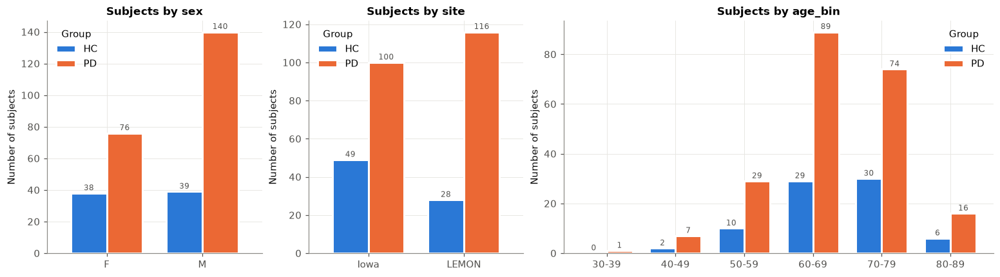

group
PD    216
HC     77


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 1, 2]}, constrained_layout=True)
for ax, col in zip(axes, ['sex', 'site', 'age_bin']):
    counts = pd.crosstab(subjects_df[col], subjects_df['group'])[GROUP_ORDER]
    if col == 'age_bin':
        counts = counts.reindex(AGE_BIN_ORDER, fill_value=0)
    counts.plot.bar(ax=ax, color=[GROUP_COLORS[g] for g in counts.columns], width=0.75,
                    edgecolor='white', linewidth=2, rot=0)
    for container in ax.containers:
        ax.bar_label(container, fontsize=8, color='#52514e', padding=1)
    ax.set_title(f'Subjects by {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Number of subjects')
    ax.legend(title='Group')
plt.show()

print(subjects_df['group'].value_counts().to_string())

In [19]:
print('Subjects per group x sex x age decade:')
pd.crosstab([subjects_df['group'], subjects_df['sex']], subjects_df['age_bin'], margins=True, margins_name='Total')

Subjects per group x sex x age decade:


age_bin    30-39  40-49  50-59  60-69  70-79  80-89  Total
group sex                                                 
HC    F        0      0      8     18     10      2     38
      M        0      2      2     11     20      4     39
PD    F        0      3      7     30     30      6     76
      M        1      4     22     59     44     10    140
Total          1      9     39    118    104     22    293

<div dir="rtl">

### 5.3 התפלגויות הגיל, ה־MoCA וה־UPDRS-III

שורה עליונה: היסטוגרמות לפי קבוצה (הקו המנוקד הוא החציון של הקבוצה). שורה תחתונה: אותם משתנים בחלוקה לפי אתר (דאטהסט מקור), כדי לבדוק אם שני החלקים של `full_df` דומים.

</div>

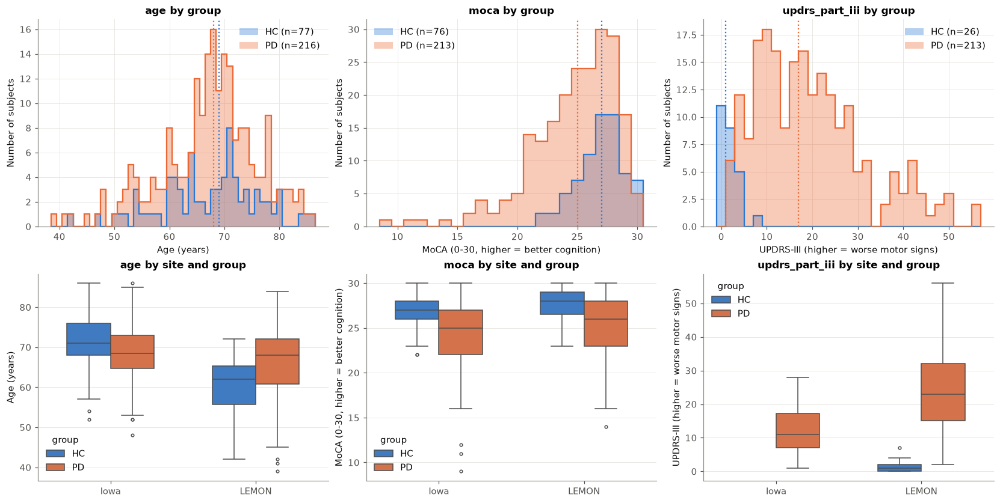

In [20]:
CLINICAL_LABELS = {'age': 'Age (years)', 'moca': 'MoCA (0-30, higher = better cognition)',
                   'updrs_part_iii': 'UPDRS-III (higher = worse motor signs)'}

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for j, col in enumerate(NUMERIC_CLINICAL):
    values = subjects_df[col].dropna()
    step = max(1, int((values.max() - values.min()) // 25))
    bins = np.arange(values.min(), values.max() + step + 1, step) - step / 2

    ax = axes[0, j]
    for g in GROUP_ORDER:
        vals = subjects_df.loc[subjects_df['group'] == g, col].dropna()
        ax.hist(vals, bins=bins, color=GROUP_COLORS[g], alpha=0.35, label=f'{g} (n={len(vals)})')
        ax.hist(vals, bins=bins, color=GROUP_COLORS[g], histtype='step', linewidth=1.5)
        ax.axvline(vals.median(), color=GROUP_COLORS[g], linestyle=':', linewidth=1.5)
    ax.set_title(f'{col} by group')
    ax.set_xlabel(CLINICAL_LABELS[col])
    ax.set_ylabel('Number of subjects')
    ax.legend()

    ax = axes[1, j]
    sns.boxplot(data=subjects_df, x='site', y=col, hue='group', hue_order=GROUP_ORDER, palette=GROUP_COLORS,
                width=0.6, fliersize=3, ax=ax)
    ax.set_title(f'{col} by site and group')
    ax.set_xlabel('')
    ax.set_ylabel(CLINICAL_LABELS[col])
plt.show()

<div dir="rtl">

**השוואה סטטיסטית בין חולים לבריאים.** מבחן Mann-Whitney U למשתנים המספריים (ללא הנחת נורמליות), ומבחן χ² למין. אלה בדיקות תיאוריות של האיזון בין הקבוצות: חוסר איזון בגיל או במין אומר שהמסווג עלול ללמוד גיל או מין במקום מחלה.

</div>

In [21]:
rows = []
for col in NUMERIC_CLINICAL:
    hc = subjects_df.loc[subjects_df['group'] == 'HC', col].dropna()
    pdg = subjects_df.loc[subjects_df['group'] == 'PD', col].dropna()
    _, p = stats.mannwhitneyu(pdg, hc)
    rows.append({'variable': col, 'n_HC': len(hc), 'median_HC': hc.median(),
                 'n_PD': len(pdg), 'median_PD': pdg.median(), 'test': 'Mann-Whitney U', 'p_value': p})

sex_table = pd.crosstab(subjects_df['sex'], subjects_df['group'])
chi2, p_sex, _, _ = stats.chi2_contingency(sex_table)
rows.append({'variable': 'sex (% male)', 'n_HC': sex_table['HC'].sum(),
             'median_HC': round(100 * sex_table.loc['M', 'HC'] / sex_table['HC'].sum(), 1),
             'n_PD': sex_table['PD'].sum(),
             'median_PD': round(100 * sex_table.loc['M', 'PD'] / sex_table['PD'].sum(), 1),
             'test': 'chi-square', 'p_value': p_sex})

pd.DataFrame(rows).set_index('variable').round({'p_value': 4})

,n_HC,median_HC,n_PD,median_PD,test,p_value
variable,,,,,,
age,77,69.0,216,68.0,Mann-Whitney U,0.9850
moca,76,27.0,213,25.0,Mann-Whitney U,0.0000
updrs_part_iii,26,1.0,213,17.0,Mann-Whitney U,0.0000
sex (% male),77,50.6,216,64.8,chi-square,0.0401


<div dir="rtl">

### 5.4 הקשרים בין המשתנים הקליניים

</div>

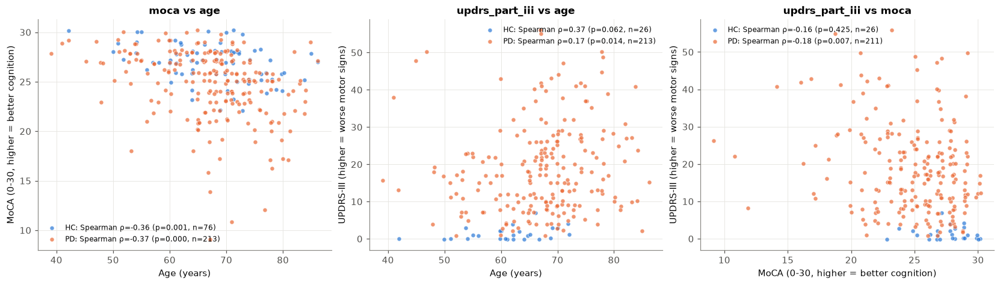

In [22]:
pairs = [('age', 'moca'), ('age', 'updrs_part_iii'), ('moca', 'updrs_part_iii')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
rng = np.random.default_rng(0)
for ax, (x, y) in zip(axes, pairs):
    for g in GROUP_ORDER:
        d = subjects_df.loc[subjects_df['group'] == g, [x, y]].dropna()
        rho, p = stats.spearmanr(d[x], d[y]) if len(d) > 2 else (np.nan, np.nan)
        jitter = rng.uniform(-0.25, 0.25, size=(len(d), 2))   # MoCA / UPDRS are integers -> jitter to reveal overlap
        ax.scatter(d[x] + jitter[:, 0], d[y] + jitter[:, 1], s=22, color=GROUP_COLORS[g], alpha=0.7,
                   edgecolor='white', linewidth=0.6, label=f'{g}: Spearman ρ={rho:.2f} (p={p:.3f}, n={len(d)})')
    ax.set_xlabel(CLINICAL_LABELS[x])
    ax.set_ylabel(CLINICAL_LABELS[y])
    ax.set_title(f'{y} vs {x}')
    ax.legend(fontsize=8, loc='best')
plt.show()

<div dir="rtl">

---
## 6. עמודת הזמן (`onset_s`)

כל שורה היא מקטע של 10 שניות, ו־`onset_s` הוא זמן תחילתו בשניות. כאן נבדוק כמה ארוכות ההקלטות, אם המקטעים רצופים (ללא פערים), וכמה נבדקים עדיין "זמינים" בכל נקודת זמן. הנקודה האחרונה חשובה לסעיף 8.

</div>

In [23]:
step = EEG_RECORDING_DURATION
contiguous = full_df.groupby(level=0)[TIME_COL].apply(
    lambda s: np.array_equal(np.sort(s.to_numpy()), np.arange(0, s.max() + step, step)))
print(f'Subjects whose segments are contiguous from 0 s (no gaps): {contiguous.sum()} / {len(contiguous)}')
print(f'Duplicate (subject, onset) rows: {full_df.reset_index().duplicated([EXTERNAL_PARTICIPANT_ID_COLUMN_NAME, TIME_COL]).sum()}')
print()
print('Recording length (s) per site and group:')
subjects_df.groupby(['site', 'group'])['recording_length_s'].describe()

Subjects whose segments are contiguous from 0 s (no gaps): 293 / 293
Duplicate (subject, onset) rows: 0

Recording length (s) per site and group:


count        mean        std    min    25%    50%    75%    max
site  group                                                                 
Iowa  HC      49.0  155.714286  46.188022  110.0  110.0  150.0  180.0  310.0
      PD     100.0  141.500000  44.865118  110.0  110.0  120.0  150.0  330.0
LEMON HC      28.0  230.000000   0.000000  230.0  230.0  230.0  230.0  230.0
      PD     116.0  230.000000   0.000000  230.0  230.0  230.0  230.0  230.0

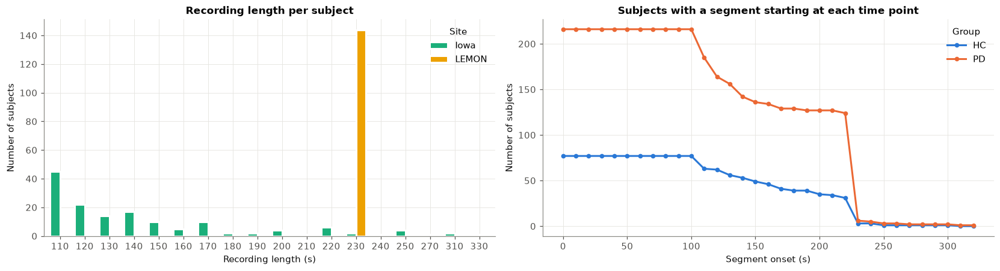

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)

ax = axes[0]
lengths = pd.crosstab(subjects_df['recording_length_s'], subjects_df['site'])
lengths.plot.bar(ax=ax, color=[SITE_COLORS[s] for s in lengths.columns], width=0.8, edgecolor='white', linewidth=2, rot=0)
ax.set_title('Recording length per subject')
ax.set_xlabel('Recording length (s)')
ax.set_ylabel('Number of subjects')
ax.legend(title='Site')

ax = axes[1]
available = (full_df.assign(group=segment_meta['group']).reset_index()
             .groupby([TIME_COL, 'group'])[EXTERNAL_PARTICIPANT_ID_COLUMN_NAME].nunique().unstack(fill_value=0))
for g in GROUP_ORDER:
    ax.plot(available.index, available[g], color=GROUP_COLORS[g], marker='o', markersize=4, label=g)
ax.set_title('Subjects with a segment starting at each time point')
ax.set_xlabel('Segment onset (s)')
ax.set_ylabel('Number of subjects')
ax.legend(title='Group')
plt.show()

<div dir="rtl">

> לכל הנבדקים ב־LEMON יש הקלטה באורך זהה בדיוק (230 שניות), ואילו ב־Iowa האורך משתנה (110–330 שניות). לכן הנבדקים שמאחורי כל נקודת זמן משתנים. עד כ־100 שניות כל הנבדקים תורמים. בין כ־110 ל־220 שניות תורמים כל נבדקי LEMON ורק חלק מנבדקי Iowa. אחרי 220 שניות נשארים רק מעט נבדקים מ־Iowa. לכן ממוצעים בנקודות זמן מאוחרות מבוססים על פחות נבדקים ונוטים לאתר אחד. סעיף 8 מטפל בזה בכך שהוא מציג רק נקודות זמן עם מספיק נבדקים.

</div>

<div dir="rtl">

---
## 7. פיצ'רי ה־EEG

### 7.1 ערכים חסרים

ערכים חסרים מופיעים רק בפיצ'רי השיאים המחזוריים של FOOOF. הם **אינם אקראיים**: ערך חסר כשהאלגוריתם לא מצא שיא מחזורי בתחום התדרים הזה, באותו מקטע ובאותה אלקטרודה. כלומר *עצם החוסר נושא מידע* (למשל "אין שיא אלפא"). זה חשוב כשנבחר בהמשך שיטת השלמה (imputation).

</div>

Features with no missing values at all: ['HFD', 'LZC', 'PermEn', 'delta_relative_bandpower', 'theta_relative_bandpower', 'alpha_relative_bandpower', 'beta_relative_bandpower', 'gamma_relative_bandpower', 'total_bandpower', 'fooof_offset', 'fooof_exponent', 'qc_segment_ptp_max_uv']


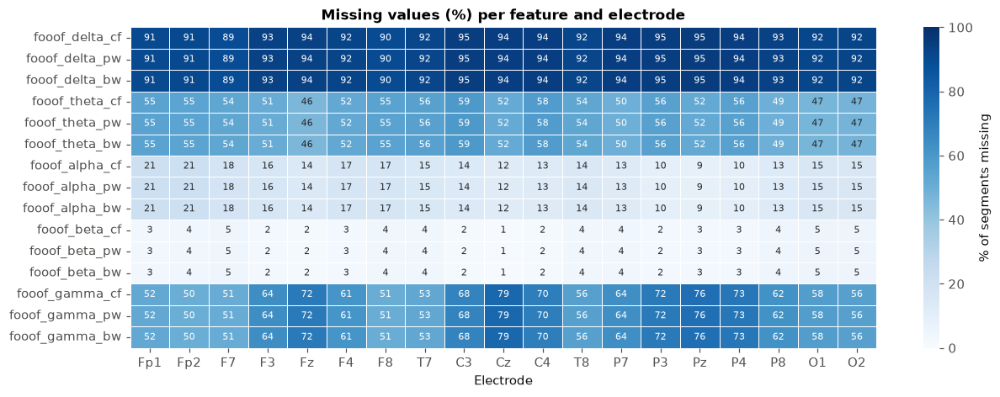

In [25]:
missing_eeg = pd.DataFrame(
    {e: [full_df[eeg_col(e, f)].isna().mean() * 100 for f in FEATURES_ORDERED] for e in ELECTRODES},
    index=FEATURES_ORDERED)
features_with_missing = missing_eeg.index[missing_eeg.max(axis=1) > 0]
print('Features with no missing values at all:', [f for f in FEATURES_ORDERED if f not in features_with_missing])

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(missing_eeg.loc[features_with_missing], cmap=SEQUENTIAL_CMAP, vmin=0, vmax=100, annot=True, fmt='.0f',
            annot_kws={'fontsize': 7}, linewidths=0.5, linecolor='white', cbar_kws={'label': '% of segments missing'}, ax=ax)
ax.set_title('Missing values (%) per feature and electrode')
ax.set_xlabel('Electrode')
ax.set_ylabel('')
plt.show()

<div dir="rtl">

האם שיעור ה"לא זוהה שיא" שונה בין חולים לבריאים? (אחוז הערכים החסרים מתוך כל צירופי המקטע × אלקטרודה, בממוצע על האלקטרודות.)

</div>

In [26]:
missing_cols = [eeg_col(e, f) for f in features_with_missing for e in ELECTRODES]
missing_by_group = pd.DataFrame({
    g: full_df.loc[segment_meta['group'] == g, missing_cols].isna().mean().groupby(feature_of).mean() * 100
    for g in GROUP_ORDER
}).reindex(features_with_missing)
missing_by_group['PD - HC'] = missing_by_group['PD'] - missing_by_group['HC']
missing_by_group.round(1)

,HC,PD,PD - HC
fooof_delta_cf,88.2,94.4,6.2
fooof_delta_pw,88.2,94.4,6.2
fooof_delta_bw,88.2,94.4,6.2
fooof_theta_cf,72.2,46.2,-26.0
fooof_theta_pw,72.2,46.2,-26.0
fooof_theta_bw,72.2,46.2,-26.0
fooof_alpha_cf,19.7,12.9,-6.8
fooof_alpha_pw,19.7,12.9,-6.8
fooof_alpha_bw,19.7,12.9,-6.8
fooof_beta_cf,1.7,3.8,2.0


<div dir="rtl">

### 7.2 עמודת בקרת האיכות

`qc_segment_ptp_max_uv` היא המשרעת המרבית (peak-to-peak) במקטע. קודם נבדוק אם היא באמת שונה בין אלקטרודות או שהיא ערך אחד לכל מקטע (זהה בכל האלקטרודות). אחר כך נבחן את ההתפלגות שלה. משרעות גבוהות מאוד מעידות בדרך כלל על ארטיפקטים: תנועה, מצמוצים או מגע לא טוב של אלקטרודה.

</div>

Segments in which the QC value is identical on all 19 electrodes: 100.0%

Share of segments whose max peak-to-peak amplitude exceeds a threshold:


,> 100 µV,> 150 µV,> 200 µV,> 500 µV
group,,,,
HC,23.0,12.7,8.3,1.4
PD,22.4,7.5,3.9,1.0


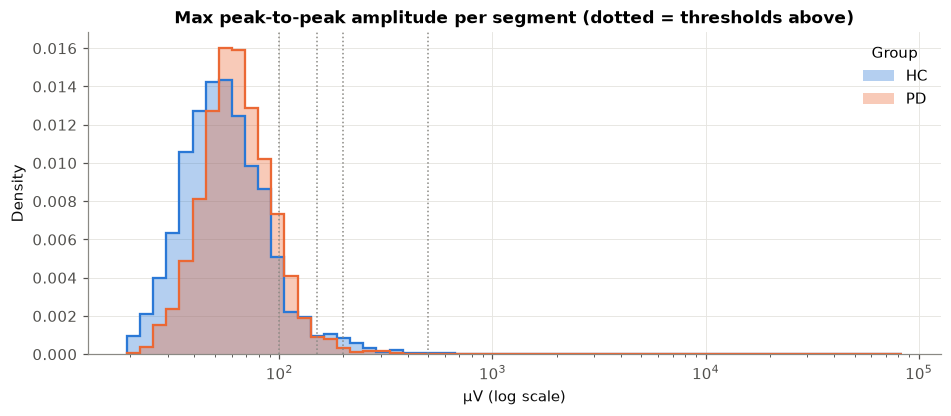

Subjects with the highest median segment amplitude:


,median,max,group,site,n_segments
external_participant_id,,,,,
4584139,346.1,515.4,HC,Iowa,17
4584048,336.4,3629.7,PD,Iowa,22
4584105,290.5,624.2,HC,Iowa,22
7526025,252.6,3885.0,HC,LEMON,23
4584104,216.0,274.1,HC,Iowa,20
4584116,206.0,309.6,HC,Iowa,11
4584068,188.9,364.6,PD,Iowa,11
4584117,178.0,364.6,HC,Iowa,17
7526065,176.6,848.3,PD,LEMON,23


In [27]:
qc_cols = [eeg_col(e, 'qc_segment_ptp_max_uv') for e in ELECTRODES]
share_identical = full_df[qc_cols].nunique(axis=1).eq(1).mean()
print(f'Segments in which the QC value is identical on all {len(ELECTRODES)} electrodes: {share_identical:.1%}')

qc = full_df[qc_cols[0]]
thresholds = [100, 150, 200, 500]
print('\nShare of segments whose max peak-to-peak amplitude exceeds a threshold:')
qc_table = pd.DataFrame({f'> {t} µV': qc.gt(t).groupby(segment_meta['group']).mean() * 100 for t in thresholds}).round(1)
display(qc_table)

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(np.log10(qc.min()), np.log10(qc.max()), 60)
for g in GROUP_ORDER:
    ax.hist(qc[segment_meta['group'] == g], bins=bins, color=GROUP_COLORS[g], alpha=0.35, density=True, label=g)
    ax.hist(qc[segment_meta['group'] == g], bins=bins, color=GROUP_COLORS[g], histtype='step', density=True, linewidth=1.5)
for t in thresholds:
    ax.axvline(t, color='#8a8984', linestyle=':', linewidth=1)
ax.set_xscale('log')
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_title('Max peak-to-peak amplitude per segment (dotted = thresholds above)')
ax.set_xlabel('µV (log scale)')
ax.set_ylabel('Density')
ax.legend(title='Group')
plt.show()

print('Subjects with the highest median segment amplitude:')
subject_qc = qc.groupby(level=0).agg(['median', 'max']).join(subjects_df[['group', 'site', 'n_segments']])
subject_qc.sort_values('median', ascending=False).head(10).round(1)

<div dir="rtl">

> אם ערך ה־QC זהה בכל האלקטרודות, אז 19 העמודות `*_qc_segment_ptp_max_uv` הן בפועל עמודה **אחת** שחוזרת 19 פעמים. היא שימושית לסינון מקטעים רעים, אבל בסט הפיצ'רים כדאי להשאיר אותה פעם אחת בלבד (או להסיר אותה).

### 7.3 ההתפלגות של כל סוג פיצ'ר

הערכים מאוחדים מכל המקטעים והאלקטרודות ומוצגים כצפיפות, כדי ששתי הקבוצות (בגדלים שונים) יהיו ברות השוואה. ציר ה־x נחתך בין האחוזון ה־0.5 לאחוזון ה־99.5, כדי שערכים קיצוניים לא ימחצו את הגרף. `total_bandpower` ועמודת ה־QC מוצגות בסקאלה לוגריתמית.

</div>

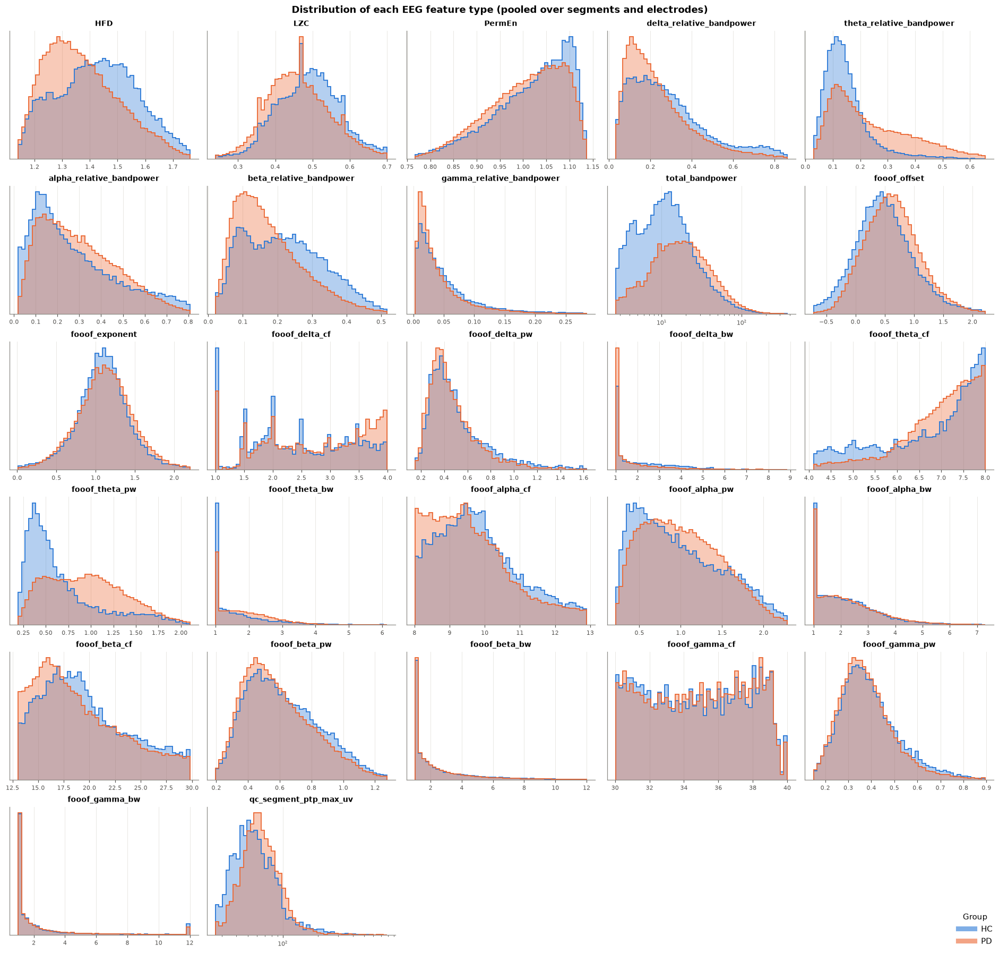

In [28]:
def pooled_values(feature: str) -> tuple[np.ndarray, np.ndarray]:
    """All values of a feature type (all segments x electrodes) and the matching group label."""
    cols = [eeg_col(e, feature) for e in ELECTRODES]
    values = full_df[cols].to_numpy().ravel()                      # row-major: each row's 19 electrodes are contiguous
    groups = np.repeat(segment_meta['group'].to_numpy(), len(cols))
    keep = ~np.isnan(values)
    return values[keep], groups[keep]

n_cols = 5
n_rows = int(np.ceil(len(FEATURES_ORDERED) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 2.7 * n_rows), constrained_layout=True)
for ax, feature in zip(axes.ravel(), FEATURES_ORDERED):
    values, groups = pooled_values(feature)
    if feature in LOG_FEATURES:
        values, groups = values[values > 0], groups[values > 0]
        bins = np.logspace(*np.log10(np.percentile(values, [0.5, 99.5])), 50)
        ax.set_xscale('log')
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        bins = np.linspace(*np.percentile(values, [0.5, 99.5]), 50)
    for g in GROUP_ORDER:
        ax.hist(values[groups == g], bins=bins, density=True, color=GROUP_COLORS[g], alpha=0.35)
        ax.hist(values[groups == g], bins=bins, density=True, color=GROUP_COLORS[g], histtype='step', linewidth=1.2)
    ax.set_title(feature, fontsize=9)
    ax.tick_params(labelsize=7)
    ax.set_yticks([])
for ax in axes.ravel()[len(FEATURES_ORDERED):]:
    ax.axis('off')
fig.legend(handles=[Line2D([], [], color=GROUP_COLORS[g], linewidth=6, alpha=0.6, label=g) for g in GROUP_ORDER],
           loc='lower right', title='Group', fontsize=10)
fig.suptitle('Distribution of each EEG feature type (pooled over segments and electrodes)', fontweight='bold')
plt.show()

In [29]:
summary_rows = {}
for feature in FEATURES_ORDERED:
    values, _ = pooled_values(feature)
    s = pd.Series(values)
    summary_rows[feature] = {
        'family': next(fam for fam, feats in FEATURE_FAMILIES.items() if feature in feats),
        '% missing': 100 * (1 - len(values) / (len(full_df) * len(ELECTRODES))),
        'mean': s.mean(), 'std': s.std(), 'min': s.min(), 'p1': s.quantile(0.01),
        'median': s.median(), 'p99': s.quantile(0.99), 'max': s.max(), 'skewness': s.skew(),
    }
print('Summary statistics per feature type (pooled over segments and electrodes):')
pd.DataFrame(summary_rows).T.astype({c: float for c in ['% missing', 'mean', 'std', 'min', 'p1', 'median', 'p99', 'max', 'skewness']}).round(3)

Summary statistics per feature type (pooled over segments and electrodes):


,family,% missing,mean,std,min,p1,median,p99,max,skewness
HFD,Signal complexity,0.000,1.388,0.139,1.075,1.153,1.372,1.731,1.891,0.463
LZC,Signal complexity,0.000,0.470,0.088,0.014,0.266,0.465,0.686,0.763,0.073
PermEn,Signal complexity,0.000,1.008,0.082,0.648,0.791,1.021,1.131,1.181,-0.674
delta_relative_bandpower,Relative band power,0.000,0.254,0.171,0.009,0.039,0.211,0.811,0.997,1.307
theta_relative_bandpower,Relative band power,0.000,0.216,0.139,0.001,0.037,0.171,0.622,0.831,1.116
alpha_relative_bandpower,Relative band power,0.000,0.295,0.181,0.000,0.027,0.260,0.772,0.915,0.709
beta_relative_bandpower,Relative band power,0.000,0.189,0.106,0.001,0.029,0.168,0.483,0.752,0.815
gamma_relative_bandpower,Relative band power,0.000,0.046,0.049,0.000,0.004,0.030,0.241,0.587,2.741
total_bandpower,Absolute power,0.000,185.690,21151.796,0.562,3.428,31.504,258.526,5083411.244,204.016
fooof_offset,FOOOF aperiodic,0.000,0.600,0.516,-1.907,-0.542,0.576,1.997,6.729,0.571


<div dir="rtl">

> **ערכי FOOOF מצטברים בגבולות ההתאמה.** הרבה רוחבי שיא שווים בדיוק ל־1 (וחלק מרוחבי שיא הגמא שווים בדיוק ל־12), ותדרי המרכז מצטופפים בקצוות של תחומי התדרים (למשל δ ב־1 וב־4 Hz). אלה הגבולות שהוגדרו בזמן התאמת מודל FOOOF, ולא ערכים פיזיולוגיים. שיאים כאלה הם למעשה התאמה "כפויה", וכדאי להתייחס אליהם בזהירות. למשל, אפשר לטפל בהם כקטגוריה נפרדת, או לברר עם מי שחילץ את הפיצ'רים אילו גבולות הוגדרו.

**האם העוצמות היחסיות מסתכמות ל־1?** אם כן, כל אחת מהן נקבעת לפי ארבע האחרות (מולטיקולינאריות מלאה). זה חשוב למודלים ליניאריים.

</div>

In [30]:
rel_sum = np.concatenate([
    sum(full_df[eeg_col(e, f'{b}_relative_bandpower')] for b in BANDS).to_numpy() for e in ELECTRODES])
pd.Series(rel_sum, name='sum of the 5 relative band powers').describe().round(4)

count    104310.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
Name: sum of the 5 relative band powers, dtype: float64

<div dir="rtl">

### 7.4 מאיפה מגיעה השונות? נבדקים מול אלקטרודות מול זמן

לפני שמסכמים את הנתונים, כדאי לדעת איזו צורת מיצוע מאבדת הכי מעט מידע. כל ערך של פיצ'ר (נבדק אחד, אלקטרודה אחת, מקטע אחד של 10 שניות) אפשר לפרק לשלושה חלקים:

* **בין נבדקים**: עד כמה הנבדקים שונים זה מזה בממוצע. זה החלק שמסווג יכול לנצל;
* **בין אלקטרודות (בתוך נבדק)**: עד כמה האלקטרודות של אותו נבדק שונות זו מזו, כלומר הבדלים מרחביים;
* **לאורך הזמן (בתוך נבדק ואלקטרודה)**: עד כמה אותה אלקטרודה של אותו נבדק משתנה ממקטע למקטע.

העמודות מציגות את חלק השונות הכוללת שכל רכיב מסביר (`total_bandpower` בסקאלת log10; עמודת ה־QC לא נכללת, כי היא זהה בכל האלקטרודות).

</div>

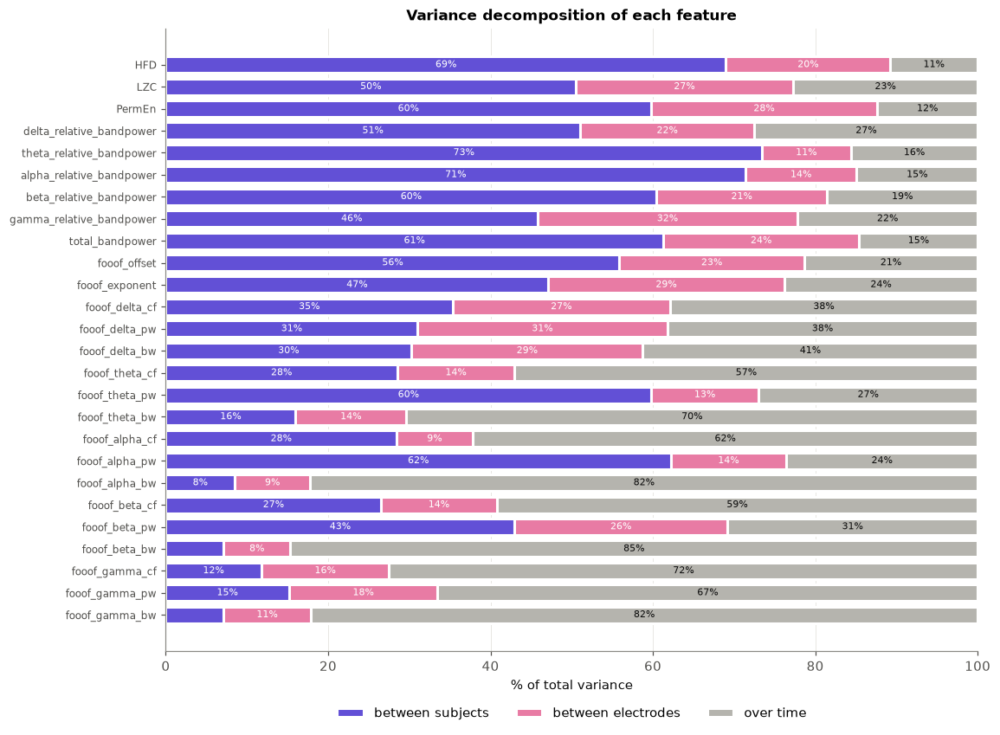

Features where electrodes differ more than time points: 8 / 26


,between subjects,between electrodes,over time
fooof_beta_bw,7.1,8.2,84.7
fooof_gamma_bw,7.1,10.7,82.2
fooof_alpha_bw,8.5,9.3,82.2
fooof_gamma_cf,11.7,15.8,72.5
fooof_theta_bw,16.0,13.6,70.4
fooof_gamma_pw,15.2,18.3,66.5
fooof_alpha_cf,28.4,9.4,62.2
fooof_beta_cf,26.5,14.2,59.3
fooof_theta_cf,28.5,14.5,57.0
fooof_delta_bw,30.2,28.5,41.2


In [31]:
def variance_decomposition(feature: str) -> dict:
    """Share (%) of a feature's total variance: between subjects / between electrodes / over time."""
    wide = full_df[[eeg_col(e, feature) for e in ELECTRODES]].copy()
    wide.columns = pd.Index(ELECTRODES, name='electrode')
    long = wide.stack().rename('value').reset_index().dropna(subset=['value'])
    long.columns = ['subject', 'electrode', 'value']
    if feature in LOG_FEATURES:
        long = long[long['value'] > 0].assign(value=lambda d: np.log10(d['value']))
    total = long['value'].var(ddof=0)
    subject_mean = long.groupby('subject')['value'].transform('mean')
    subject_electrode_mean = long.groupby(['subject', 'electrode'])['value'].transform('mean')
    return {
        'between subjects': 100 * ((subject_mean - long['value'].mean()) ** 2).mean() / total,
        'between electrodes': 100 * ((subject_electrode_mean - subject_mean) ** 2).mean() / total,
        'over time': 100 * ((long['value'] - subject_electrode_mean) ** 2).mean() / total,
    }

variance_parts = pd.DataFrame({f: variance_decomposition(f) for f in PHYSIO_FEATURES}).T
VARIANCE_COLORS = {'between subjects': '#6250d6', 'between electrodes': '#e87ba4', 'over time': '#b5b4ae'}

fig, ax = plt.subplots(figsize=(11, 8.5))
left = np.zeros(len(variance_parts))
y = np.arange(len(variance_parts))[::-1]
for part, color in VARIANCE_COLORS.items():
    widths = variance_parts[part].to_numpy()
    ax.barh(y, widths, left=left, color=color, height=0.75, edgecolor='white', linewidth=2, label=part)
    for yi, l, w in zip(y, left, widths):
        if w >= 8:
            ax.text(l + w / 2, yi, f'{w:.0f}%', ha='center', va='center', fontsize=7,
                    color='white' if part != 'over time' else '#0b0b0b')
    left += widths
ax.set_yticks(y, variance_parts.index, fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel('% of total variance')
ax.set_title('Variance decomposition of each feature')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3)
ax.grid(axis='y', visible=False)
plt.show()

print('Features where electrodes differ more than time points:',
      (variance_parts['between electrodes'] > variance_parts['over time']).sum(), '/', len(variance_parts))
variance_parts.round(1).sort_values('over time', ascending=False)

<div dir="rtl">

> **מה רואים כאן**
> * **בפיצ'רים המרכזיים, רוב השונות היא בין נבדקים** (מורכבות, עוצמה יחסית וכוללת, offset ו־exponent של FOOOF: בערך 45–75%). זה חדשות טובות לסיווג.
> * **בפיצ'רים המרכזיים האלה, החלק המרחבי (בין אלקטרודות) גדול לפחות כמו החלק הזמני** (למשל HFD ‏20% מול 11%, PermEn ‏28% מול 12%, עוצמה כוללת 24% מול 15%; בעוצמה היחסית של תטא ואלפא הם בערך שווים).
> * **בפרמטרי השיאים של FOOOF התמונה הפוכה.** תדר המרכז, הרוחב ועוצמת שיא הגמא משתנים בעיקר ממקטע למקטע (57–85%). הערכה של שיא ספקטרלי מחלון בודד של 10 שניות רועשת, ולכן מקטע בודד אומר מעט על הנבדק בפיצ'רים האלה.
>
> **המסקנה להמשך ה־EDA.** השינוי לאורך הזמן בתוך אלקטרודה הוא ברובו לא שיטתי (סעיף 8 מראה כמעט אפס סחף), ולכן מיצוע על הזמן מסנן רעש. זה חשוב במיוחד בפרמטרי השיאים של FOOOF. ההבדלים בין אלקטרודות הם מבנה מרחבי שיטתי, ומיצוע על האלקטרודות היה מוחק אותו. לכן מכאן והלאה, הסיכום ברמת נבדק של כל פיצ'ר הוא **הממוצע על הזמן בכל אלקטרודה**, `subject_means`: שורה לכל נבדק ו־513 עמודות. כשצריך תצוגה מרוכזת יותר, ממצעים את הממוצעים של האלקטרודות **בכל אזור מוח** (לפי קובץ המיפוי), וזו הטבלה `subject_region`.

</div>

In [32]:
# Subject-level summary: mean over time (all segments) of every electrode x feature column
subject_means = full_df[EEG_COLS].groupby(level=0).mean()
subject_means = subject_means.join(subjects_df[['group', 'sex', 'age', 'age_bin', 'site']])

# Region-level summary: average of the time-averaged electrodes in each region -> columns (region, feature)
subject_region = pd.concat(
    {region: pd.DataFrame({f: subject_means[[eeg_col(e, f) for e in electrodes]].mean(axis=1) for f in FEATURES_ORDERED})
     for region, electrodes in REGIONS.items()}, axis=1)

is_pd = (subject_means['group'] == 'PD').to_numpy()
print(f'subject_means:  {subject_means.shape[0]} subjects x {len(EEG_COLS)} electrode-feature columns')
print(f'subject_region: {subject_region.shape[0]} subjects x {subject_region.shape[1]} region-feature columns')

subject_means:  293 subjects x 513 electrode-feature columns
subject_region: 293 subjects x 351 region-feature columns


<div dir="rtl">

### 7.5 חולים מול בריאים — לפי אזור מוח ולפי אלקטרודה

כדי לקבל מבט ראשון על הפיצ'רים שמבדילים בין הקבוצות, משווים בין חולים לבריאים כל צירוף של (פיצ'ר, אלקטרודה) וכל צירוף של (פיצ'ר, אזור מוח), על בסיס הממוצעים על הזמן ברמת נבדק. מדד גודל האפקט הוא **מתאם rank-biserial** *r* (נגזר ממבחן Mann-Whitney U). ‏*r* > 0 פירושו ערכים גבוהים יותר אצל החולים, ו־*r* < 0 גבוהים יותר אצל הבריאים. ‏|*r*| ≈ 0.1 הוא אפקט קטן, 0.3 בינוני ו־0.5 גדול. ערכי ה־p מתוקנים להשוואות מרובות בשיטת Benjamini–Hochberg ‏(FDR), בנפרד למבחנים ברמת האזור וברמת האלקטרודה.

> זה ניתוח מחקרי בלבד. הוא מתעלם מהאתר ומהגיל, שהם משתנים מבלבלים (ראו 5.3 ו־7.7).

</div>

In [33]:
def bh_fdr(p_values) -> np.ndarray:
    """Benjamini–Hochberg adjusted p-values (NaNs are kept as NaN)."""
    p = np.asarray(p_values, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    adjusted = np.minimum.accumulate(ranked[::-1])[::-1]
    tmp = np.empty_like(pv)
    tmp[order] = np.minimum(adjusted, 1)
    out[ok] = tmp
    return out

def rank_biserial(a, b) -> tuple[float, float]:
    """Rank-biserial r (positive = a larger) and Mann-Whitney p-value."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) < 3 or len(b) < 3:
        return np.nan, np.nan
    u, p = stats.mannwhitneyu(a, b)
    return 2 * u / (len(a) * len(b)) - 1, p

def effect_grid(table: pd.DataFrame, column_of, rows, cols, mask_a, mask_b) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Rank-biserial r and FDR-adjusted p for every (row, col) cell; column_of(row, col) gives the column in `table`."""
    r = pd.DataFrame(index=rows, columns=cols, dtype=float)
    p = pd.DataFrame(index=rows, columns=cols, dtype=float)
    for row in rows:
        for col in cols:
            values = table[column_of(row, col)].to_numpy()
            r.loc[row, col], p.loc[row, col] = rank_biserial(values[mask_a], values[mask_b])
    q = pd.DataFrame(bh_fdr(p.to_numpy().ravel()).reshape(p.shape), index=rows, columns=cols)
    return r, q

def annotated_heatmap(r, q, title, cbar_label, ax, limit=None, fontsize=7, show_values=True):
    limit = limit or np.nanmax(np.abs(r.to_numpy()))
    labels = (r.apply(lambda c: c.map(lambda v: '' if np.isnan(v) or not show_values else f'{v:.2f}'))
              + q.apply(lambda c: c.map(lambda v: '*' if v < 0.05 else '')))
    sns.heatmap(r, cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit, annot=labels, fmt='',
                annot_kws={'fontsize': fontsize}, linewidths=0.5, linecolor='white', cbar_kws={'label': cbar_label}, ax=ax)
    ax.set_title(title)
    ax.set_ylabel('')

def add_lobe_separators(ax, region_columns, offset=0):
    """Thick white vertical lines between lobes on a heatmap whose columns are regions."""
    lobes = [REGION_LOBE[r] for r in region_columns]
    for k in range(1, len(lobes)):
        if lobes[k] != lobes[k - 1]:
            ax.axvline(offset + k, color='white', linewidth=4)


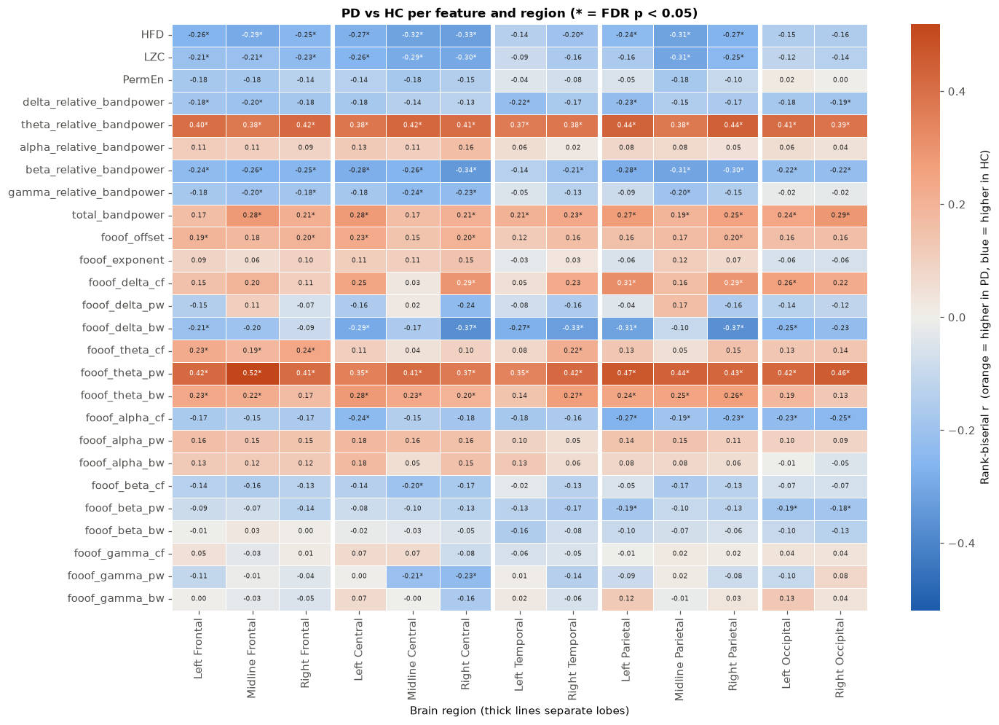

In [34]:
region_r, region_q = effect_grid(subject_region, lambda f, reg: (reg, f), PHYSIO_FEATURES, REGION_ORDER, is_pd, ~is_pd)

fig, ax = plt.subplots(figsize=(14, 9.5))
annotated_heatmap(region_r, region_q, 'PD vs HC per feature and region (* = FDR p < 0.05)',
                  'Rank-biserial r  (orange = higher in PD, blue = higher in HC)', ax, fontsize=6)
add_lobe_separators(ax, REGION_ORDER)
ax.set_xlabel('Brain region (thick lines separate lobes)')
plt.show()

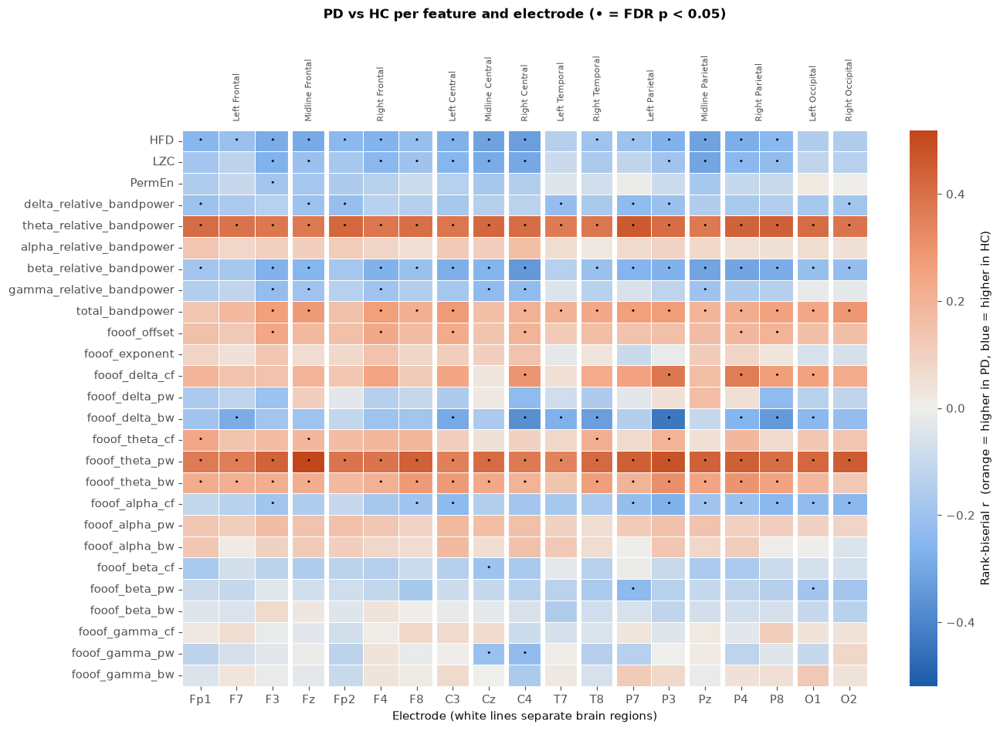

In [35]:
electrode_r, electrode_q = effect_grid(subject_means, lambda f, e: eeg_col(e, f), PHYSIO_FEATURES, ELECTRODES_BY_REGION, is_pd, ~is_pd)

limit = np.nanmax(np.abs(electrode_r.to_numpy()))
fig, ax = plt.subplots(figsize=(13, 8.5))
sns.heatmap(electrode_r, cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Rank-biserial r  (orange = higher in PD, blue = higher in HC)'}, ax=ax)
# mark the cells that survive FDR correction
for i, f in enumerate(PHYSIO_FEATURES):
    for j, e in enumerate(ELECTRODES_BY_REGION):
        if electrode_q.loc[f, e] < 0.05:
            ax.text(j + 0.5, i + 0.5, '•', ha='center', va='center', fontsize=7, color='#0b0b0b')
boundaries = np.cumsum([len(v) for v in REGIONS.values()])[:-1]
for b in boundaries:
    ax.axvline(b, color='white', linewidth=4)
# region names above the columns
starts = np.concatenate([[0], boundaries])
for start, region in zip(starts, REGION_ORDER):
    ax.text(start + len(REGIONS[region]) / 2, -0.4, region, rotation=90, ha='center', va='bottom', fontsize=7,
            color='#52514e')
ax.set_title('PD vs HC per feature and electrode (• = FDR p < 0.05)', pad=95)
ax.set_xlabel('Electrode (white lines separate brain regions)')
ax.set_ylabel('')
plt.show()

In [36]:
effects_long = pd.DataFrame({
    'feature': np.repeat(PHYSIO_FEATURES, len(ELECTRODES)),
    'electrode': ELECTRODES_BY_REGION * len(PHYSIO_FEATURES),
    'r (PD vs HC)': electrode_r.to_numpy().ravel(),
    'p_FDR': electrode_q.to_numpy().ravel(),
}).dropna()
effects_long['region'] = effects_long['electrode'].map(ELECTRODE_REGION)
effects_long['median_HC'] = [subject_means.loc[~is_pd, eeg_col(e, f)].median() for f, e in zip(effects_long['feature'], effects_long['electrode'])]
effects_long['median_PD'] = [subject_means.loc[is_pd, eeg_col(e, f)].median() for f, e in zip(effects_long['feature'], effects_long['electrode'])]

print(f"Electrode-feature pairs with FDR p < 0.05: {(effects_long['p_FDR'] < 0.05).sum()} / {len(effects_long)}")
print('Strongest electrode for each feature (top 15 features by |r|):')
strongest = effects_long.loc[effects_long.groupby('feature')['r (PD vs HC)'].apply(lambda s: s.abs().idxmax())]
strongest = strongest.sort_values('r (PD vs HC)', key=np.abs, ascending=False).set_index('feature')
strongest.head(15).round(4)

Electrode-feature pairs with FDR p < 0.05: 164 / 494
Strongest electrode for each feature (top 15 features by |r|):


,electrode,r (PD vs HC),p_FDR,region,median_HC,median_PD
feature,,,,,,
fooof_theta_pw,Fz,0.5190,0.0000,Midline Frontal,0.4530,0.7398
theta_relative_bandpower,P7,0.4634,0.0000,Left Parietal,0.1342,0.2145
fooof_delta_bw,P3,-0.4385,0.0013,Left Parietal,1.7880,1.0000
fooof_delta_cf,P3,0.3798,0.0075,Left Parietal,2.4722,3.1548
beta_relative_bandpower,C4,-0.3440,0.0001,Right Central,0.2727,0.2019
HFD,C4,-0.3262,0.0003,Right Central,1.4492,1.3687
fooof_theta_bw,P3,0.3090,0.0010,Left Parietal,1.3095,1.7253
LZC,Pz,-0.3069,0.0007,Midline Parietal,0.4755,0.4276
total_bandpower,O2,0.2899,0.0015,Right Occipital,23.9675,43.1643


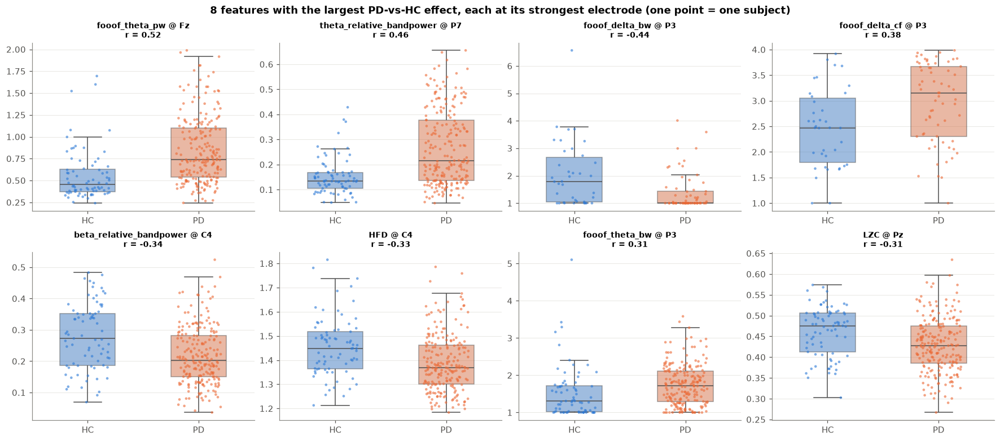

In [37]:
top_pairs = strongest.head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, (f, row) in zip(axes.ravel(), top_pairs.iterrows()):
    col = eeg_col(row['electrode'], f)
    sns.boxplot(data=subject_means, x='group', y=col, order=GROUP_ORDER, palette=GROUP_COLORS, hue='group',
                width=0.5, fliersize=0, boxprops={'alpha': 0.5}, ax=ax)
    sns.stripplot(data=subject_means, x='group', y=col, order=GROUP_ORDER, palette=GROUP_COLORS, hue='group',
                  size=3, alpha=0.6, jitter=0.2, ax=ax)
    if f in LOG_FEATURES:
        ax.set_yscale('log')
    ax.set_title(f"{f} @ {row['electrode']}\nr = {row['r (PD vs HC)']:.2f}", fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('8 features with the largest PD-vs-HC effect, each at its strongest electrode (one point = one subject)',
             fontweight='bold')
plt.show()

<div dir="rtl">

### 7.6 יתירות — בין סוגי פיצ'רים ובין אלקטרודות

שני סוגי יתירות חשובים לבחירת פיצ'רים:

1. **בין סוגי פיצ'רים באותו מיקום.** לכל אלקטרודה בנפרד מחשבים את הקורלציה (Spearman) בין 26 הפיצ'רים על פני הנבדקים, ואז ממצעים את 19 מטריצות הקורלציה. כך לא מערבבים בין מיקומים.
2. **בין אלקטרודות של אותו פיצ'ר.** לכל פיצ'ר, החציון של הקורלציות בין 19 עמודות האלקטרודות שלו. ערך גבוה אומר ש־19 העותקים נושאים בעיקר את אותו מידע, ולכן ממוצע לפי אזור מאבד מעט. ערך נמוך אומר שהאלקטרודות נושאות מידע שונה.

</div>

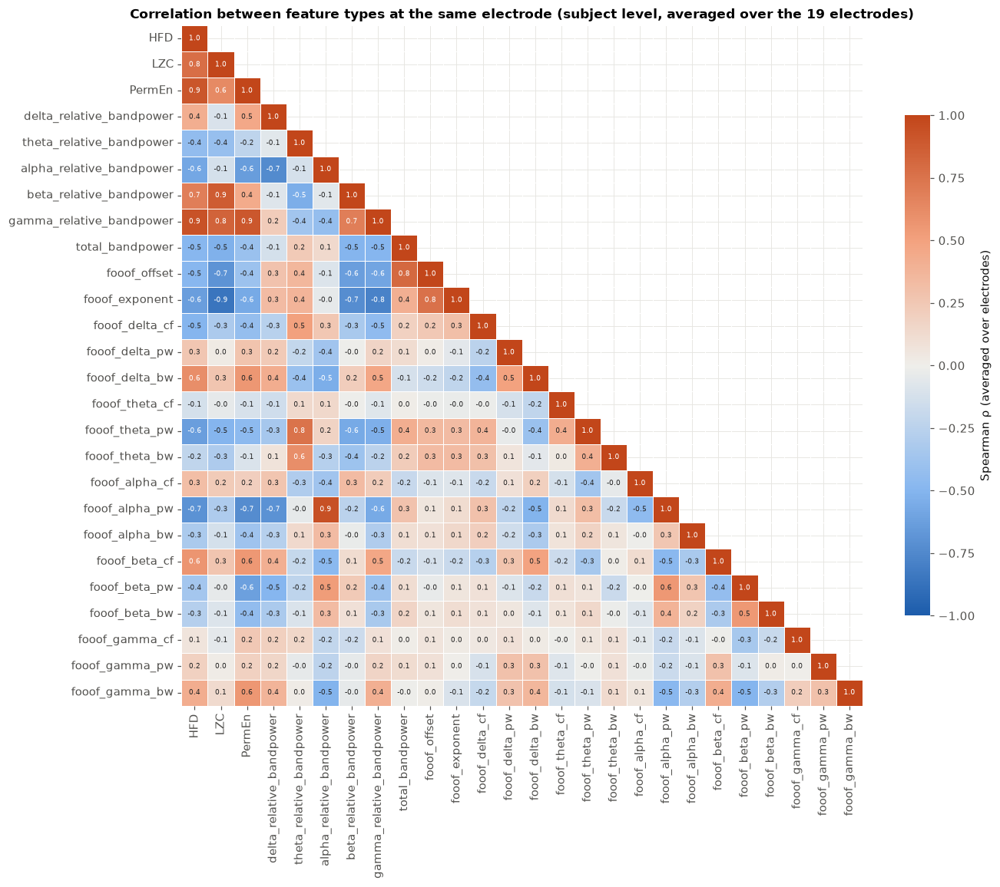

Most strongly correlated feature pairs:


Spearman ρ
alpha_relative_bandpower fooof_alpha_pw                  0.94
HFD                      gamma_relative_bandpower        0.93
                         PermEn                          0.91
PermEn                   gamma_relative_bandpower        0.90
LZC                      beta_relative_bandpower         0.88
                         fooof_exponent                 -0.85
                         gamma_relative_bandpower        0.84
total_bandpower          fooof_offset                    0.81
gamma_relative_bandpower fooof_exponent                 -0.79
HFD                      LZC                             0.78
fooof_offset             fooof_exponent                  0.76
theta_relative_bandpower fooof_theta_pw                  0.75

In [38]:
per_electrode_corr = []
for e in ELECTRODES:
    m = subject_means[[eeg_col(e, f) for f in PHYSIO_FEATURES]]
    m.columns = PHYSIO_FEATURES
    per_electrode_corr.append(m.corr(method='spearman').to_numpy())
corr = pd.DataFrame(np.nanmean(per_electrode_corr, axis=0), index=PHYSIO_FEATURES, columns=PHYSIO_FEATURES)

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1, annot=True, fmt='.1f',
            annot_kws={'fontsize': 6}, linewidths=0.5, linecolor='white', square=True,
            cbar_kws={'label': 'Spearman ρ (averaged over electrodes)', 'shrink': 0.7}, ax=ax)
ax.set_title('Correlation between feature types at the same electrode (subject level, averaged over the 19 electrodes)')
plt.show()

pairs = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack()
print('Most strongly correlated feature pairs:')
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(12).round(2).to_frame('Spearman ρ')

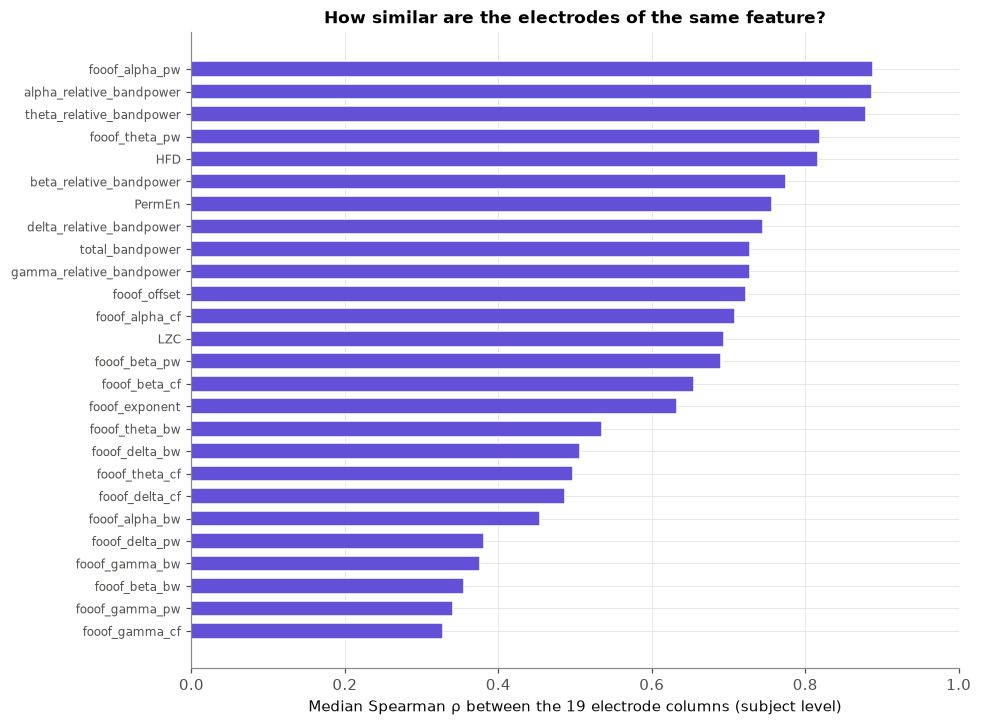

In [39]:
inter_electrode = {}
for f in PHYSIO_FEATURES:
    m = subject_means[[eeg_col(e, f) for e in ELECTRODES]].corr(method='spearman').to_numpy()
    upper = m[np.triu_indices_from(m, k=1)]
    inter_electrode[f] = {'median ρ between electrodes': np.nanmedian(upper), 'min ρ': np.nanmin(upper)}
inter_electrode = pd.DataFrame(inter_electrode).T.sort_values('median ρ between electrodes')

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(inter_electrode.index, inter_electrode['median ρ between electrodes'], color='#6250d6', height=0.7,
        edgecolor='white', linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel('Median Spearman ρ between the 19 electrode columns (subject level)')
ax.set_title('How similar are the electrodes of the same feature?')
ax.tick_params(axis='y', labelsize=8)
plt.show()

<div dir="rtl">

### 7.7 אפקט האתר

כפי שהוסבר ב־4.3, ‏`full_df` משלבת נבדקים משתי מעבדות שונות, Iowa ו־LEMON. אם פיצ'רי ה־EEG שונים בין האתרים *בתוך אותה קבוצה*, מודל עלול ללמוד חלקית "איזו מעבדה" במקום "איזו אבחנה". הסכנה גדולה במיוחד כי יחס החולים לבריאים שונה בין האתרים (ראו 5.2). להלן גודל האפקט של LEMON מול Iowa לכל פיצ'ר ואזור מוח, בנפרד בקרב הבריאים ובקרב החולים.

</div>

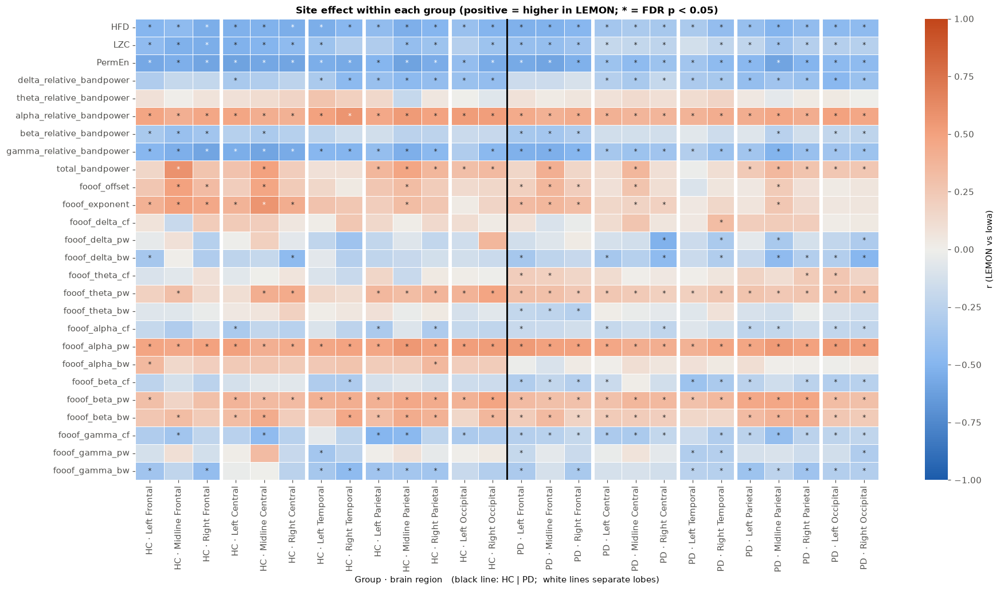

,HC · Left Frontal,HC · Midline Frontal,HC · Right Frontal,HC · Left Central,HC · Midline Central,HC · Right Central,HC · Left Temporal,HC · Right Temporal,HC · Left Parietal,HC · Midline Parietal,HC · Right Parietal,HC · Left Occipital,HC · Right Occipital,PD · Left Frontal,PD · Midline Frontal,PD · Right Frontal,PD · Left Central,PD · Midline Central,PD · Right Central,PD · Left Temporal,PD · Right Temporal,PD · Left Parietal,PD · Midline Parietal,PD · Right Parietal,PD · Left Occipital,PD · Right Occipital
HFD,-0.50,-0.46,-0.54,-0.53,-0.52,-0.55,-0.55,-0.49,-0.44,-0.53,-0.50,-0.41,-0.50,-0.53,-0.52,-0.49,-0.35,-0.33,-0.34,-0.33,-0.43,-0.42,-0.50,-0.44,-0.47,-0.46
LZC,-0.45,-0.53,-0.54,-0.52,-0.50,-0.46,-0.39,-0.28,-0.30,-0.42,-0.38,-0.28,-0.39,-0.42,-0.42,-0.38,-0.20,-0.21,-0.23,-0.14,-0.22,-0.23,-0.38,-0.28,-0.27,-0.27
PermEn,-0.57,-0.53,-0.59,-0.60,-0.58,-0.59,-0.54,-0.57,-0.50,-0.61,-0.55,-0.43,-0.56,-0.57,-0.59,-0.53,-0.39,-0.46,-0.39,-0.36,-0.46,-0.48,-0.60,-0.50,-0.46,-0.46
delta_relative_bandpower,-0.30,-0.20,-0.21,-0.33,-0.29,-0.24,-0.32,-0.47,-0.41,-0.47,-0.43,-0.40,-0.44,-0.17,-0.17,-0.11,-0.28,-0.33,-0.20,-0.32,-0.34,-0.43,-0.37,-0.40,-0.48,-0.40
theta_relative_bandpower,0.09,0.00,0.08,0.09,0.12,0.17,0.28,0.20,0.14,-0.20,0.05,-0.00,-0.07,0.08,0.02,0.06,0.08,0.13,0.09,0.12,0.17,0.04,-0.05,0.02,0.03,-0.01
alpha_relative_bandpower,0.48,0.41,0.47,0.48,0.42,0.40,0.50,0.57,0.46,0.54,0.49,0.52,0.52,0.44,0.40,0.43,0.40,0.37,0.37,0.39,0.43,0.43,0.47,0.42,0.50,0.46
beta_relative_bandpower,-0.34,-0.41,-0.36,-0.27,-0.33,-0.27,-0.23,-0.16,-0.15,-0.24,-0.24,-0.18,-0.19,-0.34,-0.36,-0.30,-0.14,-0.13,-0.15,-0.06,-0.16,-0.08,-0.25,-0.14,-0.22,-0.23
gamma_relative_bandpower,-0.49,-0.54,-0.59,-0.54,-0.59,-0.56,-0.49,-0.50,-0.42,-0.53,-0.47,-0.30,-0.47,-0.52,-0.53,-0.49,-0.35,-0.39,-0.37,-0.28,-0.39,-0.37,-0.51,-0.41,-0.37,-0.39
total_bandpower,0.16,0.58,0.28,0.29,0.50,0.21,0.09,0.10,0.36,0.47,0.37,0.31,0.34,0.16,0.41,0.16,0.11,0.36,0.10,-0.02,0.10,0.24,0.35,0.27,0.25,0.26
fooof_offset,0.26,0.49,0.33,0.22,0.47,0.23,0.15,0.03,0.26,0.33,0.22,0.13,0.15,0.20,0.36,0.21,0.09,0.27,0.11,-0.10,0.06,0.05,0.23,0.09,0.02,0.06


Median |r| site effect vs median |r| PD-vs-HC effect (region level):
  site (within HC): 0.30   site (within PD): 0.26   PD vs HC: 0.16


,median |site r| within HC,median |site r| within PD,median |PD vs HC r|
Left Frontal,0.30,0.28,0.17
Midline Frontal,0.31,0.28,0.18
Right Frontal,0.27,0.23,0.14
Left Central,0.26,0.19,0.18
Midline Central,0.33,0.23,0.16
Right Central,0.26,0.20,0.19
Left Temporal,0.26,0.17,0.11
Right Temporal,0.28,0.28,0.16
Left Parietal,0.31,0.23,0.15
Midline Parietal,0.33,0.29,0.16


In [40]:
SITE_A, SITE_B = LABS_TO_NAMES['ds007526'], LABS_TO_NAMES['ds004584']   # LEMON vs Iowa
site_cols = [f'{g} · {reg}' for g in GROUP_ORDER for reg in REGION_ORDER]
site_r = pd.DataFrame(index=PHYSIO_FEATURES, columns=site_cols, dtype=float)
site_p = site_r.copy()
for g in GROUP_ORDER:
    in_group = (subject_means['group'] == g).to_numpy()
    site_a = in_group & (subject_means['site'] == SITE_A).to_numpy()
    site_b = in_group & (subject_means['site'] == SITE_B).to_numpy()
    for reg in REGION_ORDER:
        for f in PHYSIO_FEATURES:
            values = subject_region[(reg, f)].to_numpy()
            site_r.loc[f, f'{g} · {reg}'], site_p.loc[f, f'{g} · {reg}'] = rank_biserial(values[site_a], values[site_b])
site_q = pd.DataFrame(bh_fdr(site_p.to_numpy().ravel()).reshape(site_p.shape), index=site_p.index, columns=site_p.columns)

fig, ax = plt.subplots(figsize=(19, 9.5))
annotated_heatmap(site_r, site_q, f'Site effect within each group (positive = higher in {SITE_A}; * = FDR p < 0.05)',
                  f'r ({SITE_A} vs {SITE_B})', ax, limit=1, fontsize=8, show_values=False)
add_lobe_separators(ax, REGION_ORDER)
add_lobe_separators(ax, REGION_ORDER, offset=len(REGION_ORDER))
ax.axvline(len(REGION_ORDER), color='#0b0b0b', linewidth=2)
ax.set_xlabel('Group · brain region   (black line: HC | PD;  white lines separate lobes)')
plt.show()

# Values of the heatmap above: rank-biserial r (LEMON vs Iowa), per feature (rows) and group · region (columns)
with pd.option_context('display.max_columns', None, 'display.width', 250):
    display(site_r.round(2))


site_by_region = pd.DataFrame({g: [site_r[f'{g} · {reg}'].abs().median() for reg in REGION_ORDER] for g in GROUP_ORDER},
                              index=REGION_ORDER).add_prefix('median |site r| within ')
site_by_region['median |PD vs HC r|'] = region_r.abs().median().reindex(REGION_ORDER).to_numpy()
print('Median |r| site effect vs median |r| PD-vs-HC effect (region level):')
print(f"  site (within HC): {site_r.filter(like='HC').abs().median().median():.2f}   "
      f"site (within PD): {site_r.filter(like='PD').abs().median().median():.2f}   "
      f"PD vs HC: {region_r.abs().median().median():.2f}")
site_by_region.round(2)

<div dir="rtl">

**השורה התחתונה.** בכל 13 אזורי המוח, ההבדל בין המעבדות (חציון |r| של כ־0.2–0.33) גדול מההבדל בין החולים לבריאים (כ־0.11–0.19), בערך פי שניים. אפקט האתר יציב גם בבריאים וגם בחולים. הוא בולט במיוחד במדדי המורכבות ובעוצמת הגמא (גבוהים יותר ב־Iowa) ובעוצמת האלפא (גבוהה יותר ב־LEMON). העוצמה היחסית של תטא, הפיצ'ר שמבדיל הכי חזק בין הקבוצות, כמעט לא מושפעת מהאתר. לכן חשוב לטפל באתר במפורש בשלב המודלים.

**הסתייגות.** ההשוואה בתוך כל קבוצה מנטרלת את האבחנה, אבל לא את הגיל: הבריאים ב־Iowa מבוגרים יותר, וב־LEMON צעירים יותר (5.3). לכן חלק מאפקט האתר עשוי לנבוע מהבדלי גיל ולא מהציוד או מהפרוטוקול. כדי להפריד בין השניים צריך ניתוח שמנטרל את הגיל, למשל רגרסיה עם אתר וגיל יחד.

</div>

<div dir="rtl">

### 7.8 סיכום לפי אזורי המוח

כדי לארגן את הממצאים לפי החלוקה לאזורים, הטבלה מרכזת לכל אזור מוח: אילו אלקטרודות הוא כולל, כמה פיצ'רים בו מבדילים באופן מובהק בין חולים לבריאים (אחרי תיקון FDR), מה ארבעת האפקטים החזקים ביותר, ומה גודל אפקט האתר בו.

אחרי הטבלה מוצגות **מפות ראש** ל־12 הפיצ'רים שמבדילים הכי חזק בין חולים לבריאים. הדירוג נקבע לפי ה־|r| הגבוה ביותר של הפיצ'ר בכל אחד מהאזורים. כל מפה היא ציור של הראש במבט מלמעלה (האף למעלה, צד שמאל של הראש בצד שמאל של הציור), מחולק ל־13 אזורי המוח. בכל אזור כתובים שמו וגודל האפקט (*r*, עם * כשהוא מובהק אחרי FDR), והצבע מראה את הכיוון והעוצמה: כתום = גבוה יותר אצל החולים, כחול = גבוה יותר אצל הבריאים. כך אפשר לראות במבט אחד אם אפקט הוא כללי, מתרכז באונה מסוימת, או לא סימטרי בין שמאל לימין.

> המפות נבנות על תמונת התבנית `head_map_regions.png`, שנטענת בסעיף 2. בתמונה כל אזור צבוע בצבע "מפתח" ייחודי (המילון `REGION_KEY_COLORS`). הקוד מזהה כל אזור לפי הצבע שלו, ו"מלביש" עליו את הנתונים.

</div>

In [41]:
rows = []
for reg in REGION_ORDER:
    r, q = region_r[reg], region_q[reg]
    top = r.abs().sort_values(ascending=False).index[:4]
    rows.append({
        'region': reg,
        'electrodes': ', '.join(REGIONS[reg]),
        'significant PD-vs-HC features (FDR)': int((q < 0.05).sum()),
        'strongest PD-vs-HC effects (r, * = FDR p < 0.05)': '; '.join(
            f"{f} {r[f]:+.2f}{'*' if q[f] < 0.05 else ''}" for f in top),
        'median |site r| HC / PD': f"{site_by_region.loc[reg].iloc[0]:.2f} / {site_by_region.loc[reg].iloc[1]:.2f}",
    })
region_summary = pd.DataFrame(rows).set_index('region')
with pd.option_context('display.max_colwidth', 200):
    display(region_summary)

,electrodes,significant PD-vs-HC features (FDR),"strongest PD-vs-HC effects (r, * = FDR p < 0.05)",median |site r| HC / PD
region,,,,
Left Frontal,"Fp1, F7, F3",10,fooof_theta_pw +0.42*; theta_relative_bandpower +0.40*; HFD -0.26*; beta_relative_bandpower -0.24*,0.30 / 0.28
Midline Frontal,Fz,10,fooof_theta_pw +0.52*; theta_relative_bandpower +0.38*; HFD -0.29*; total_bandpower +0.28*,0.31 / 0.28
Right Frontal,"Fp2, F4, F8",9,theta_relative_bandpower +0.42*; fooof_theta_pw +0.41*; beta_relative_bandpower -0.25*; HFD -0.25*,0.27 / 0.23
Left Central,C3,10,theta_relative_bandpower +0.38*; fooof_theta_pw +0.35*; fooof_delta_bw -0.29*; fooof_theta_bw +0.28*,0.26 / 0.19
Midline Central,Cz,9,theta_relative_bandpower +0.42*; fooof_theta_pw +0.41*; HFD -0.32*; LZC -0.29*,0.33 / 0.23
Right Central,C4,12,theta_relative_bandpower +0.41*; fooof_delta_bw -0.37*; fooof_theta_pw +0.37*; beta_relative_bandpower -0.34*,0.26 / 0.20
Left Temporal,T7,5,theta_relative_bandpower +0.37*; fooof_theta_pw +0.35*; fooof_delta_bw -0.27*; delta_relative_bandpower -0.22*,0.26 / 0.17
Right Temporal,T8,8,fooof_theta_pw +0.42*; theta_relative_bandpower +0.38*; fooof_delta_bw -0.33*; fooof_theta_bw +0.27*,0.28 / 0.28
Left Parietal,"P7, P3",11,fooof_theta_pw +0.47*; theta_relative_bandpower +0.44*; fooof_delta_cf +0.31*; fooof_delta_bw -0.31*,0.31 / 0.23


,max |r| over regions,strongest region,significant regions (FDR)
fooof_theta_pw,0.52,Midline Frontal,13
theta_relative_bandpower,0.44,Right Parietal,13
fooof_delta_bw,0.37,Right Central,8
beta_relative_bandpower,0.34,Right Central,12
HFD,0.33,Right Central,10
fooof_delta_cf,0.31,Left Parietal,4
LZC,0.31,Midline Parietal,8
total_bandpower,0.29,Right Occipital,11
fooof_theta_bw,0.28,Left Central,9
fooof_alpha_cf,0.27,Left Parietal,6


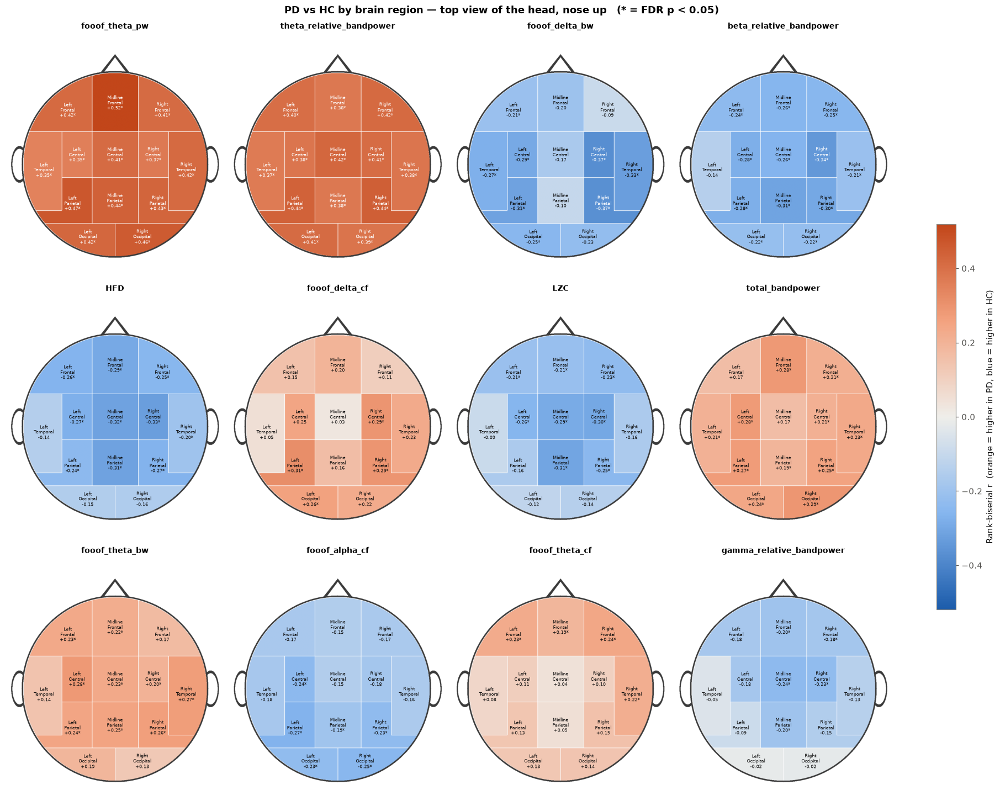

In [42]:
# ---------- Head-map template: each region is painted in a unique key colour in head_map_regions.png ----------
REGION_KEY_COLORS = {
    'Left Frontal': '#f4a6a6', 'Midline Frontal': '#f7c59f', 'Right Frontal': '#f9e79f',
    'Left Central': '#a9dfbf', 'Midline Central': '#a3e4d7', 'Right Central': '#aed6f1',
    'Left Temporal': '#d2b4de', 'Right Temporal': '#f5b7d4',
    'Left Parietal': '#c5e1a5', 'Midline Parietal': '#ffe0b2', 'Right Parietal': '#b3e5fc',
    'Left Occipital': '#d7ccc8', 'Right Occipital': '#cfd8dc',
}
HEAD_OUTLINE_COLOR = '#3a3a3a'
assert set(REGION_KEY_COLORS) == set(REGION_ORDER), (
    f'regions in the Excel map and in the head image differ: {set(REGION_KEY_COLORS) ^ set(REGION_ORDER)}')

head_rgb = head_map_image[..., :3].astype(float)
if head_rgb.max() > 1:                       # an 8-bit image -> scale to 0..1
    head_rgb = head_rgb / 255

region_masks = {reg: np.all(np.abs(head_rgb - np.array(to_rgb(color))) < 0.02, axis=-1)
                for reg, color in REGION_KEY_COLORS.items()}
empty = [reg for reg, m in region_masks.items() if not m.any()]
assert not empty, f'no pixels of these key colours were found in the head image: {empty}'

outline_mask = head_rgb.max(axis=-1) < 0.5                      # dark pixels = head outline, nose, ears
label = np.full(head_rgb.shape[:2], -1)
for k, reg in enumerate(REGION_ORDER):
    label[region_masks[reg]] = k
boundary_mask = np.zeros_like(outline_mask)                     # thin white lines between neighbouring regions
for axis in (0, 1):
    for shift in (1, 2):
        boundary_mask |= (label != np.roll(label, shift, axis=axis)) & (label >= 0)
region_centres = {reg: (np.nonzero(m)[1].mean(), np.nonzero(m)[0].mean()) for reg, m in region_masks.items()}


def plot_head_map(ax, values: pd.Series, q_values: pd.Series, title: str, norm):
    # Paint each region of the head template by its value and write its name and value on it
    canvas = np.zeros(head_rgb.shape[:2] + (4,))                # transparent background
    for reg in REGION_ORDER:
        canvas[region_masks[reg]] = DIVERGING_CMAP(norm(values[reg]))
    canvas[boundary_mask] = (1, 1, 1, 1)
    canvas[outline_mask] = (*to_rgb(HEAD_OUTLINE_COLOR), 1)
    ax.imshow(canvas)
    for reg in REGION_ORDER:
        x, y = region_centres[reg]
        v = values[reg]
        star = '*' if q_values[reg] < 0.05 else ''
        strong = abs(norm(v) - 0.5) > 0.33
        ax.text(x, y, f'{REGION_HEMISPHERE[reg]}\n{REGION_LOBE[reg]}\n{v:+.2f}{star}', ha='center', va='center',
                fontsize=5.5, linespacing=1.15, color='white' if strong else '#0b0b0b')
    ax.set_title(title, fontsize=9)
    ax.axis('off')


# ---------- The 12 features that separate PD from HC most strongly (largest |r| in any region) ----------
N_TOP_FEATURES = 12
feature_strength = region_r.abs().max(axis=1).sort_values(ascending=False)
TOP_FEATURES = feature_strength.index[:N_TOP_FEATURES].tolist()
display(pd.DataFrame({'max |r| over regions': feature_strength[TOP_FEATURES].round(2),
                      'strongest region': region_r.loc[TOP_FEATURES].abs().idxmax(axis=1),
                      'significant regions (FDR)': (region_q.loc[TOP_FEATURES] < 0.05).sum(axis=1)}))

limit = np.nanmax(np.abs(region_r.loc[TOP_FEATURES].to_numpy()))
norm = plt.Normalize(-limit, limit)
n_cols = 4
n_rows = int(np.ceil(N_TOP_FEATURES / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.1 * n_cols, 4.4 * n_rows), constrained_layout=True)
for ax, f in zip(axes.ravel(), TOP_FEATURES):
    plot_head_map(ax, region_r.loc[f], region_q.loc[f], f, norm)
for ax in axes.ravel()[N_TOP_FEATURES:]:
    ax.axis('off')
fig.colorbar(plt.cm.ScalarMappable(cmap=DIVERGING_CMAP, norm=norm), ax=axes, shrink=0.5,
             label='Rank-biserial r  (orange = higher in PD, blue = higher in HC)')
fig.suptitle('PD vs HC by brain region — top view of the head, nose up   (* = FDR p < 0.05)', fontweight='bold')
plt.show()

<div dir="rtl">

---
## 8. התנהגות פיצ'רי ה־EEG לאורך הזמן לפי תתי־קבוצות

איך הפיצ'רים משתנים במהלך ההקלטה? הנבדקים מחולקים לתתי־קבוצות לפי **מין × קבוצה × עשור גילאים**. מאחר שהאלקטרודות שונות זו מזו באופן מהותי (7.4), המסלולים מוצגים **לפי אזור מוח** (מקובץ המיפוי). בכל מקטע ממצעים את האלקטרודות של האזור, ומציגים את **הממוצע על פני הנבדקים ± שגיאת התקן** בכל זמן תחילת מקטע.

איך לקרוא את הגרפים (גרף אחד לכל סוג פיצ'ר):

* כל **שורה** היא אזור מוח, וכל **עמודה** היא עשור גילאים;
* **צבע** = קבוצה (כחול HC, כתום PD), **סגנון קו** = מין (קו רציף F, מקווקו M);
* בכותרות העמודות מופיע מספר הנבדקים בכל תת־קבוצה;
* נקודת זמן מוצגת רק אם יש בה לפחות `MIN_SUBJECTS_PER_POINT` נבדקים מאותה תת־קבוצה. כך תתי־קבוצות קטנות מאוד, ונקודות זמן מאוחרות שמגיעים אליהן רק מעט הקלטות ארוכות של Iowa, מוסתרות במקום להופיע כקווים רועשים. עשורים שאין בהם אף תת־קבוצה בגודל כזה לא מוצגים;
* `total_bandpower` ועמודת ה־QC עוברות log10 לפני המיצוע.

### 8.1 גודלי תתי־הקבוצות

</div>

In [43]:
MIN_SUBJECTS_PER_POINT = 3

subgroup_sizes = subjects_df.groupby(['group', 'sex', 'age_bin']).size()
size_table = subgroup_sizes.unstack('age_bin', fill_value=0).reindex(columns=AGE_BIN_ORDER, fill_value=0)
PLOT_AGE_BINS = [a for a in AGE_BIN_ORDER if (size_table[a] >= MIN_SUBJECTS_PER_POINT).any()]

print(f'Number of subgroups (2 sexes x 2 groups x {len(AGE_BIN_ORDER)} age decades): {2 * 2 * len(AGE_BIN_ORDER)}')
print(f'Subgroups with fewer than {MIN_SUBJECTS_PER_POINT} subjects (will not be drawn): '
      f'{(size_table < MIN_SUBJECTS_PER_POINT).to_numpy().sum()}')
print('Age decades shown in the plots:', PLOT_AGE_BINS)
size_table

Number of subgroups (2 sexes x 2 groups x 6 age decades): 24
Subgroups with fewer than 3 subjects (will not be drawn): 8
Age decades shown in the plots: ['40-49', '50-59', '60-69', '70-79', '80-89']


age_bin    30-39  40-49  50-59  60-69  70-79  80-89
group sex                                          
HC    F        0      0      8     18     10      2
      M        0      2      2     11     20      4
PD    F        0      3      7     30     30      6
      M        1      4     22     59     44     10

<div dir="rtl">

> חלק מתתי־הקבוצות (העשורים הצעירים והמבוגרים ביותר) קטנות מאוד. אם זה יפריע, אפשר לשנות את `age_bin_label` (סעיף 4.3) כך שיאחד את העשורים הקיצוניים, למשל `<50` ו־`80+`. כל מה שבהמשך יתעדכן אוטומטית.

### 8.2 מסלולי הפיצ'רים לאורך הזמן

</div>

In [44]:
# Segment-level region values: for every segment, the mean over the electrodes of each region -> columns (region, feature)
region_segments = pd.concat(
    {region: pd.DataFrame({f: full_df[[eeg_col(e, f) for e in electrodes]].mean(axis=1) for f in FEATURES_ORDERED})
     for region, electrodes in REGIONS.items()}, axis=1)


def subgroup_time_stats(values: pd.Series, feature: str) -> pd.DataFrame:
    """Mean, SEM and number of subjects per (age_bin, group, sex, onset) for one segment-level series."""
    if feature in LOG_FEATURES:
        values = np.log10(values.where(values > 0))
    frame = segment_meta[['age_bin', 'group', 'sex']].assign(**{TIME_COL: full_df[TIME_COL], 'value': values})
    return (frame.groupby(['age_bin', 'group', 'sex', TIME_COL])['value']
            .agg(mean='mean', sem='sem', n='count').reset_index())


def plot_feature_over_time(feature: str, regions: list[str] | None = None, electrode: str | None = None,
                           min_subjects: int = MIN_SUBJECTS_PER_POINT):
    """One row per region (default: all regions) or a single row for one electrode; one column per age decade."""
    if electrode:
        rows = {electrode: full_df[eeg_col(electrode, feature)]}
    else:
        rows = {reg: region_segments[(reg, feature)] for reg in (regions or REGION_ORDER)}

    n_rows, n_cols = len(rows), len(PLOT_AGE_BINS)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.7 * n_cols, 1.45 * n_rows + 1.1),
                             sharex=True, sharey=True, squeeze=False, constrained_layout=True)
    for i, (row_name, values) in enumerate(rows.items()):
        stats_df = subgroup_time_stats(values, feature)
        stats_df = stats_df[stats_df['n'] >= min_subjects]
        for j, age_bin in enumerate(PLOT_AGE_BINS):
            ax = axes[i, j]
            for g in GROUP_ORDER:
                for sex in SEX_ORDER:
                    d = stats_df[(stats_df['age_bin'] == age_bin) & (stats_df['group'] == g) & (stats_df['sex'] == sex)]
                    if d.empty:
                        continue
                    ax.plot(d[TIME_COL], d['mean'], color=GROUP_COLORS[g], linestyle=SEX_LINESTYLES[sex], linewidth=1.6)
                    ax.fill_between(d[TIME_COL], d['mean'] - d['sem'], d['mean'] + d['sem'],
                                    color=GROUP_COLORS[g], alpha=0.12, linewidth=0)
            if not ax.lines:
                ax.text(0.5, 0.5, 'no data', transform=ax.transAxes, ha='center', va='center', fontsize=7, color='#8a8984')
            if i == 0:
                sizes = '  '.join(f'{g}-{s}:{subgroup_sizes.get((g, s, age_bin), 0)}' for g in GROUP_ORDER for s in SEX_ORDER)
                ax.set_title(f'Age {age_bin}\n{sizes}', fontsize=8)
            if j == 0:
                ax.set_ylabel(row_name, fontsize=8, fontweight='bold', rotation=0, ha='right', va='center')
            if i == n_rows - 1:
                ax.set_xlabel('Segment onset (s)', fontsize=8)
            ax.tick_params(labelsize=6)
    value_label = f'log10({feature})' if feature in LOG_FEATURES else feature
    where = f'electrode {electrode}' if electrode else 'mean over the electrodes of each region'
    fig.suptitle(f'{value_label}  ({where}; mean ± SEM across subjects)', fontweight='bold', fontsize=11)
    handles = [Line2D([], [], color=GROUP_COLORS[g], linestyle=SEX_LINESTYLES[s], label=f'{g} · {s}')
               for g in GROUP_ORDER for s in SEX_ORDER]
    fig.legend(handles=handles, loc='outside right center', fontsize=8)
    plt.show()


==============================  Signal complexity  ==============================


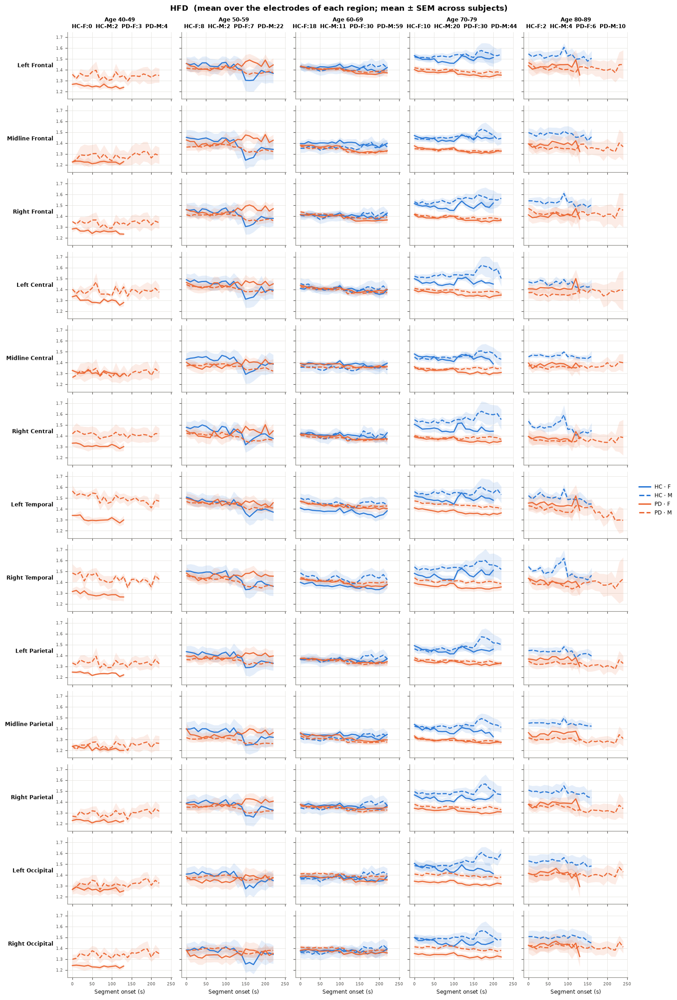

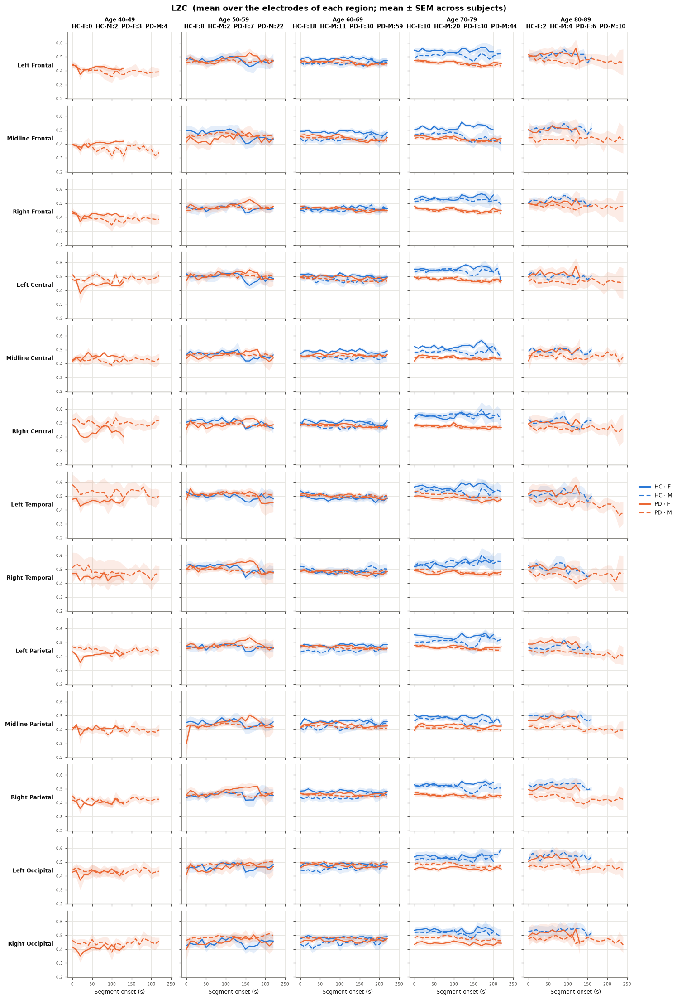

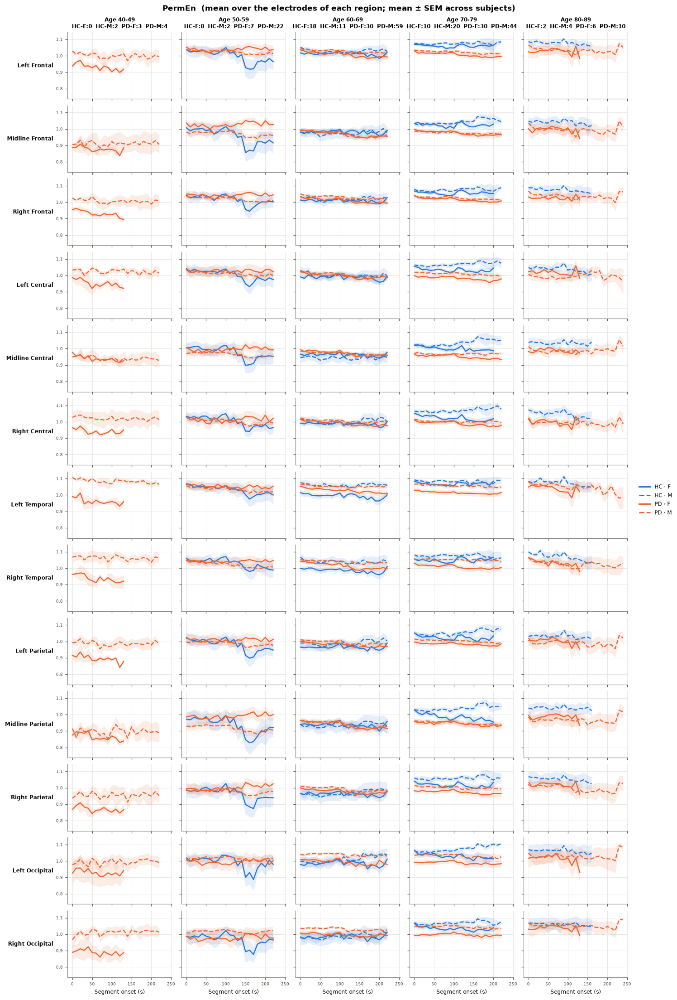


==============================  Relative band power  ==============================


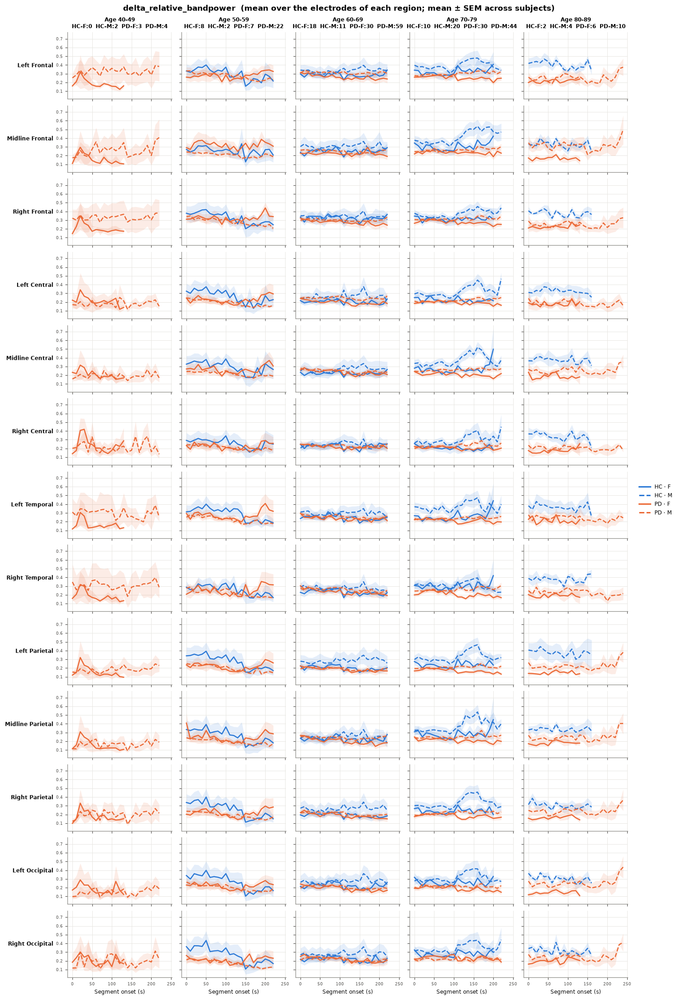

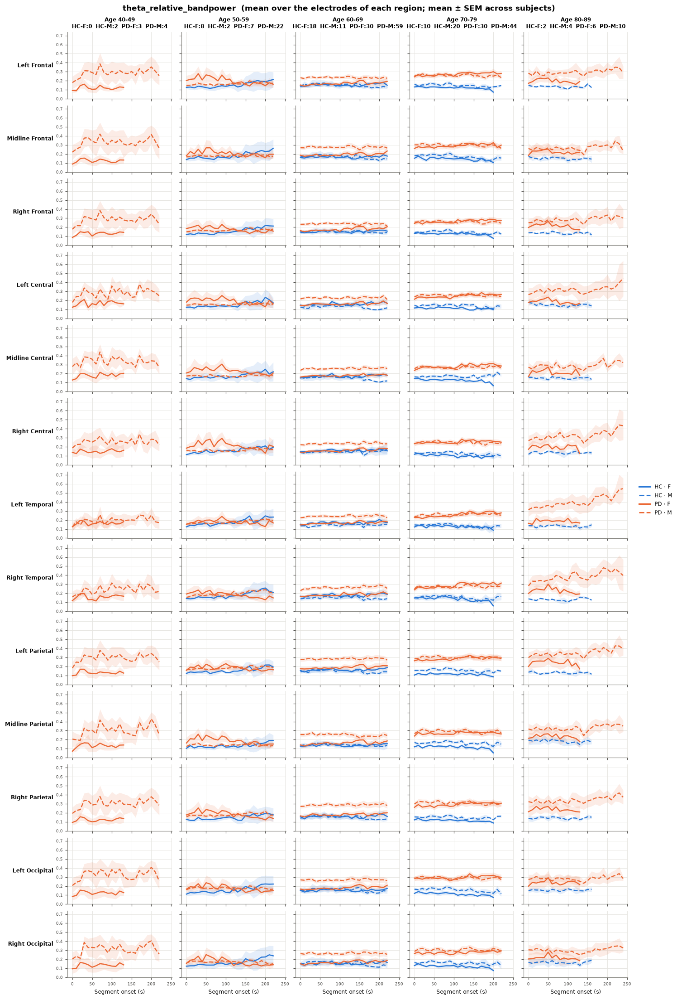

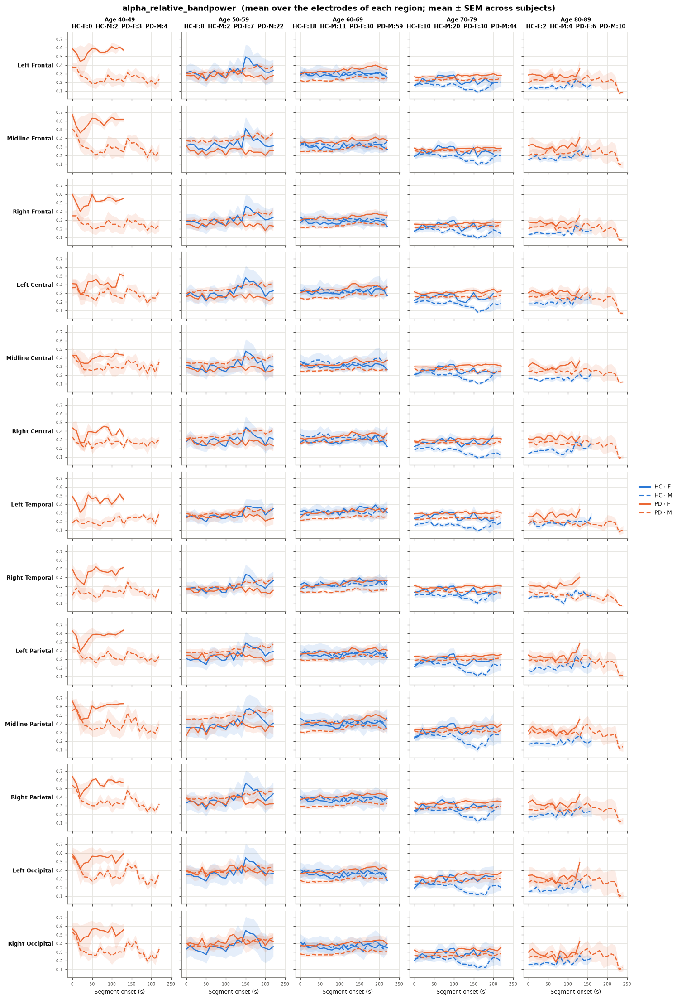

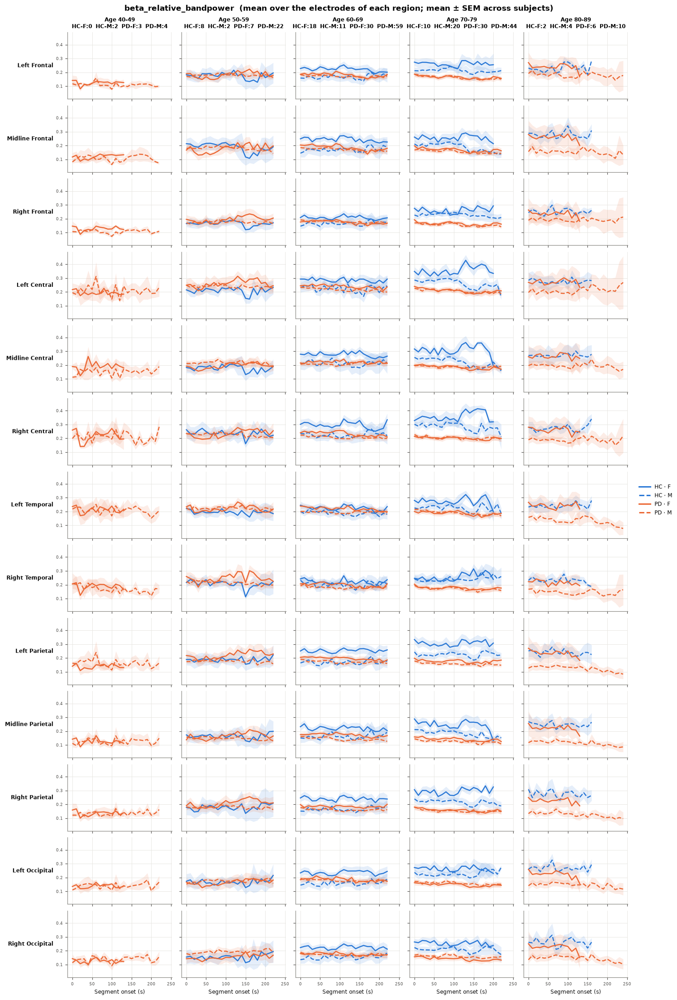

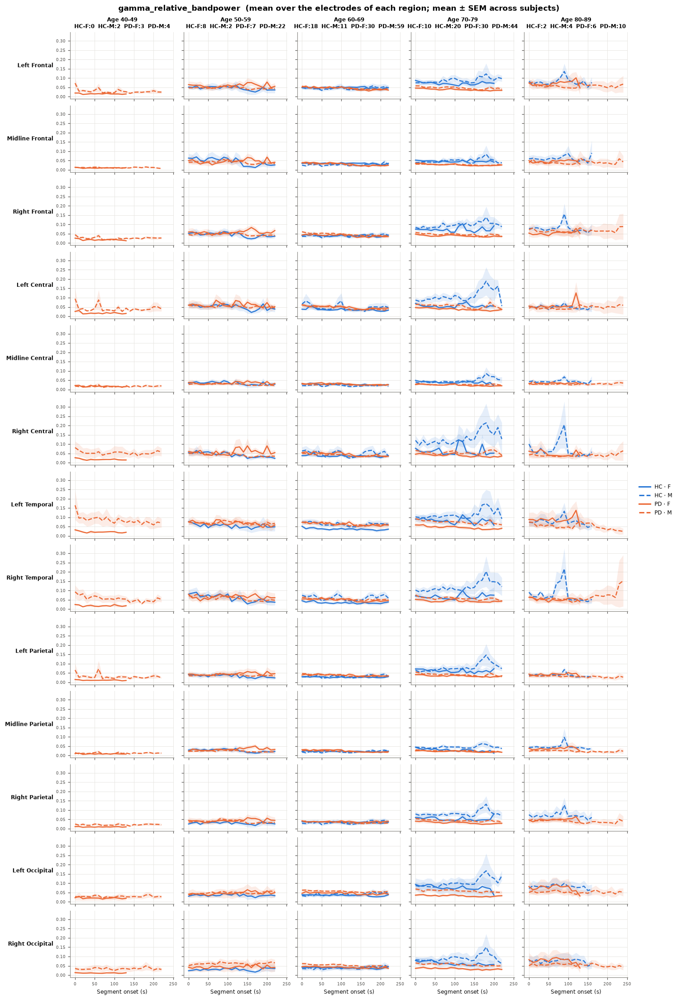


==============================  Absolute power  ==============================


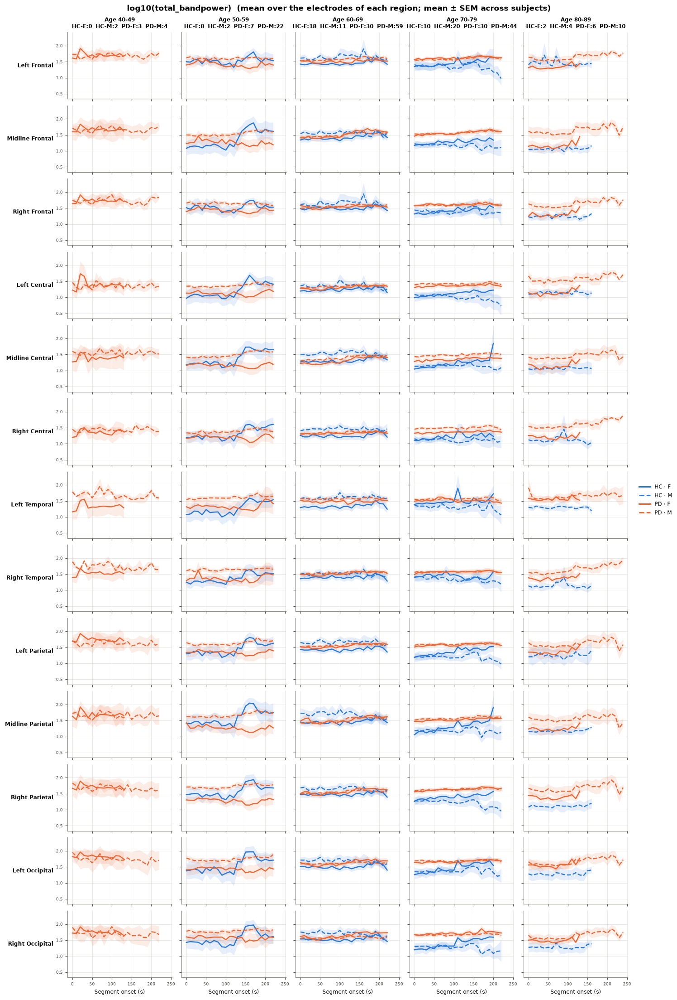


==============================  FOOOF aperiodic  ==============================


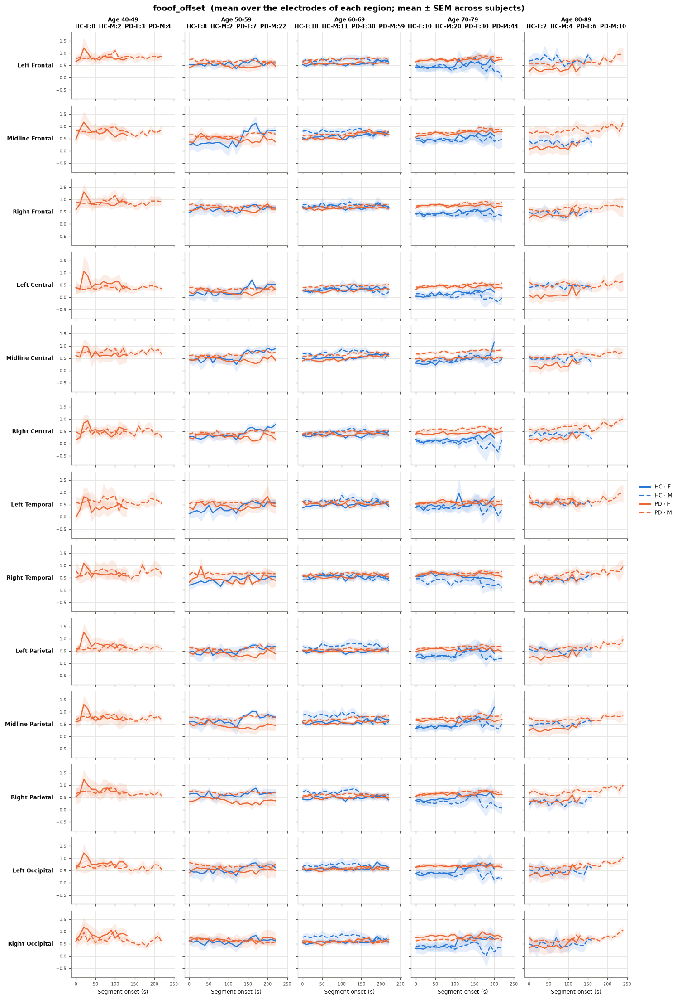

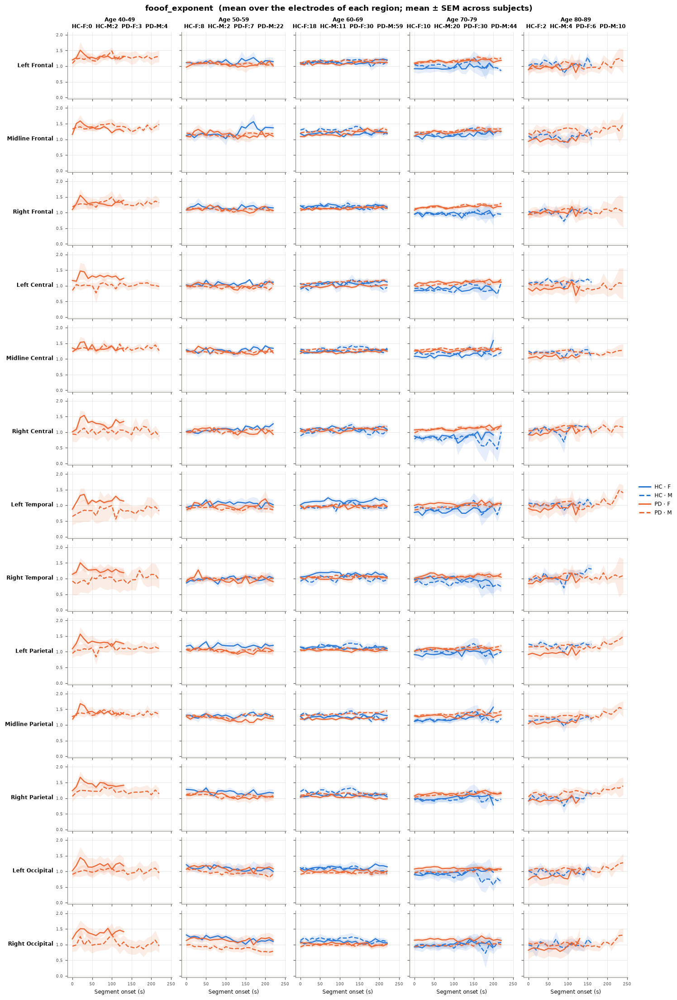


==============================  FOOOF periodic peaks  ==============================


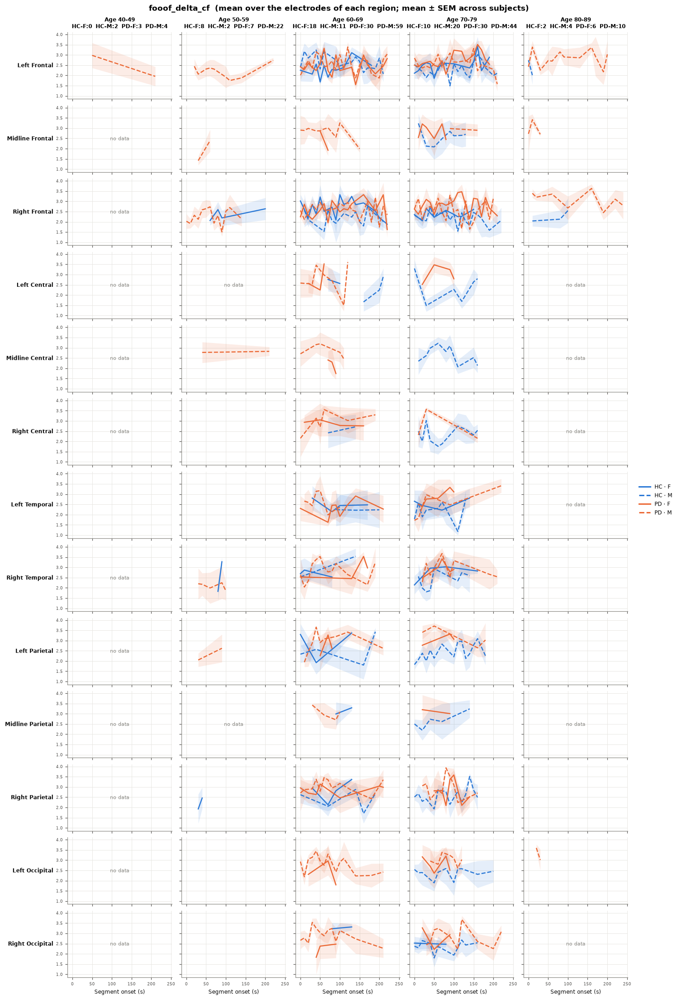

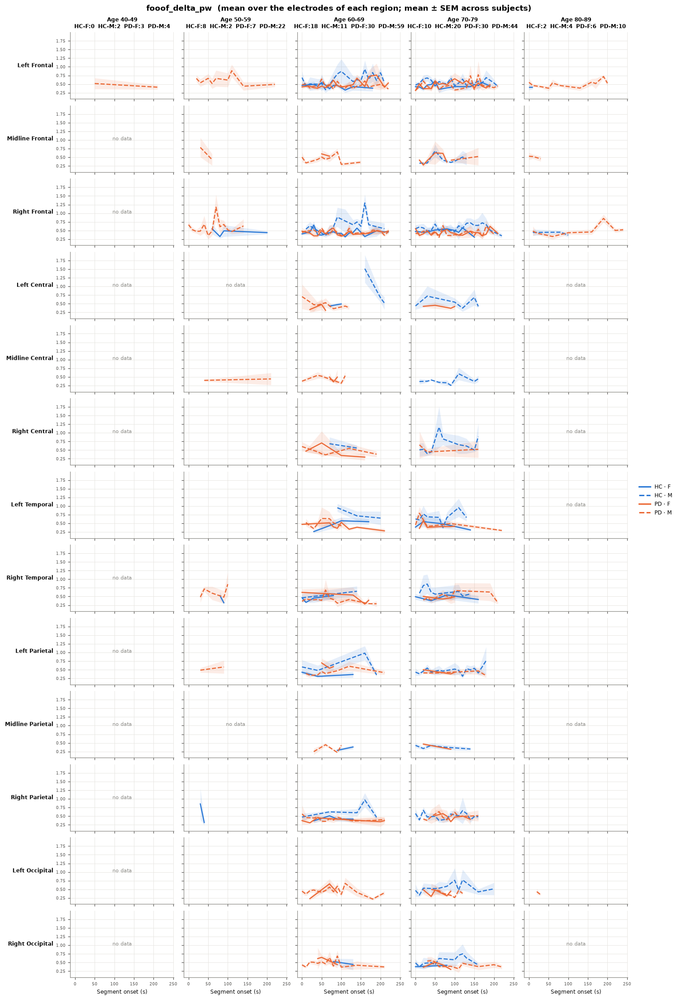

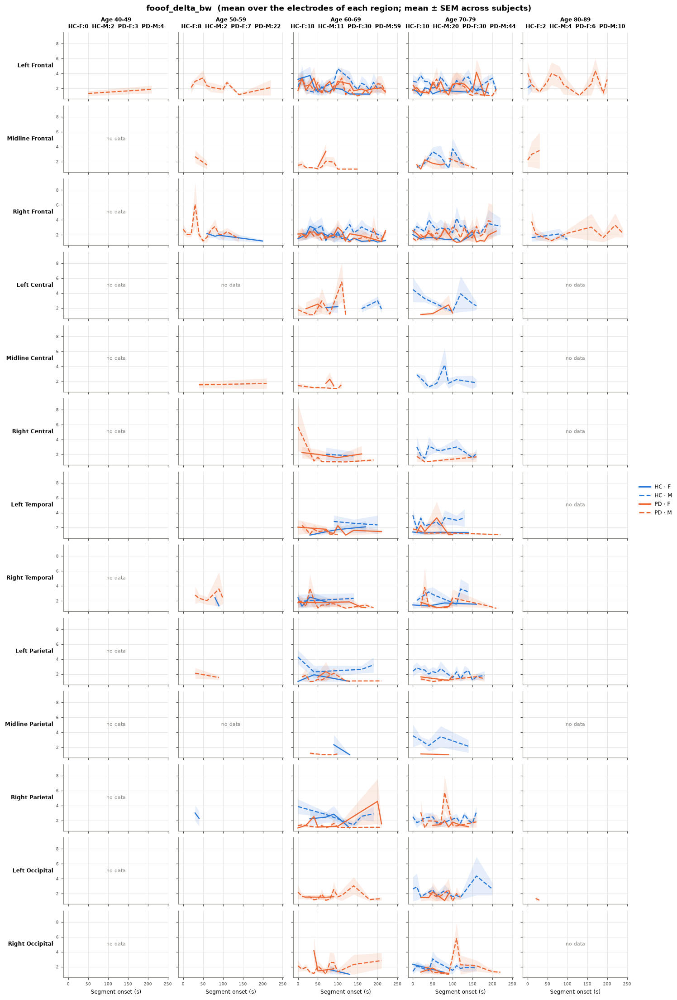

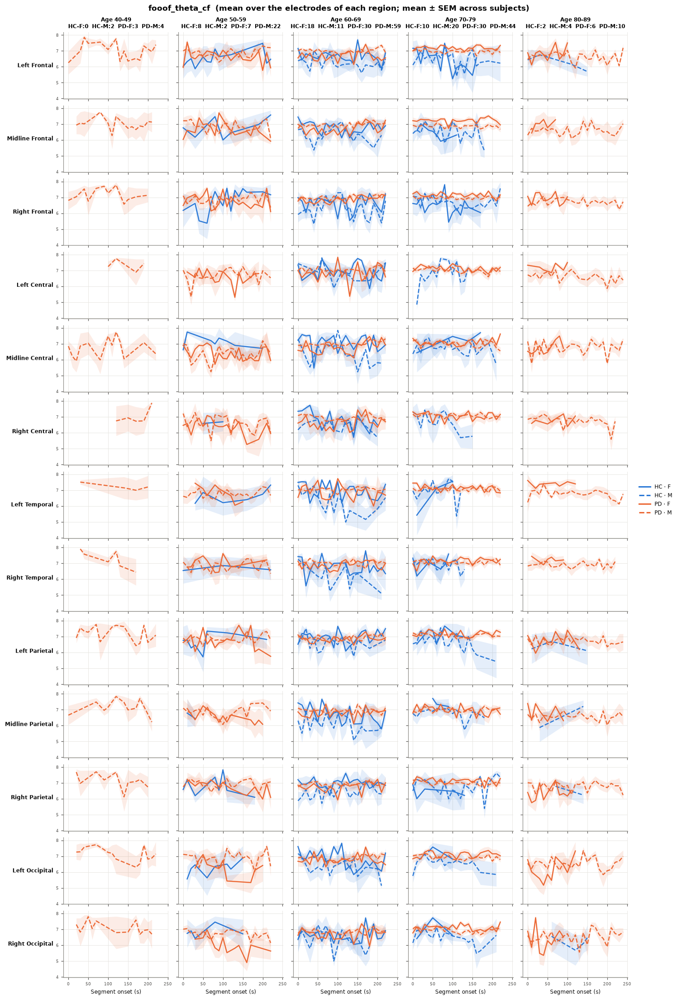

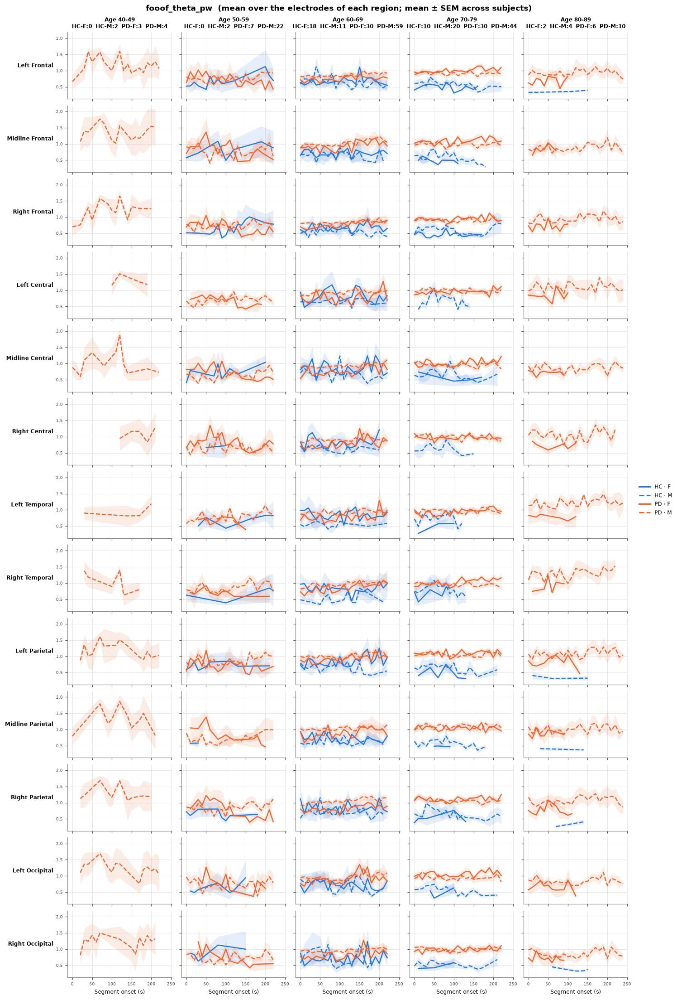

...

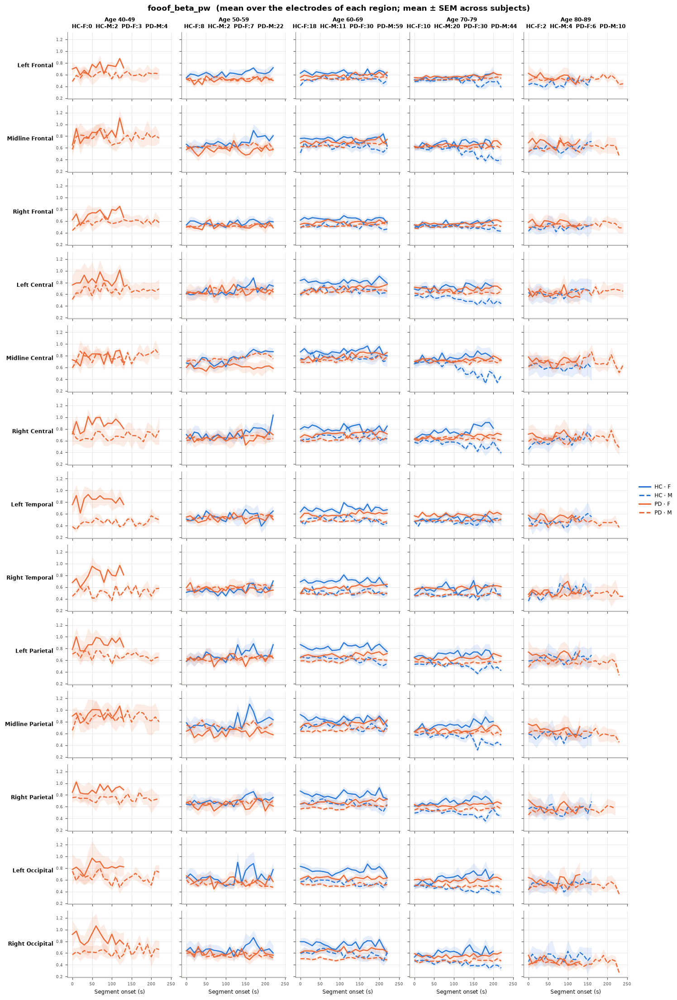

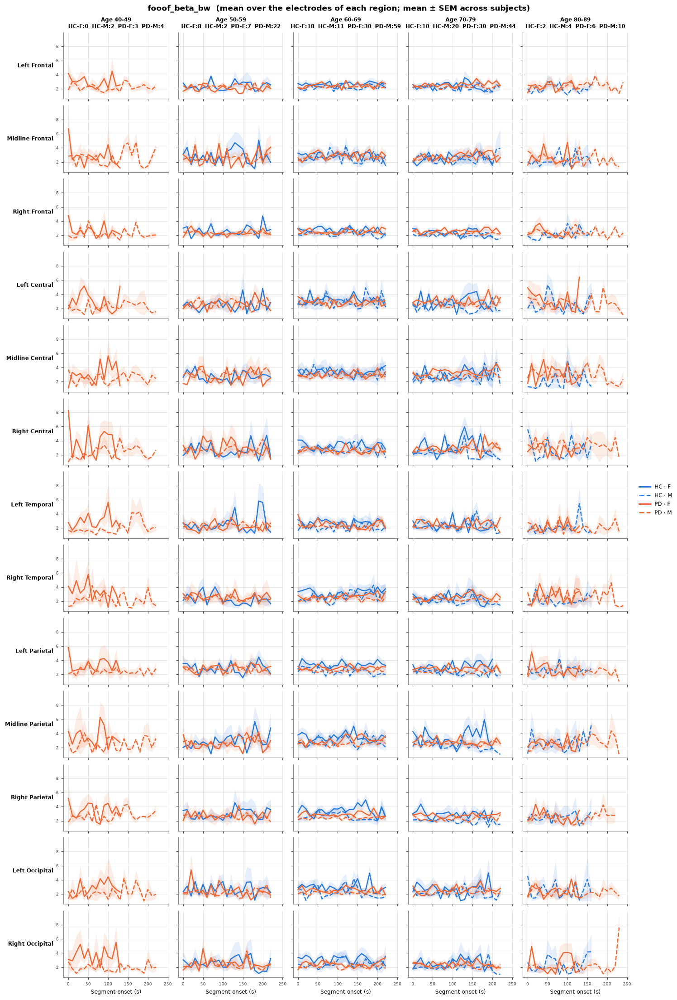

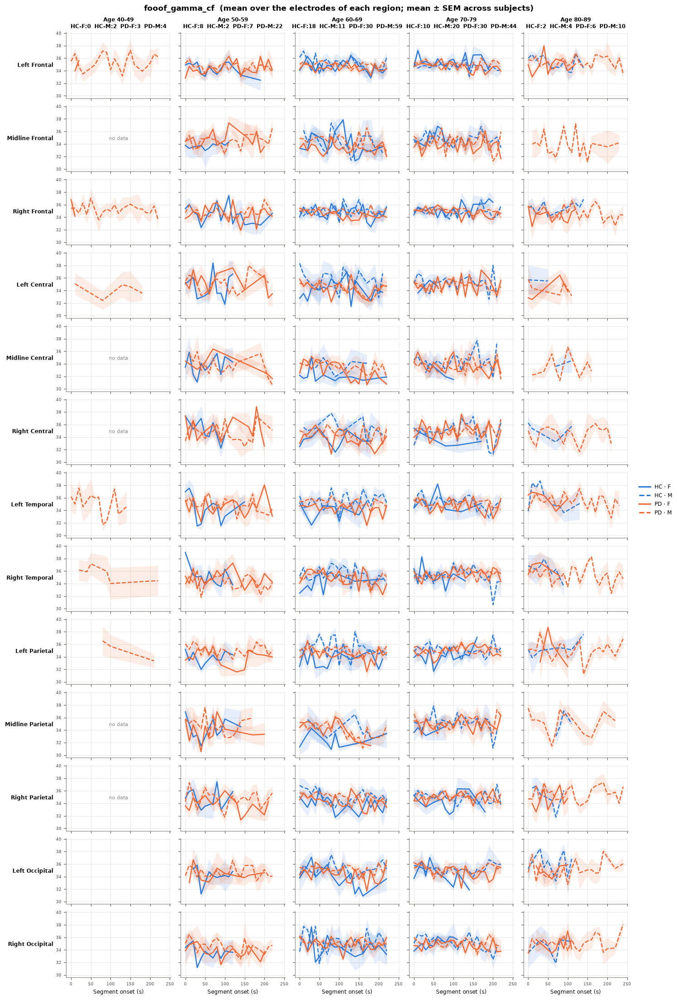

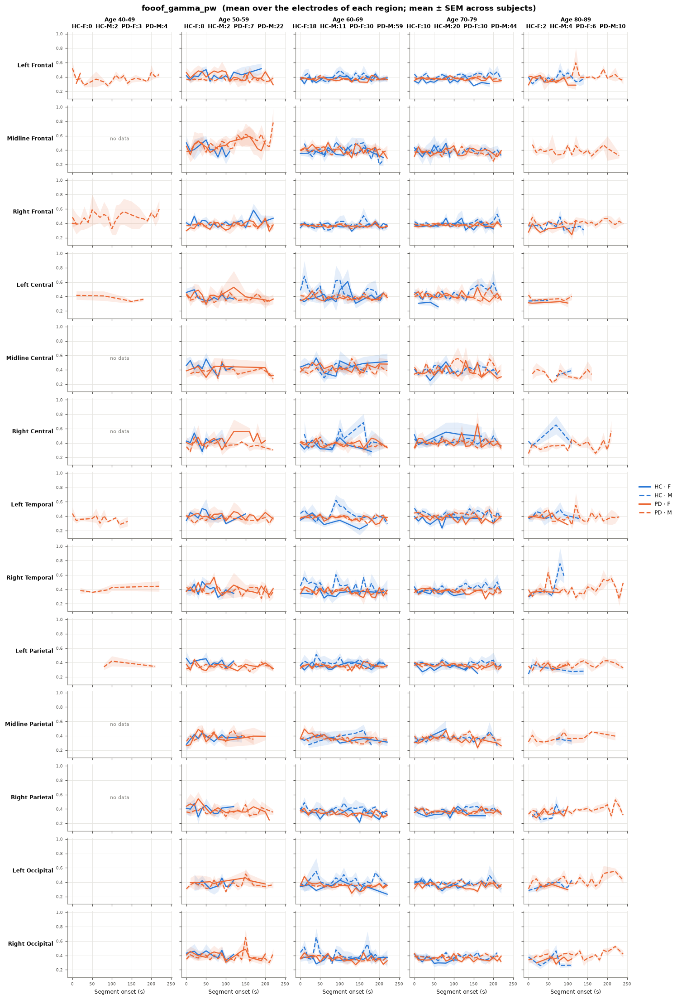

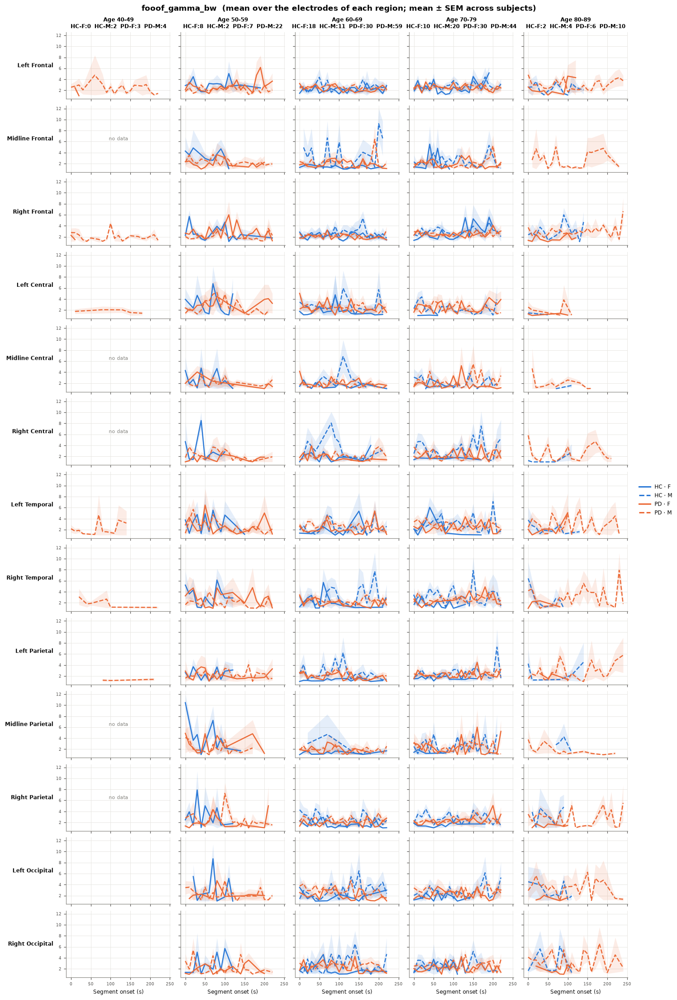


==============================  Quality control  ==============================


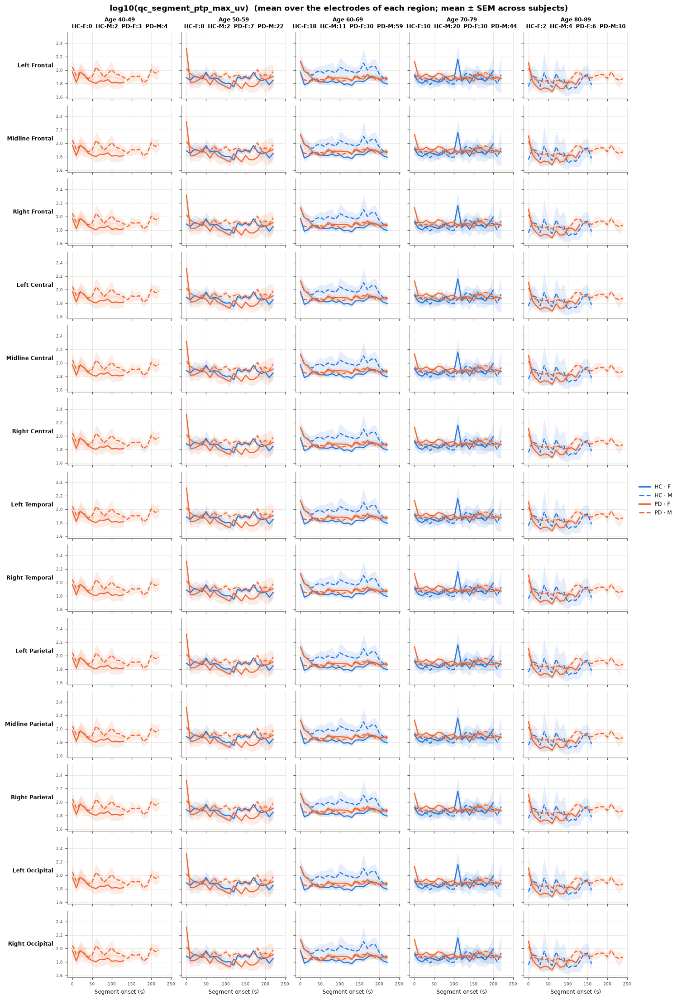

In [45]:
for family, features in FEATURE_FAMILIES.items():
    print(f'\n{"=" * 30}  {family}  {"=" * 30}')
    for feature in features:
        plot_feature_over_time(feature)

<div dir="rtl">

אותה פונקציה יכולה להתמקד באזור אחד או באלקטרודה בודדת. למשל, עוצמת האלפא חזקה במיוחד מעל האלקטרודות העורפיות:

</div>

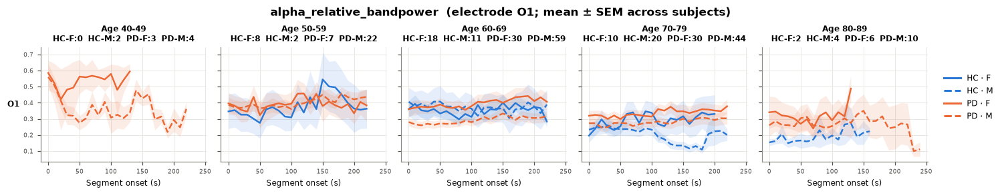

In [46]:
plot_feature_over_time('alpha_relative_bandpower', electrode='O1')

<div dir="rtl">

### 8.3 סיכום: מגמות בתוך נבדק לאורך הזמן

קשה להשוות את הגרפים שלמעלה על פני 27 פיצ'רים וכל אזורי המוח. כדי לסכם, לכל נבדק, אזור ופיצ'ר מתאימים קו ישר *ערך ~ זמן* על פני המקטעים של הנבדק, ושומרים את **השיפוע**. קודם מתקננים את הערכים ל־z-score (על כל המקטעים; log10 לפיצ'רים בעלי זנב כבד), כך שהשיפועים הם ב**סטיות תקן לדקה** וברי השוואה בין פיצ'רים.

1. סחף כללי: השיפוע החציוני על פני כל הנבדקים לכל פיצ'ר ואזור (* = מבחן Wilcoxon signed-rank מול 0, ‏FDR p < 0.05).
2. האם הסחף שונה בין חולים לבריאים? ‏*r* מסוג rank-biserial של השיפועים (* = FDR p < 0.05).
3. השיפוע הממוצע בכל תת־קבוצה (מין × קבוצה × עשור גילאים), heatmap אחת לכל אזור. מוצגות רק תתי־קבוצות עם לפחות `MIN_SUBJECTS_PER_POINT` נבדקים.

</div>

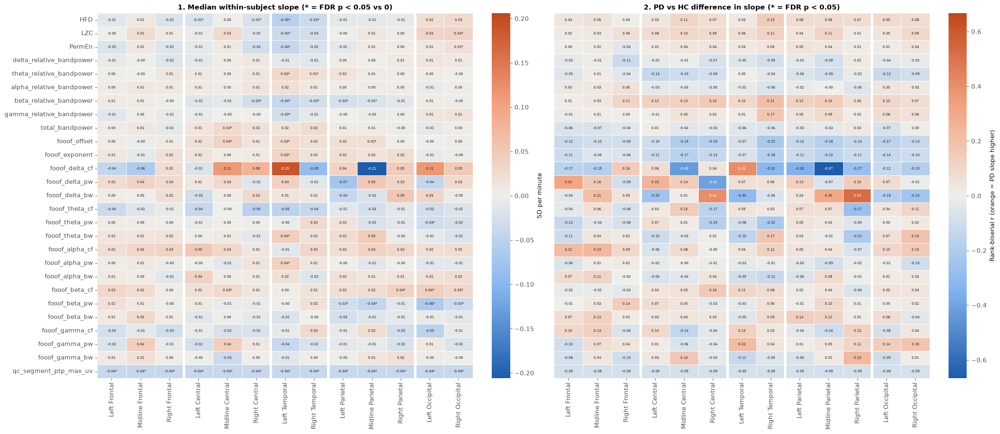

Feature-region cells with a significant overall drift: 45 / 351
Feature-region cells with a significant PD-vs-HC slope difference: 0 / 351


In [47]:
def nan_slopes(t: np.ndarray, Y: np.ndarray, min_points: int = 5) -> np.ndarray:
    """Least-squares slope of every column of Y against t, ignoring NaNs."""
    mask = ~np.isnan(Y)
    tt = np.where(mask, t[:, None], np.nan)
    t_c = tt - np.nanmean(tt, axis=0)
    y_c = Y - np.nanmean(Y, axis=0)
    slope = np.nansum(t_c * y_c, axis=0) / np.nansum(t_c ** 2, axis=0)
    slope[mask.sum(axis=0) < min_points] = np.nan
    return slope

z = region_segments.copy()
for col in z.columns:
    if col[1] in LOG_FEATURES:
        z[col] = np.log10(z[col].where(z[col] > 0))
z = (z - z.mean()) / z.std()
minutes = (full_df[TIME_COL] / 60).to_numpy()

slopes = pd.DataFrame(
    {sid: nan_slopes(minutes[full_df.index == sid], z.loc[[sid]].to_numpy()) for sid in subjects_df.index},
    index=z.columns).T
slope_meta = subjects_df.loc[slopes.index, ['group', 'sex', 'age_bin']]
slope_is_pd = (slope_meta['group'] == 'PD').to_numpy()

drift_median = pd.DataFrame(index=FEATURES_ORDERED, columns=REGION_ORDER, dtype=float)
drift_p = drift_median.copy()
for reg in REGION_ORDER:
    for f in FEATURES_ORDERED:
        s = slopes[(reg, f)].dropna()
        drift_median.loc[f, reg] = s.median()
        drift_p.loc[f, reg] = stats.wilcoxon(s).pvalue
drift_q = pd.DataFrame(bh_fdr(drift_p.to_numpy().ravel()).reshape(drift_p.shape), index=FEATURES_ORDERED, columns=REGION_ORDER)
slope_r, slope_q = effect_grid(slopes, lambda f, reg: (reg, f), FEATURES_ORDERED, REGION_ORDER, slope_is_pd, ~slope_is_pd)

fig, axes = plt.subplots(1, 2, figsize=(22, 9.5), constrained_layout=True)
annotated_heatmap(drift_median, drift_q, '1. Median within-subject slope (* = FDR p < 0.05 vs 0)',
                  'SD per minute', axes[0], fontsize=5.5)
annotated_heatmap(slope_r, slope_q, '2. PD vs HC difference in slope (* = FDR p < 0.05)',
                  'Rank-biserial r (orange = PD slope higher)', axes[1], fontsize=5.5)
for ax in axes:
    add_lobe_separators(ax, REGION_ORDER)
axes[1].set_yticks([])
plt.show()

print(f'Feature-region cells with a significant overall drift: {(drift_q < 0.05).to_numpy().sum()} / {drift_q.size}')
print(f'Feature-region cells with a significant PD-vs-HC slope difference: {(slope_q < 0.05).to_numpy().sum()} / {slope_q.size}')

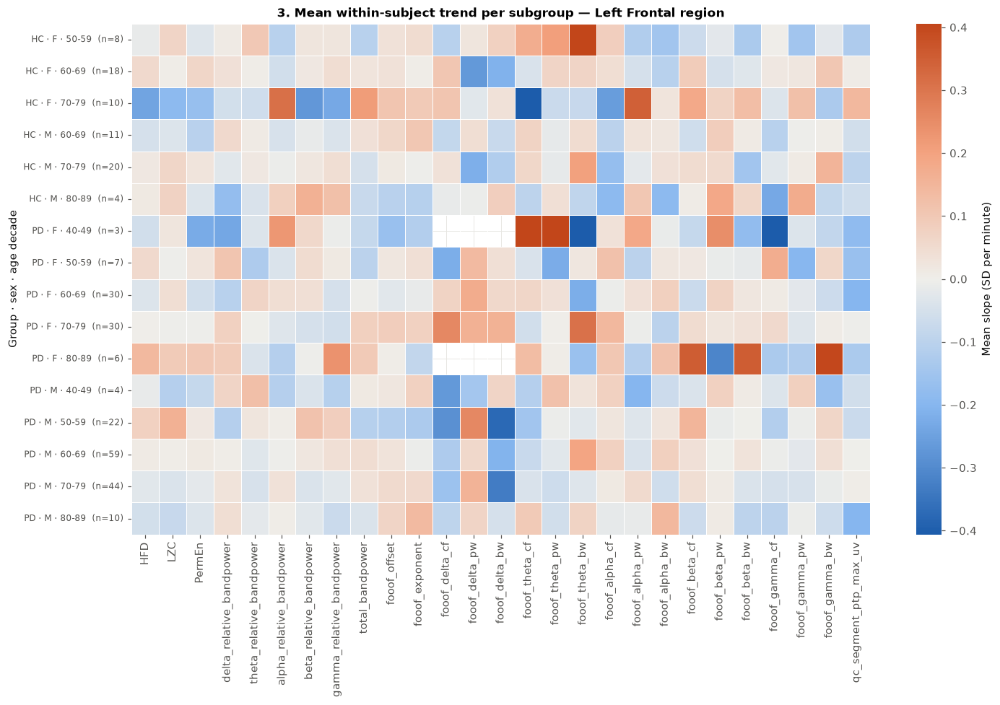

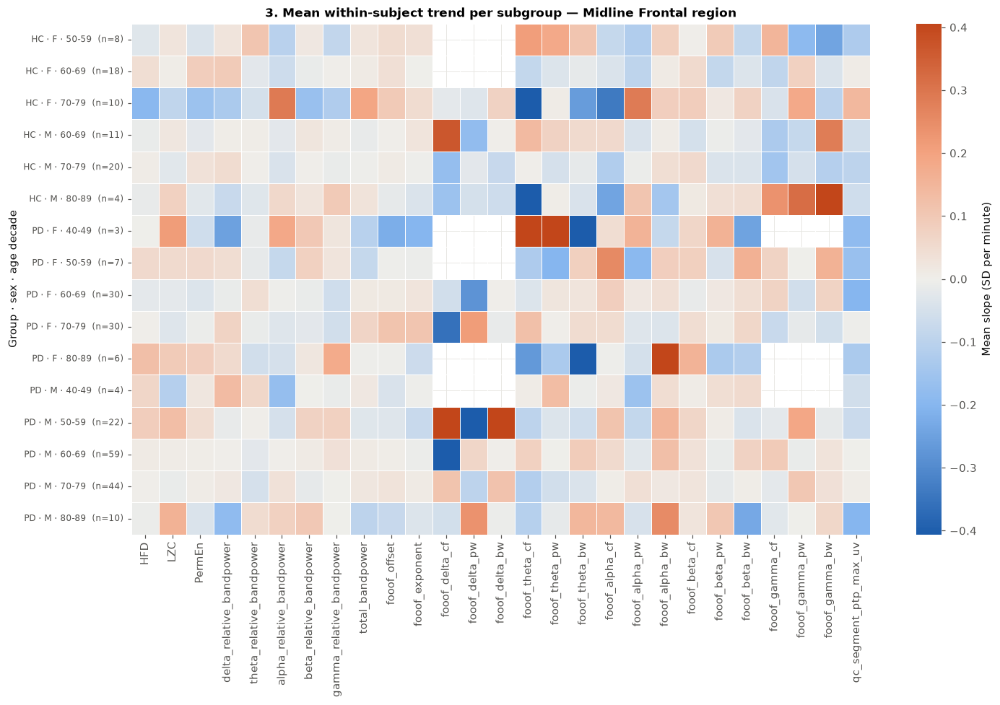

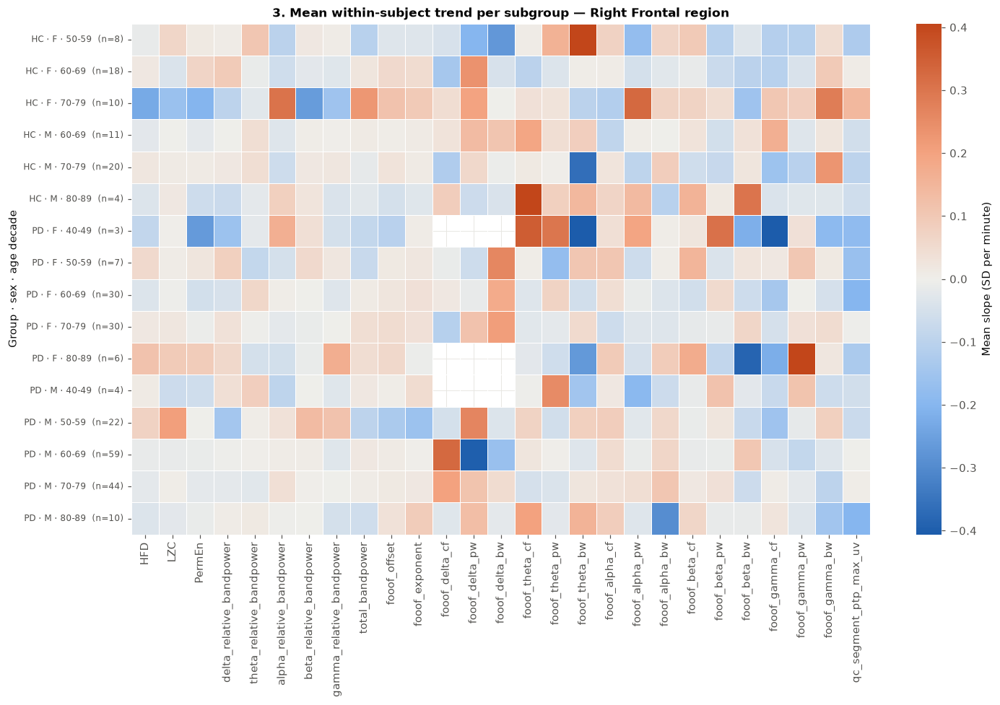

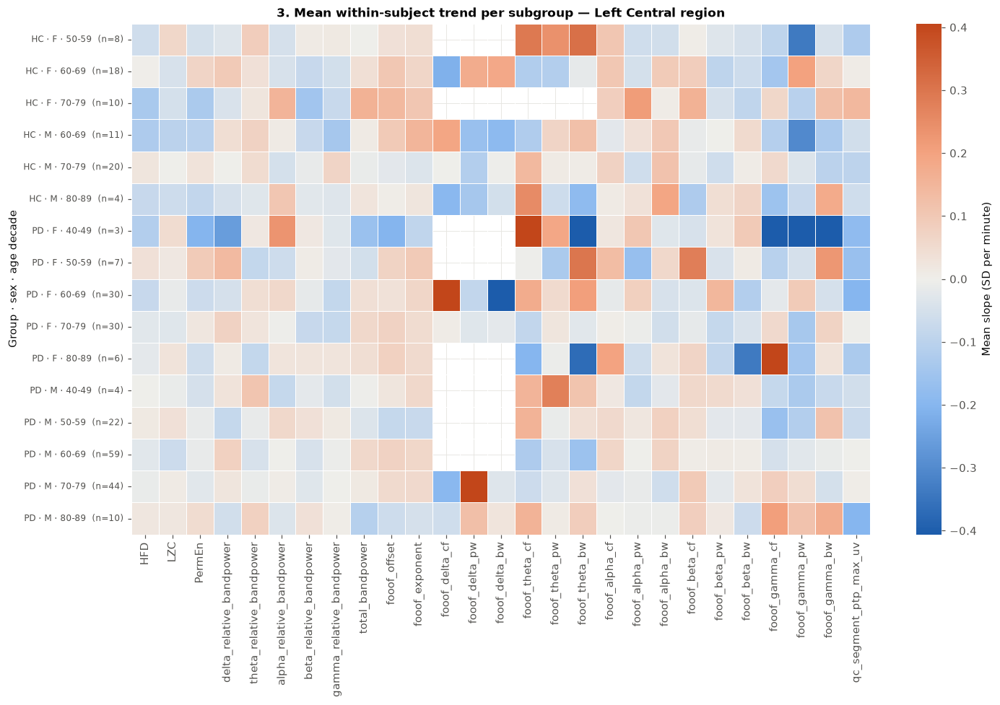

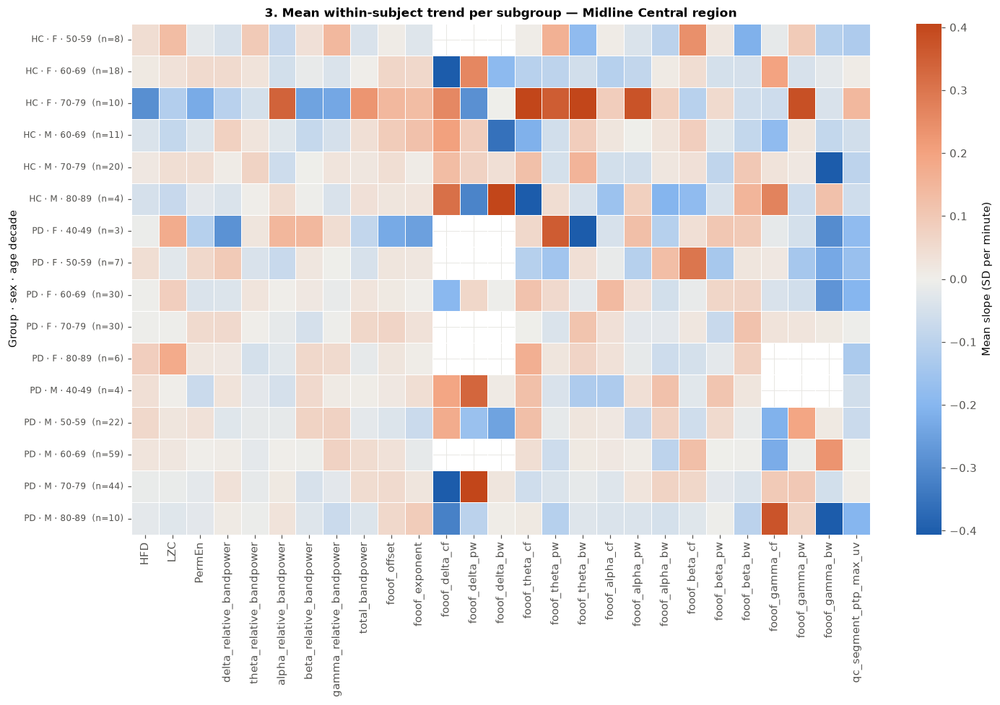

...

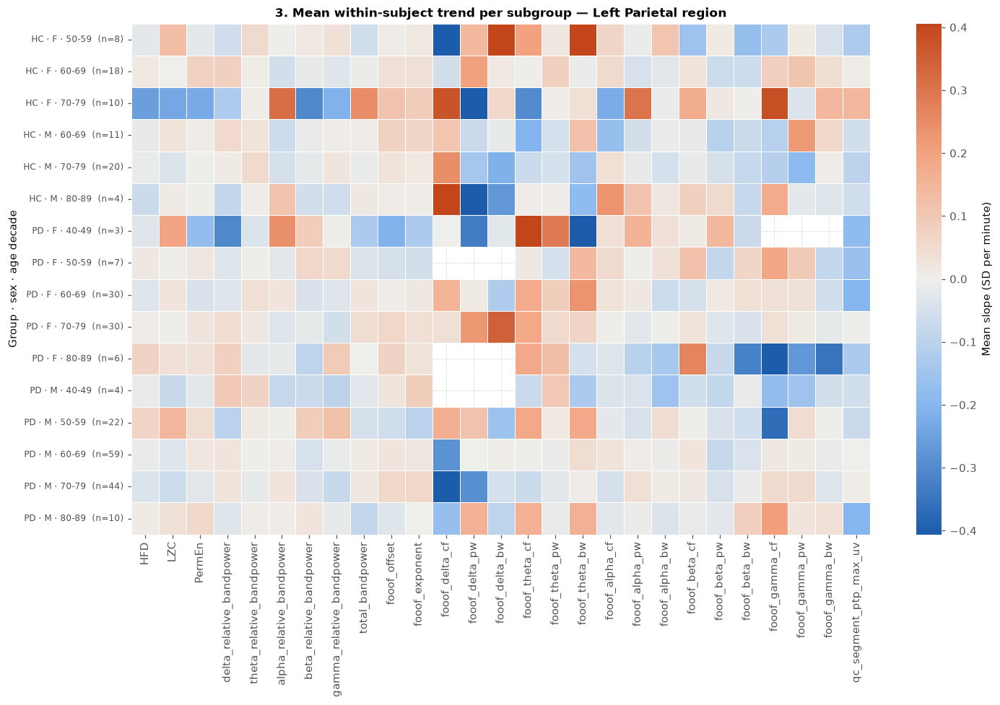

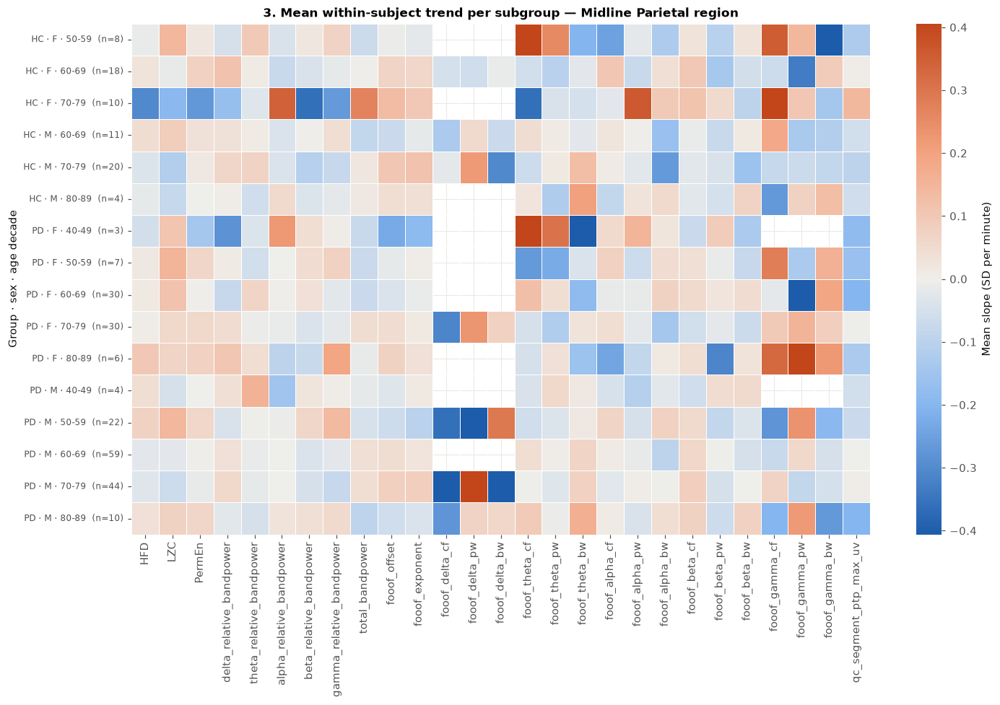

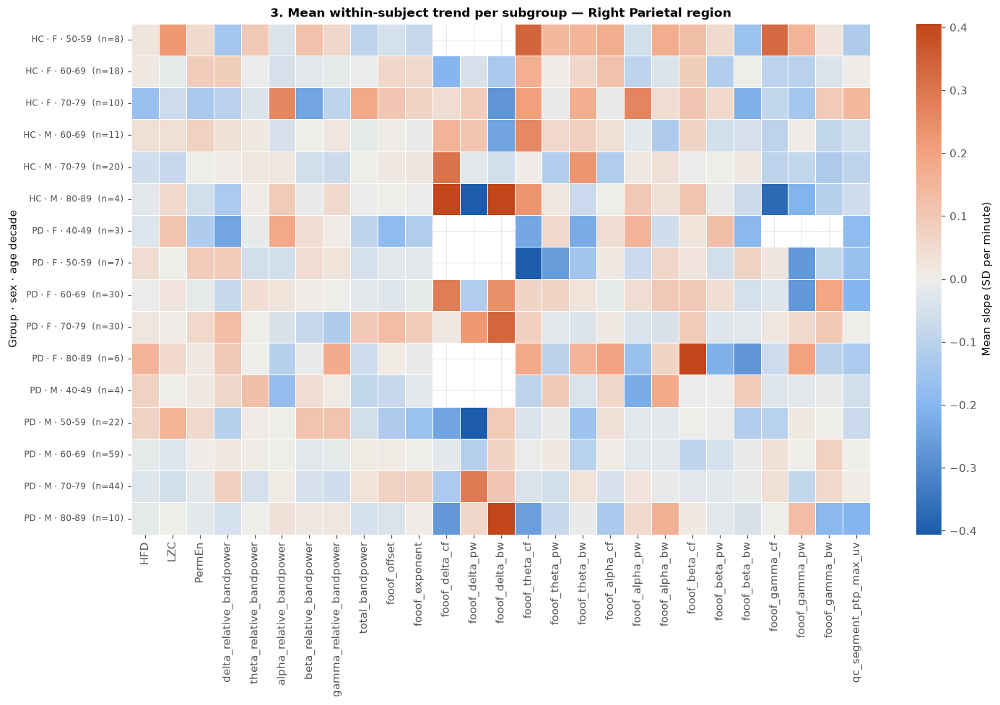

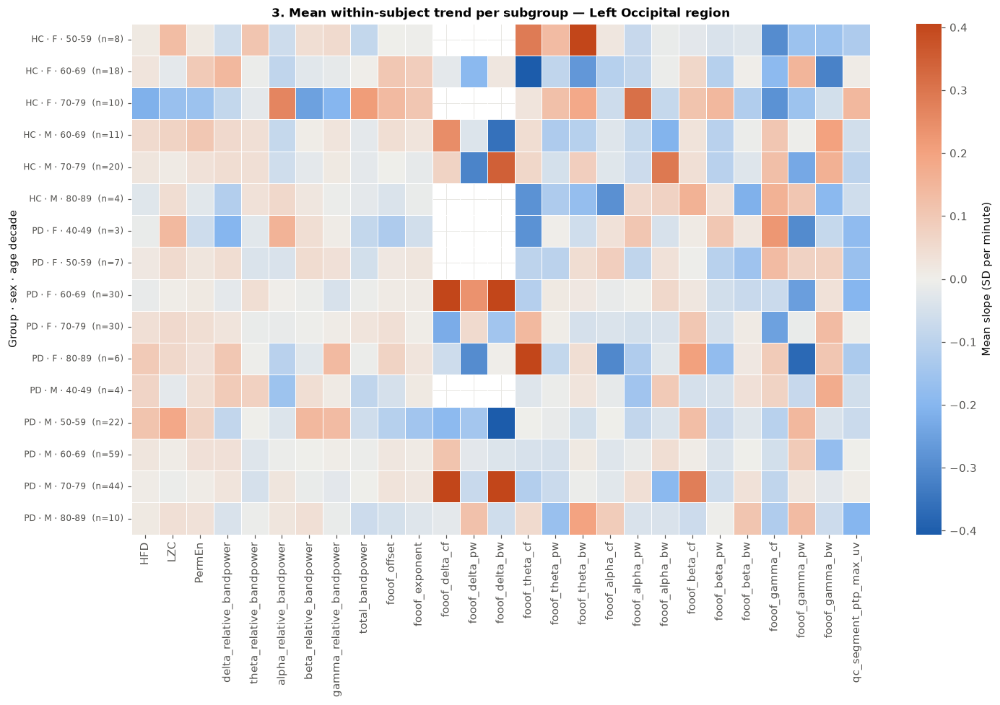

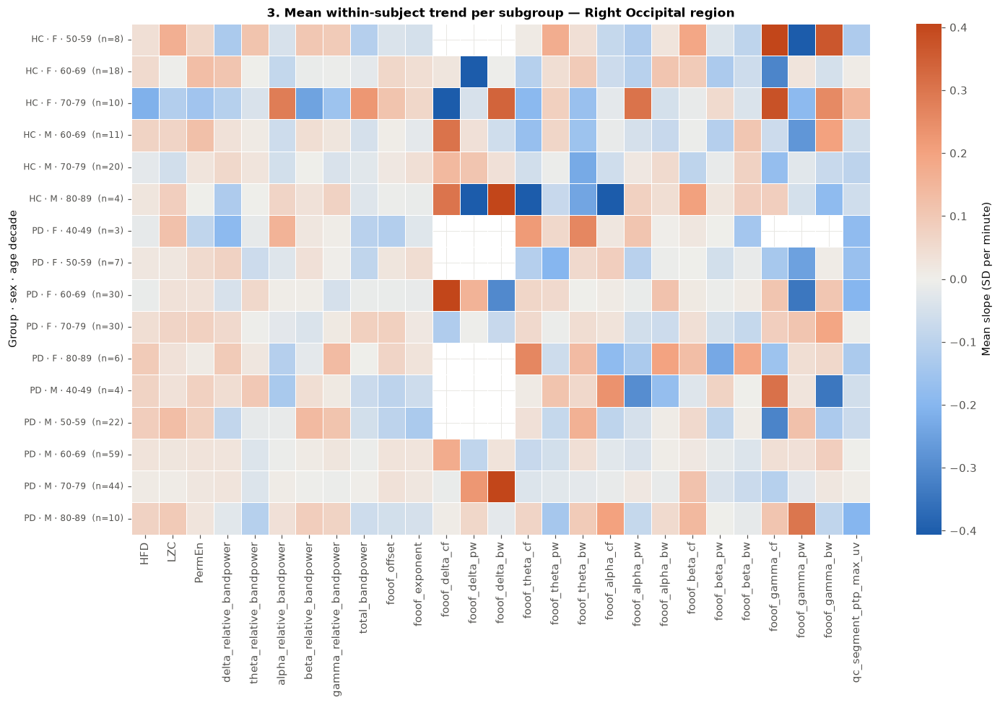

In [48]:
large_subgroups = subgroup_sizes[subgroup_sizes >= MIN_SUBJECTS_PER_POINT].index
subgroup_slopes = {reg: slopes[reg].join(slope_meta).groupby(['group', 'sex', 'age_bin'])[FEATURES_ORDERED].mean()
                   .reindex(large_subgroups) for reg in REGION_ORDER}
limit = np.nanpercentile(np.abs(np.concatenate([m.to_numpy().ravel() for m in subgroup_slopes.values()])), 98)
row_labels = [f'{g} · {s} · {a}  (n={subgroup_sizes[(g, s, a)]})' for g, s, a in large_subgroups]

for reg in REGION_ORDER:
    fig, ax = plt.subplots(figsize=(15, 0.36 * len(row_labels) + 2.6))
    sns.heatmap(subgroup_slopes[reg].set_axis(row_labels), cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit,
                linewidths=0.5, linecolor='white', cbar_kws={'label': 'Mean slope (SD per minute)'}, ax=ax)
    ax.set_title(f'3. Mean within-subject trend per subgroup — {reg} region')
    ax.set_ylabel('Group · sex · age decade')
    ax.tick_params(axis='y', labelsize=8)
    plt.show()

<div dir="rtl">

#### סיכום סעיף 8.3 — מה נבדק ואיך לקרוא את התוצאות

**השיטה.** לכל נבדק, לכל אזור ולכל פיצ'ר, מותאם קו ישר (ערך מתוקנן ~ זמן), ונשמר השיפוע שלו בסטיות תקן לדקה. השיפוע מחושב בתוך כל נבדק, כי בכל נקודת זמן מופיעים נבדקים אחרים. בנקודות המאוחרות נשארים רק נבדקי Iowa עם הקלטות ארוכות, ולכן ממוצע כללי לפי זמן היה מערבב שינוי אמיתי עם שינוי בהרכב הנבדקים.

**בדיקה 1, סחף כללי (מפה שמאלית).** מבחן Wilcoxon signed-rank. ‏H0: השיפועים מפוזרים באופן סימטרי סביב 0, כלומר אין מגמה שיטתית לאורך ההקלטה. ב־45 מתוך 351 הצירופים נמצא סחף מובהק, אבל הוא זניח: בדרך כלל עד כ־0.05 סטיות תקן לדקה. הסחף העקבי ביותר הוא ירידה בעמודת ה־QC, כלומר יותר ארטיפקטים בתחילת ההקלטה. **משמעות:** הנתונים יציבים בקירוב לאורך הזמן, ולכן מוצדק לסכם כל נבדק בממוצע על הזמן (סעיף 7).

**בדיקה 2, חולים מול בריאים (מפה ימנית).** מבחן Mann-Whitney U על השיפועים. ‏H0: התפלגות השיפועים זהה בשתי הקבוצות. אף צירוף לא מובהק אחרי FDR (ה־p המתוקן הקטן ביותר הוא כ־0.45). **משמעות:** המגמה לאורך ההקלטה לא מבדילה בין הקבוצות. המידע המבדיל נמצא ברמה הממוצעת של הפיצ'רים, ואין סחף שונה בין הקבוצות שהיה מעוות את הממוצעים.

**מפות תתי־הקבוצות.** אלה מפות תיאוריות, בלי מבחן סטטיסטי. השיפועים הבולטים מגיעים מתתי־קבוצות קטנות ובלי דפוס עקבי, ולכן נראים כמו רעש.

> **עוצמת הגוון לא מעידה על מובהקות.** הסקאלה של כל מפה נקבעת לפי ה־|r| הגבוה ביותר שבה, ולכן תמיד יהיו בה משבצות כתומות או כחולות כהות, גם כשאף אפקט אינו אמיתי. את המובהקות מסמנת רק הכוכבית. במפה הימנית יש שתי סיבות לפער בין הגוון למובהקות:
> * **המשבצות הכהות ביותר מבוססות על מעט מאוד נבדקים.** אלה פיצ'רי שיא הדלתא, ושיא דלתא זוהה רק בכ־7% מהמקטעים. לכן נכנסים לחישוב מעט נבדקים (למשל 6 חולים מול 10 בריאים), ו־r גבוה יכול לצאת במקרה.
> * **המשבצות הבינוניות לא שורדות את תיקון ה־FDR.** יש בהן הרבה נבדקים, אבל r קטן (עד כ־0.2). ב־351 מבחנים צפוי שכמה משבצות ייראו חזקות במקרה, והן אכן מפוזרות בלי דפוס עקבי.
>
> לשם השוואה, אפקט אמיתי נראה כמו התטא בסעיף 7.5: r של 0.4–0.5 על כל הנבדקים, ובאותו כיוון בכל האזורים.

**הסתייגויות.** נבדקה רק מגמה ליניארית, ושינוי לא ליניארי (למשל ירידה בדקה הראשונה ואחר כך יציבות) עלול להתפספס. בהקלטות קצרות השיפוע רועש יותר. ועם 293 נבדקים גם סחף זעיר יכול לצאת מובהק, ולכן חשוב להסתכל גם על גודל השיפוע.

</div>

<div dir="rtl">

---
## 9. סיכום הממצאים

*הממצאים מבוססים על הגרסה הנוכחית של הנתונים (293 נבדקים). אם הנתונים ישתנו, כדאי לבדוק אותם מחדש.*

**מבנה הנתונים**
* ב־`full_df` יש 293 נבדקים: 216 חולים ו־77 בריאים (יחס של כ־2.8 : 1). אחרי המיזוג יש 5,490 שורות (נבדק × מקטע של 10 שניות) ו־19 אלקטרודות × 27 סוגי פיצ'רים = 513 עמודות EEG. ההקלטות רצופות מ־0 שניות, ואין פערים או שורות כפולות.
* לפי קובץ המיפוי, 19 האלקטרודות מתחלקות ל־**13 אזורי מוח** (צד מוח × אונה). שבעה מהם מכילים אלקטרודה אחת בלבד (למשל `Midline Frontal` = Fz, ‏`Left Temporal` = T7). לכן ערך "אזורי" שלהם הוא בפועל ערך של אלקטרודה בודדת, ורועש יותר מאזור שממוצע על כמה אלקטרודות.
* `full_df` משלבת נבדקים משתי מעבדות (אתרים), Iowa ו־LEMON (ראו 4.3). אורך ההקלטה תלוי באתר: ב־LEMON כל ההקלטות באורך 230 שניות, וב־Iowa הן נעות בין 110 ל־330 שניות.

**נתונים קליניים**
* הגיל מאוזן בסך הכול (חציון 69 בבריאים מול 68 בחולים), אבל **לא בתוך כל אתר**: ב־Iowa הבריאים מבוגרים מהחולים, וב־LEMON הם צעירים מהם. גם המין לא מאוזן לגמרי (65% גברים בחולים מול 51% בבריאים, χ² p ≈ 0.04).
* ה־MoCA נמוך יותר אצל החולים (חציון 25 מול 27). UPDRS-III חסר לכל הבריאים ב־Iowa, והוא מקודד כמעט את התווית, ולכן אסור להשתמש בו כפיצ'ר.

**EEG — איכות הנתונים**
* ערכים חסרים מופיעים רק בפיצ'רי השיאים של FOOOF, ופירושם "לא זוהה שיא": δ ‏93%, γ ‏62%, θ ‏53%, α ‏15%, β ‏3%. החוסר נושא מידע: למשל, שיא תטא נמצא הרבה יותר אצל החולים (46% חסר) מאשר אצל הבריאים (72% חסר).
* עמודת ה־QC זהה בכל האלקטרודות, כלומר היא עמודה אחת ברמת מקטע. כמה מקטעים, וכמה נבדקים עם משרעת חציונית מעל 200 µV, נראים כמו ארטיפקטים ומועמדים להסרה.
* `total_bandpower` בעל זנב כבד מאוד ודורש log. העוצמות היחסיות מסתכמות בדיוק ל־1. חלק גדול מפרמטרי FOOOF יושבים בגבולות ההתאמה.

**EEG — מאיפה מגיעה השונות (7.4)**
* בפיצ'רים המרכזיים (מורכבות, עוצמות יחסיות וכוללת, offset ו־exponent) רוב השונות היא בין נבדקים (כ־45–75%), והשונות בין אלקטרודות גדולה לפחות כמו השונות לאורך הזמן.
* בפרמטרי השיאים של FOOOF רוב השונות היא ממקטע למקטע (57–85%).
* לכן הסיכום ברמת נבדק הוא **ממוצע על הזמן לכל אלקטרודה**, ומשם ממוצע לכל אזור מוח.

**חולים מול בריאים — לפי אזורי המוח (7.5, 7.8)**
* **עליית התטא אצל החולים היא הממצא העקבי ביותר, ומופיעה בכל 13 האזורים.** גם העוצמה היחסית של תטא וגם עוצמת שיא התטא מובהקות בכל האזורים (r ≈ 0.35–0.52). האפקט החזק ביותר הוא ב־**Midline Frontal** (Fz, עוצמת שיא תטא r ≈ 0.52), ואחריו **האזורים הפריאטליים** (r ≈ 0.43–0.47) ו־**Right Occipital** (r ≈ 0.46).
* **ירידה בבטא ובמורכבות (HFD, LZC) מתרכזת באונות הפרונטלית, המרכזית והפריאטלית.** החזקה ביותר היא באזורים המרכזיים (למשל בטא ב־Right Central r ≈ −0.34, ‏HFD ב־Right Central r ≈ −0.33). באזורים הטמפורליים והעורפיים היא חלשה יותר, ובחלקם לא מובהקת (HFD ו־LZC לא מובהקים באונה העורפית ולא ב־Left Temporal).
* **ירידה בתדר שיא האלפא היא בעיקר אחורית:** מובהקת באונות הפריאטלית והעורפית (r ≈ −0.19 עד −0.27) וב־Left Central, ולא באונה הפרונטלית.
* **העוצמה הכוללת וה־offset של FOOOF גבוהים יותר אצל החולים כמעט בכל האזורים.** בעוצמה הכוללת האפקט החזק ביותר הוא ב־Right Occipital וב־Midline Frontal (r ≈ 0.28–0.29).
* **מספר הפיצ'רים המובהקים לכל אזור:** מ־5 ב־Left Temporal ועד 12 ב־Right Central. האזורים הטמפורליים והעורפיים מבדילים בין הקבוצות פחות מהפרונטליים, המרכזיים והפריאטליים.
* **בין שמאל לימין אין הבדל עקבי (לטרליזציה).** הערכים בצד שמאל ובצד ימין של כל אונה דומים, כך שהאפקטים נראים סימטריים.
* **יתירות:**
  * בין פיצ'רים באותה אלקטרודה הקורלציות גבוהות: עוצמה יחסית של אלפא מול עוצמת שיא אלפא ρ ≈ 0.94, ‏HFD מול עוצמה יחסית של גמא ρ ≈ 0.93.
  * בין אלקטרודות של אותו פיצ'ר: בעוצמות ובמורכבות הקורלציה גבוהה (ρ ≈ 0.7–0.9), ולכן ממוצע לפי אזור מאבד מעט. בשיאי FOOOF היא נמוכה (ρ ≈ 0.3–0.5).

**אפקט האתר — לפי אזורי המוח (7.7)**
* **אפקט האתר קיים בכל 13 האזורים, ובכל אחד מהם הוא גדול מההבדל בין חולים לבריאים.** החציון של |r| בין האתרים (בתוך אותה קבוצה) הוא 0.19–0.33 לפי אזור, לעומת 0.11–0.19 בהבדל בין חולים לבריאים.
* הפיצ'רים שמושפעים הכי הרבה מהאתר הם מדדי המורכבות (HFD, LZC, PermEn), עוצמת הגמא ועוצמת האלפא (יחסית ושיא), והם מושפעים בכל האזורים.
* יחד עם יחס החולים לבריאים ודפוס הגילאים, שגם הם שונים בין האתרים, מודל עלול ללמוד "אתר" במקום "מחלה". צריך לטפל באתר במפורש: למשל ולידציה מסוג leave-one-site-out או מרובדת לפי אתר, או הרמוניזציה ונרמול בתוך כל אתר.

**התנהגות לאורך הזמן (סעיף 8)**
* רוב הפיצ'רים יציבים לאורך ההקלטה בכל האזורים. ב־45 מתוך 351 צירופים של פיצ'ר × אזור יש סחף מובהק על פני הנבדקים, אבל הוא זניח: בדרך כלל עד כ־0.05 סטיות תקן לדקה. החריג היחיד הוא תדר שיא הדלתא, שנמדד על מעט מאוד שיאים. הסחף העקבי ביותר הוא של משרעת ה־QC, שגבוהה מעט בתחילת ההקלטה בכל האזורים.
* באף צירוף של פיצ'ר × אזור המגמה לא שונה באופן מובהק בין חולים לבריאים. השיפועים הגדולים במפות של תתי־הקבוצות מגיעים מתתי־קבוצות קטנות ונראים כמו רעש. לכן אפשר להתייחס למקטעים כאל מדידות חוזרות, בקירוב סטציונריות, של אותו נבדק.

**השלכות לשלב המודלים**
* מקטעים של אותו נבדק אינם בלתי תלויים. כל חלוקה ל־train/test חייבת להיות **לפי נבדק** (למשל `GroupKFold`), אחרת הביצועים יהיו מנופחים מאוד.
* **רמת הפירוט המרחבית:** אפשר לעבוד לפי אלקטרודה (513 עמודות), לפי 13 האזורים (351 עמודות) או לפי אונה. בגלל הקורלציה הגבוהה בין אלקטרודות בפיצ'רים המרכזיים, סיכום אזורי צפוי לאבד מעט מידע ולהקטין מאוד את מספר הפיצ'רים.
* **החלטות שנשארו פתוחות לפני המודלים:** טיפול במקטעים עם ארטיפקטים, השלמה של שיאי FOOOF מול שימוש במדד חוסר, הסרת פיצ'רים יתירים, וטיפול באתר, בגיל ובמין.

</div>